In [ ]:
%pip install -q lightgbm

In [ ]:
%pip install -q catboost

In [ ]:
%pip install -q optuna lightgbm

In [ ]:
from google.colab import files
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import numpy as np
from scipy.stats import chi2
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    log_loss,
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)
from sklearn.model_selection import StratifiedKFold, cross_validate
import lightgbm as lgb
from catboost import CatBoostClassifier
from google.colab import drive
from pathlib import Path
import joblib
import optuna
from sklearn.base import clone
import shutil
import sqlite3
from sklearn.model_selection import cross_val_score
import shap
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve

In [ ]:
# zipファイルをアップロード
uploaded = files.upload()

Saving playground-series-s6e10.zip to playground-series-s6e10.zip


In [ ]:
# zipファイルを解凍する
zip_path = "/content/playground-series-s6e10.zip"
extract_path = "/content/kaggle_airline_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIPファイルの解凍が完了しました。")
print(os.listdir(extract_path))

ZIPファイルの解凍が完了しました。
['train.csv', 'sample_submission.csv', 'test.csv']


In [ ]:
# ファイルの中身確認
train = pd.read_csv(
    "/content/kaggle_airline_data/train.csv"
)

test = pd.read_csv(
    "/content/kaggle_airline_data/test.csv"
)

sample_submission = pd.read_csv(
    "/content/kaggle_airline_data/sample_submission.csv"
)

print("訓練データ:", train.shape)
print("テストデータ:", test.shape)
print("提出形式:", sample_submission.shape)

display(train.head())

訓練データ: (699635, 23)
テストデータ: (299844, 22)
提出形式: (299844, 2)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


## EDA

In [ ]:
# 訓練データの中身確認
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [ ]:
# object型の説明変数の中身確認
cat_cols = train.select_dtypes(include=["object"]).columns.tolist()

for col in cat_cols:
    print(f"\n【{col}】")
    print(train[col].value_counts(dropna=False))


【Gender】
Gender
Male      351683
Female    347952
Name: count, dtype: int64

【Customer Type】
Customer Type
Loyal Customer       576990
disloyal Customer    122645
Name: count, dtype: int64

【Type of Travel】
Type of Travel
Business travel    497441
Personal Travel    202194
Name: count, dtype: int64

【Class】
Class
Business    342212
Eco         327404
Eco Plus     30019
Name: count, dtype: int64


In [ ]:
# 訓練データの欠損値確認
train.isnull().sum()

,0
id,0
Age,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0
Food and drink,0
Online boarding,0
Seat comfort,0


- Arrival Delay in Minutes に欠損値292個を確認

In [ ]:
# 数値データの基本統計量
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


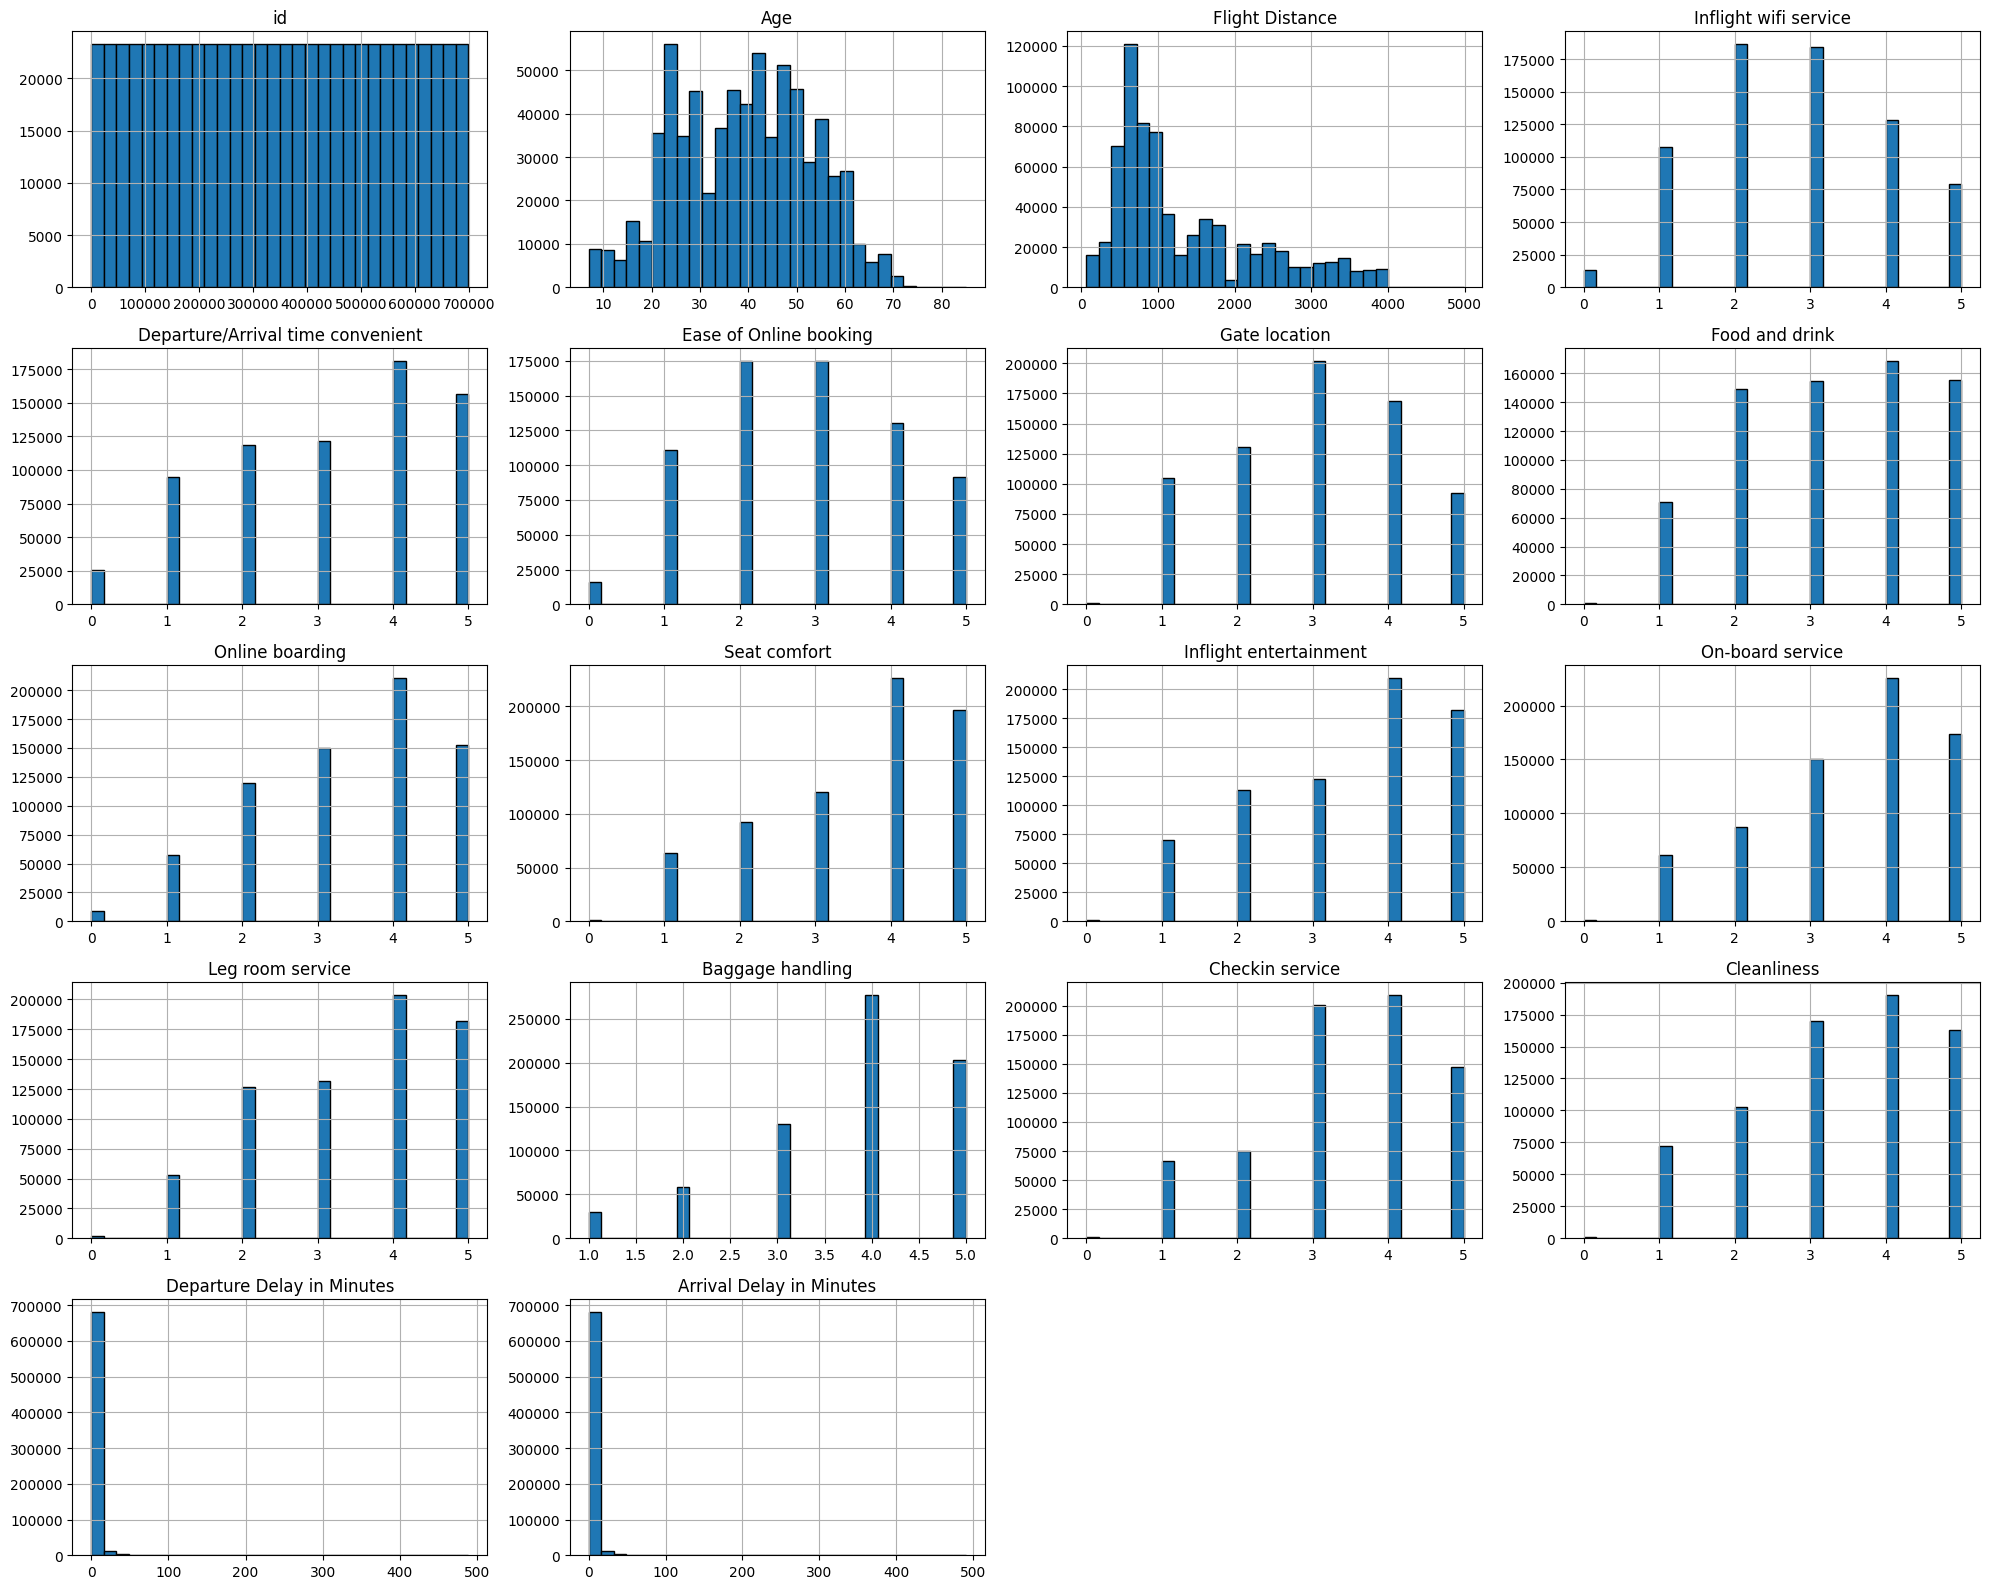

In [ ]:
# 数値型の説明変数をヒストグラムで可視化
train.hist(
    figsize=(20, 16),
    bins=30,
    layout=(5, 4),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

- 20～60代を中心に分布
- 飛行距離は短距離の利用者が多く、右側に長い分布

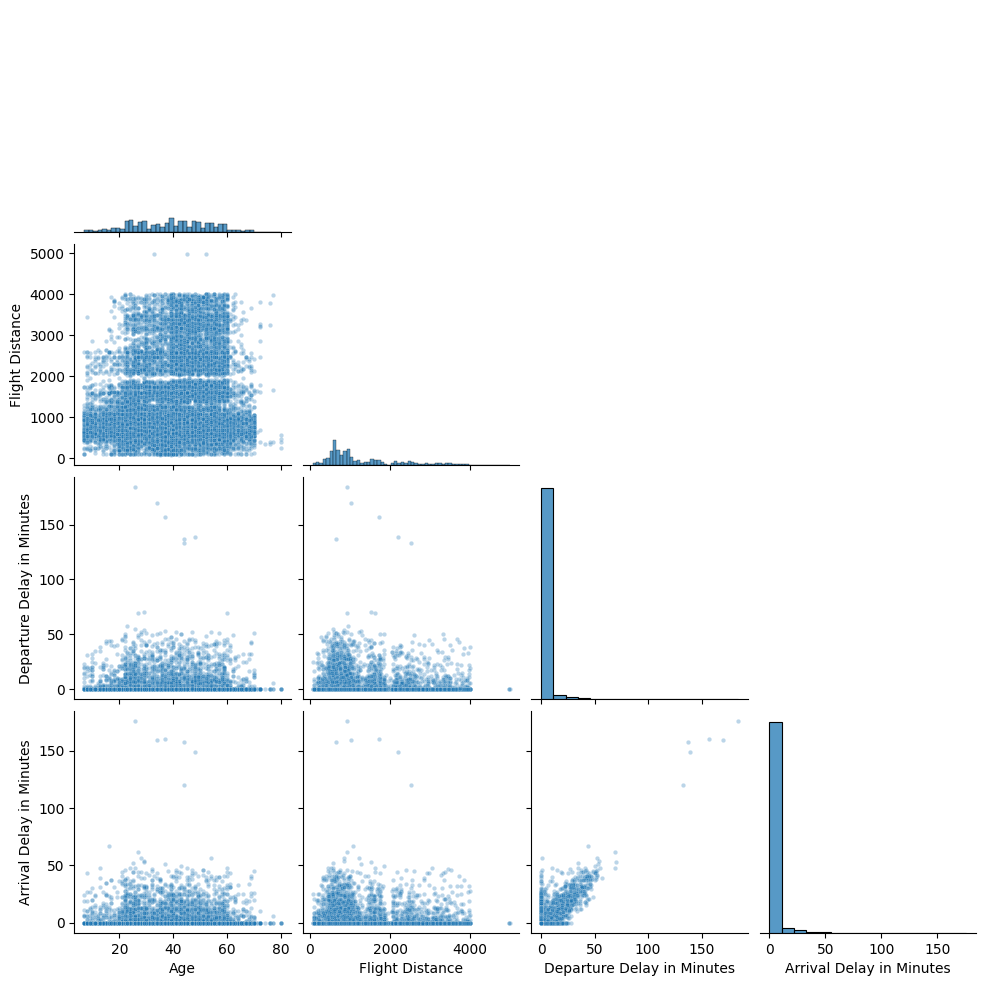

In [ ]:
# 連続変数同士で散布図を確認
cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

sample = train[cols].sample(n=20000, random_state=42) # サンプル数は2万件に指定

sns.pairplot(
    sample,
    corner=True,
    plot_kws={"alpha": 0.3, "s": 10}
)

plt.show()

- 出発遅延時間と到着遅延時間には強い正の相関がある(当然)

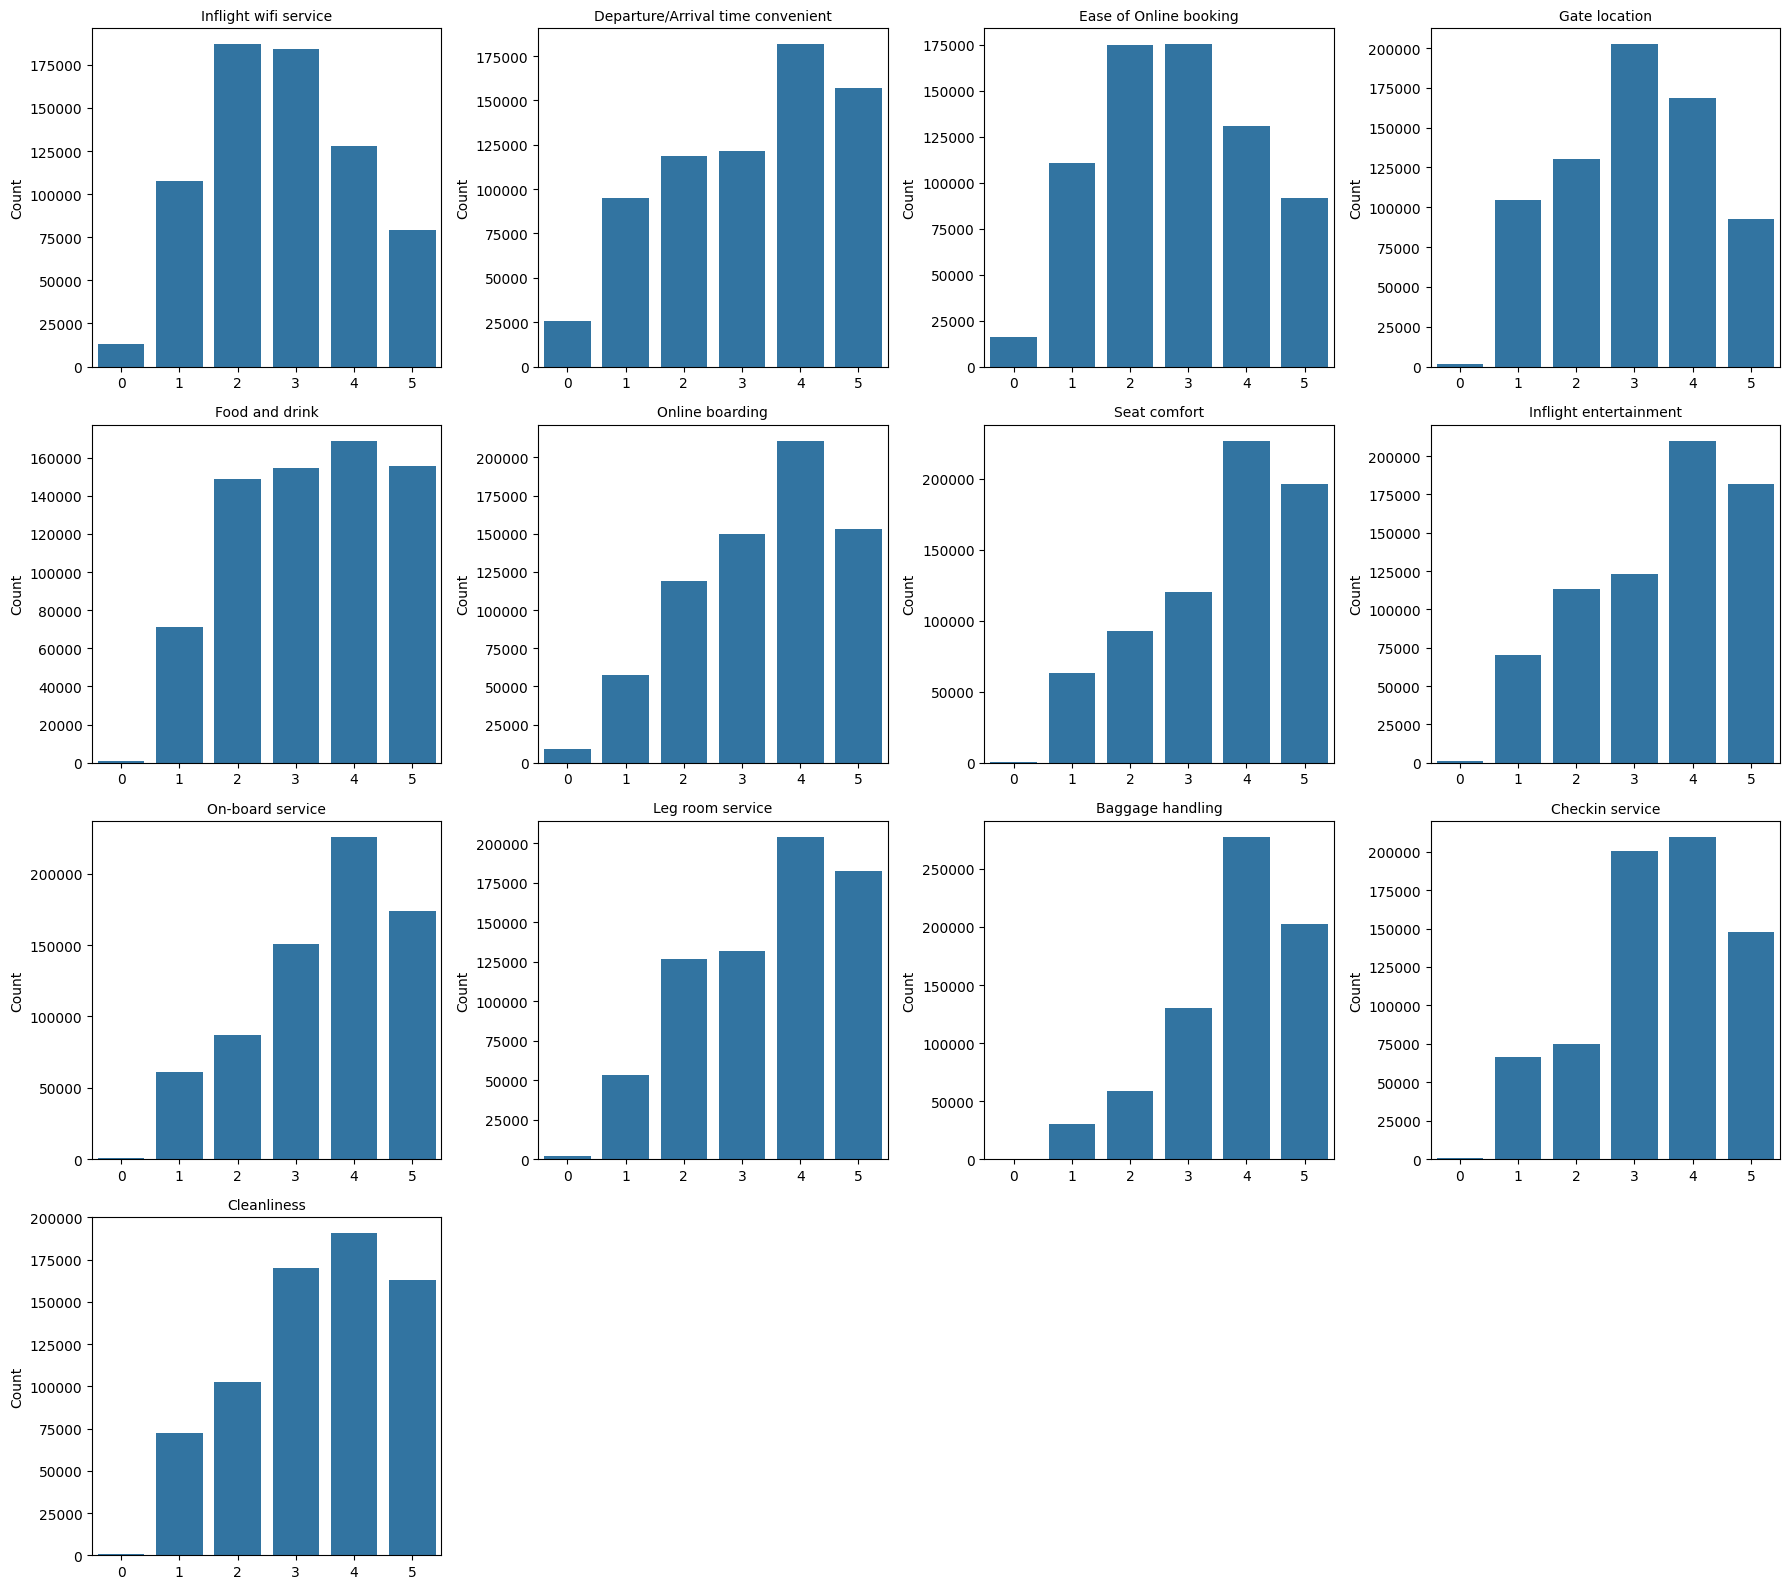

In [ ]:
# 離散変数の棒グラフを表示
rating_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for ax, col in zip(axes.flat, rating_cols):
    sns.countplot(
        data=train,
        x=col,
        order=[0, 1, 2, 3, 4, 5],
        ax=ax
    )
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

for ax in axes.flat[len(rating_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

5段階評価項目の分布分析

13項目のサービス評価について棒グラフを作成し、回答分布を確認した。

多くの項目で評価4・5の回答が多く、特に座席の快適さ、機内エンターテインメント、機内サービス、手荷物の取り扱いなどは高評価に偏る傾向が確認された。

一方、機内Wi-Fiサービスおよびオンライン予約のしやすさでは、評価2・3の回答が比較的多く、他のサービス項目とは異なる分布が確認された。

これらの結果から、デジタル関連サービスには改善余地がある可能性が考えられる。

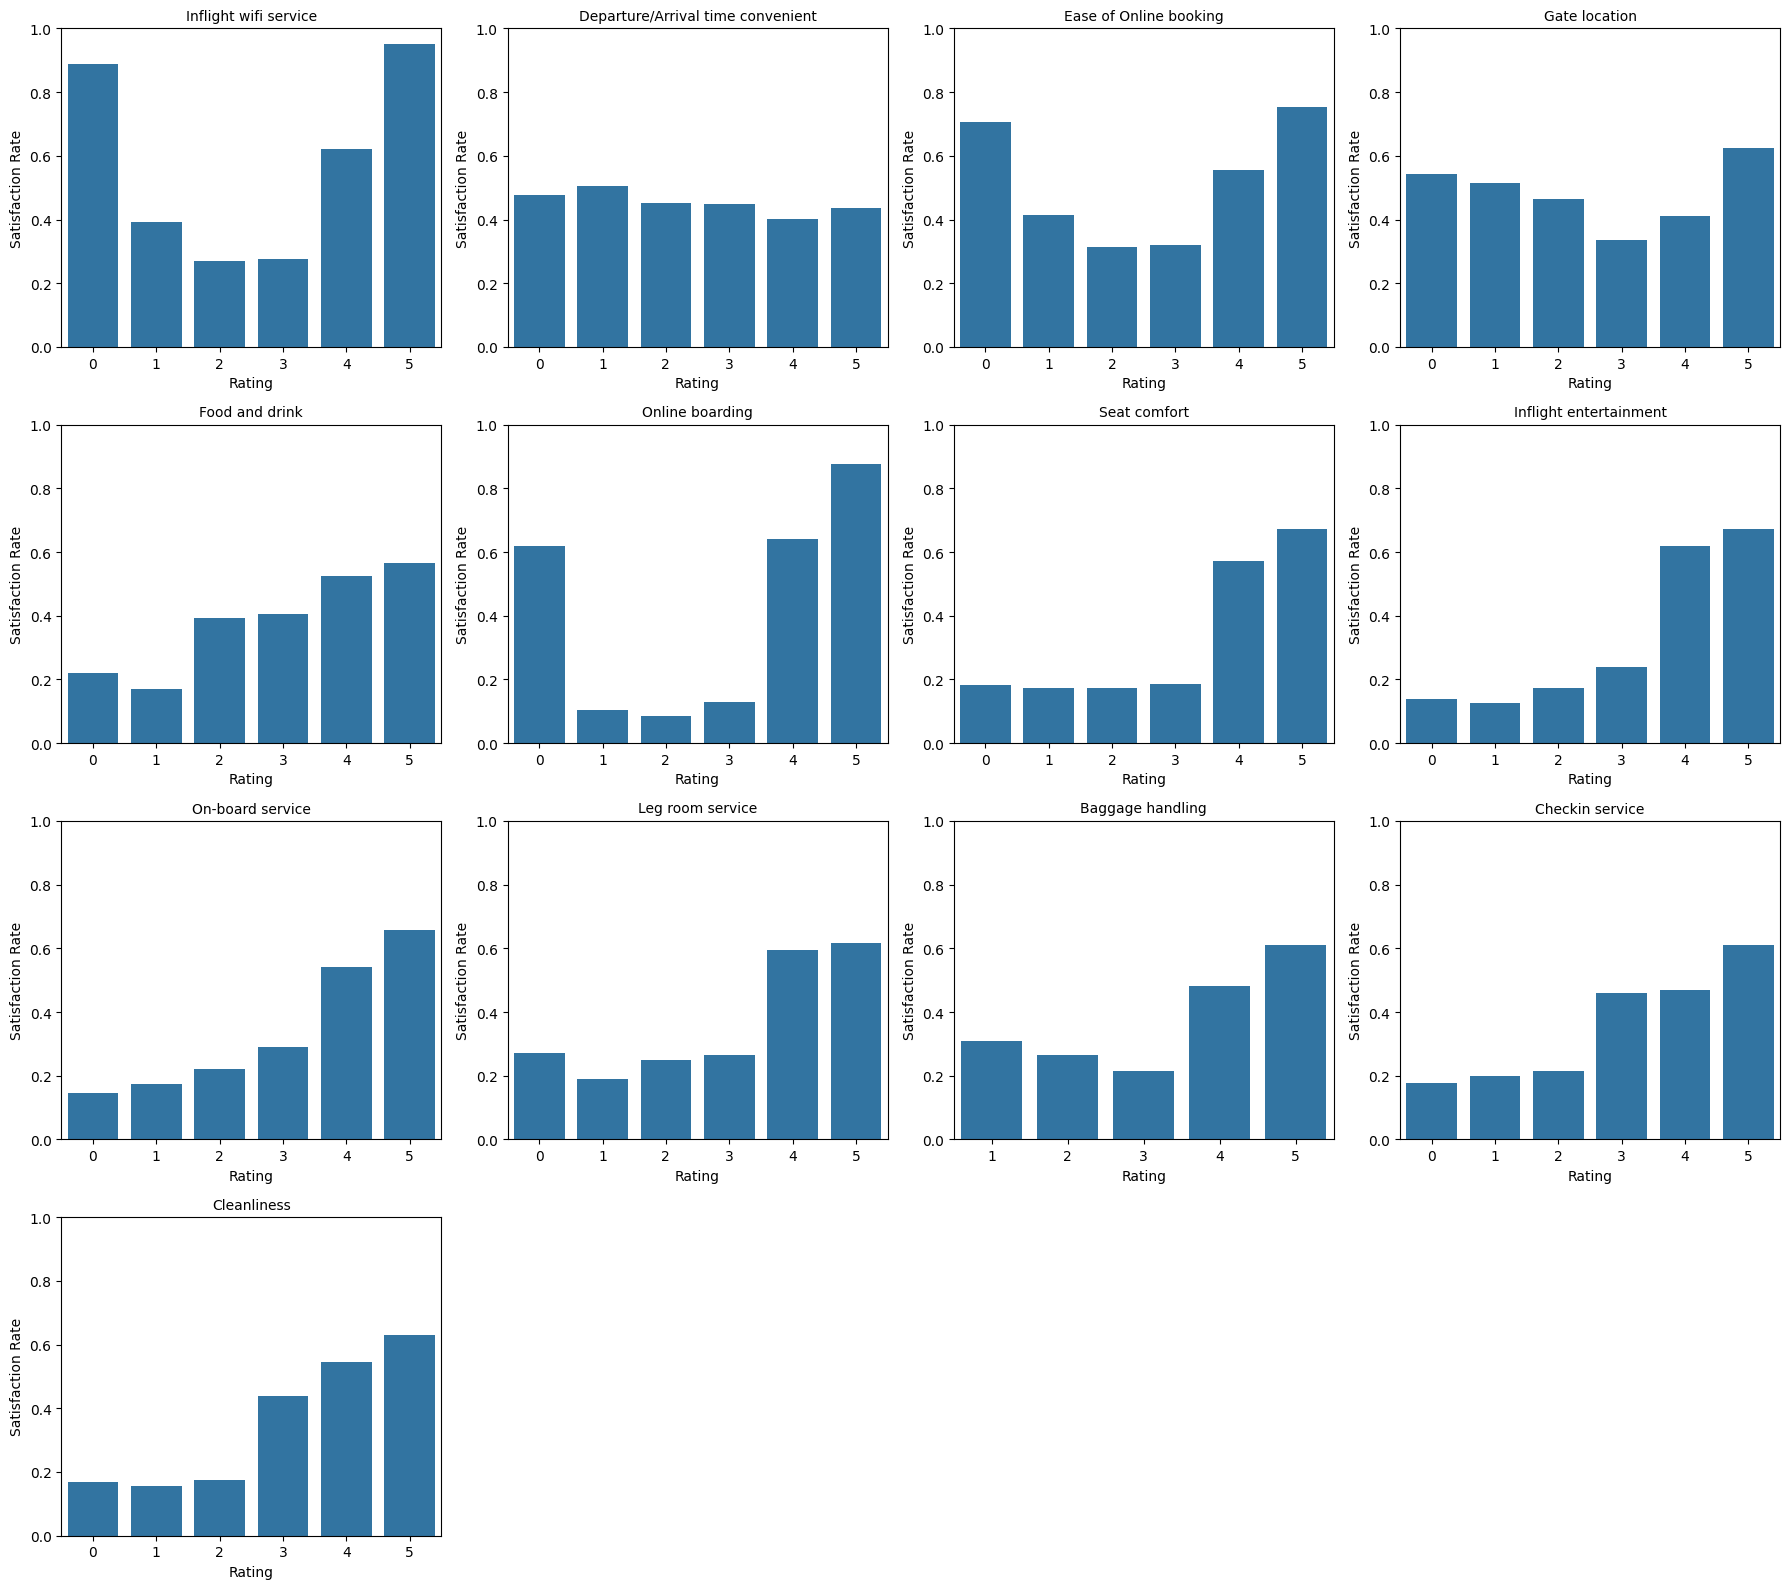

In [ ]:
# サービス評価別の顧客満足率
fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for ax, col in zip(axes.flat, rating_cols):

    satisfaction_rate = (
        train.groupby(col)["satisfaction"]
        .agg(["mean", "count"])
        .reset_index()
    )

    sns.barplot(
        data=satisfaction_rate,
        x=col,
        y="mean",
        ax=ax
    )

    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Rating")
    ax.set_ylabel("Satisfaction Rate")
    ax.set_ylim(0, 1)

for ax in axes.flat[len(rating_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

満足率で、Inflight wifi service と Ease of Online booking と Gate location と Online boarding に関して評価0なのに顧客満足率が高い現象が発生している。

- 考えられる3つの仮説
  - ほかのサービスの評価が高く、総合満足度を補っている
  - 評価0は「不満」ではなく「未利用・評価対象外」を表している
  - 評価0の乗客に特定の属性が偏っている

### ほかのサービスの評価が高く、総合満足度を補っているを検証

  #### 4項目における評価0の乗客と評価1以上の乗客で、座席・清潔さ・チェックインなどの平均評価を比較しました。

In [ ]:
# サービス評価項目
service_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

# 評価0の現象を検証したい4項目
target_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Gate location",
    "Online boarding"
]

for target in target_cols:

    print(f"\n===== {target} =====")

    # 対象項目自体は比較から除外
    other_cols = [
        col for col in service_cols
        if col != target
    ]

    zero_group = train.loc[
        train[target] == 0, other_cols
    ]

    nonzero_group = train.loc[
        train[target] != 0, other_cols
    ]

    result = pd.DataFrame({
        "評価0の平均": zero_group.mean(),
        "評価1以上の平均": nonzero_group.mean()
    })

    result["差分"] = (
        result["評価0の平均"]
        - result["評価1以上の平均"]
    )

    display(result.sort_values(
        "差分", ascending=False
    ).round(3))


===== Inflight wifi service =====


,評価0の平均,評価1以上の平均,差分
Checkin service,3.714,3.415,0.300
Seat comfort,3.618,3.568,0.050
Cleanliness,3.402,3.380,0.022
Food and drink,3.221,3.266,-0.045
On-board service,3.465,3.518,-0.054
Baggage handling,3.653,3.808,-0.155
Leg room service,3.208,3.478,-0.270
Inflight entertainment,3.170,3.459,-0.289
Gate location,2.651,3.021,-0.369
Online boarding,2.183,3.387,-1.204



===== Ease of Online booking =====


,評価0の平均,評価1以上の平均,差分
Checkin service,3.629,3.415,0.213
Cleanliness,3.354,3.381,-0.027
Seat comfort,3.537,3.570,-0.033
Food and drink,3.206,3.267,-0.061
On-board service,3.420,3.520,-0.099
Baggage handling,3.654,3.809,-0.155
Inflight entertainment,3.154,3.461,-0.307
Gate location,2.694,3.021,-0.327
Leg room service,3.090,3.482,-0.392
Departure/Arrival time convenient,1.996,3.183,-1.188



===== Gate location =====


,評価0の平均,評価1以上の平均,差分
Online boarding,3.584,3.364,0.220
On-board service,3.719,3.517,0.202
Checkin service,3.598,3.420,0.178
Leg room service,3.612,3.473,0.139
Inflight entertainment,3.569,3.454,0.115
Cleanliness,3.494,3.380,0.114
Seat comfort,3.680,3.569,0.112
Baggage handling,3.907,3.805,0.101
Food and drink,3.315,3.266,0.050
Inflight wifi service,1.968,2.780,-0.812



===== Online boarding =====


,評価0の平均,評価1以上の平均,差分
Checkin service,3.554,3.419,0.136
Baggage handling,3.939,3.804,0.135
On-board service,3.531,3.517,0.013
Gate location,2.818,3.016,-0.198
Leg room service,3.271,3.476,-0.205
Food and drink,3.029,3.269,-0.240
Cleanliness,3.030,3.385,-0.355
Inflight entertainment,3.032,3.459,-0.427
Seat comfort,3.018,3.576,-0.558
Departure/Arrival time convenient,2.327,3.167,-0.840


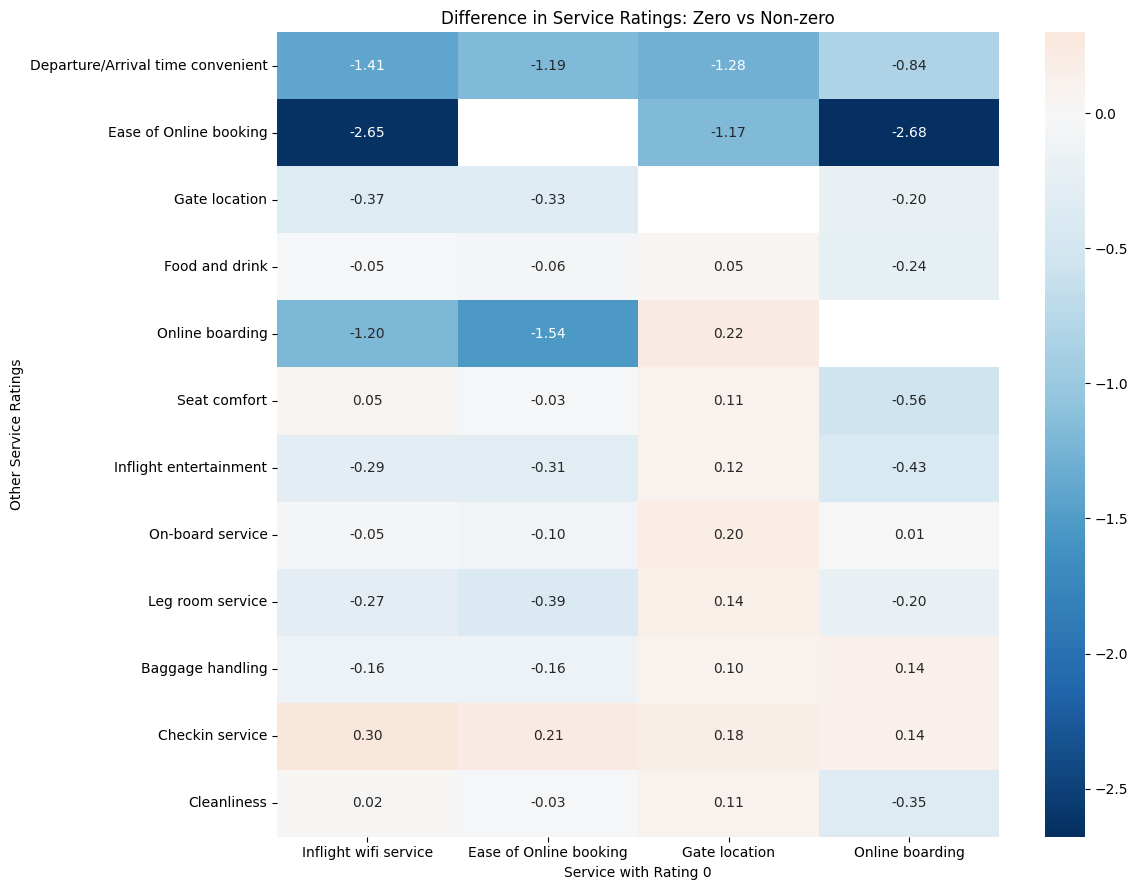

In [ ]:
difference = pd.DataFrame()

for target in target_cols:

    other_cols = [
        col for col in service_cols
        if col != target
    ]

    zero_mean = train.loc[
        train[target] == 0, other_cols
    ].mean()

    nonzero_mean = train.loc[
        train[target] != 0, other_cols
    ].mean()

    difference[target] = zero_mean - nonzero_mean

plt.figure(figsize=(12, 9))

sns.heatmap(
    difference,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Difference in Service Ratings: Zero vs Non-zero")
plt.xlabel("Service with Rating 0")
plt.ylabel("Other Service Ratings")

plt.tight_layout()
plt.show()

4項目のうち、評価0と1以上との間に大きな差はなかった。
ヒートマップでも確認できる。


#### 評価0の乗客の中でも、総合満足者は不満足者より、ほかのサービスを高く評価しているのではないか。

In [ ]:
target_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Gate location",
    "Online boarding"
]

service_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

results = {}

for target in target_cols:

    # 対象サービスの評価が0の乗客
    zero_data = train[train[target] == 0]

    # 対象サービス自身は比較から除外
    other_cols = [
        col for col in service_cols
        if col != target
    ]

    # 総合満足者・不満足者ごとの平均
    comparison = zero_data.groupby(
        "satisfaction"
    )[other_cols].mean().T

    comparison = comparison.rename(
        columns={
            False: "不満足者",
            True: "満足者"
        }
    )

    # 満足者と不満足者の差
    comparison["差分"] = (
        comparison["満足者"]
        - comparison["不満足者"]
    )

    results[target] = comparison

    print(f"\n===== {target} =====")
    print("評価0の人数:", len(zero_data))
    print(
        "総合満足率:",
        round(zero_data["satisfaction"].mean(), 3)
    )

    display(
        comparison.sort_values(
            "差分", ascending=False
        ).round(3)
    )


===== Inflight wifi service =====
評価0の人数: 13102
総合満足率: 0.887


satisfaction,不満足者,満足者,差分
Seat comfort,3.109,3.682,0.573
Inflight entertainment,2.682,3.232,0.550
Cleanliness,2.932,3.461,0.530
Online boarding,1.722,2.241,0.520
On-board service,3.114,3.509,0.395
Food and drink,2.908,3.261,0.353
Checkin service,3.404,3.754,0.350
Leg room service,2.901,3.247,0.345
Baggage handling,3.430,3.681,0.251
Gate location,2.837,2.628,-0.209



===== Ease of Online booking =====
評価0の人数: 16073
総合満足率: 0.708


satisfaction,不満足者,満足者,差分
Online boarding,1.117,2.172,1.055
Seat comfort,3.221,3.668,0.446
Leg room service,2.782,3.218,0.436
Checkin service,3.341,3.748,0.406
Cleanliness,3.104,3.457,0.353
On-board service,3.246,3.493,0.247
Inflight entertainment,2.992,3.221,0.229
Food and drink,3.075,3.261,0.185
Baggage handling,3.608,3.673,0.065
Gate location,2.785,2.656,-0.129



===== Gate location =====
評価0の人数: 1455
総合満足率: 0.543


satisfaction,不満足者,満足者,差分
Online boarding,2.824,4.223,1.399
Inflight entertainment,2.856,4.170,1.314
Seat comfort,3.050,4.211,1.162
Cleanliness,2.949,3.953,1.004
Leg room service,3.188,3.968,0.780
On-board service,3.301,4.071,0.770
Food and drink,2.899,3.666,0.767
Baggage handling,3.598,4.166,0.567
Checkin service,3.359,3.799,0.439
Ease of Online booking,1.934,1.404,-0.530



===== Online boarding =====
評価0の人数: 9147
総合満足率: 0.62


satisfaction,不満足者,満足者,差分
Checkin service,3.389,3.655,0.266
On-board service,3.376,3.625,0.250
Baggage handling,3.838,4.001,0.163
Food and drink,2.993,3.050,0.057
Seat comfort,2.984,3.039,0.055
Inflight entertainment,2.999,3.053,0.055
Cleanliness,3.003,3.047,0.045
Leg room service,3.255,3.280,0.025
Gate location,2.904,2.766,-0.139
Ease of Online booking,0.293,0.095,-0.198


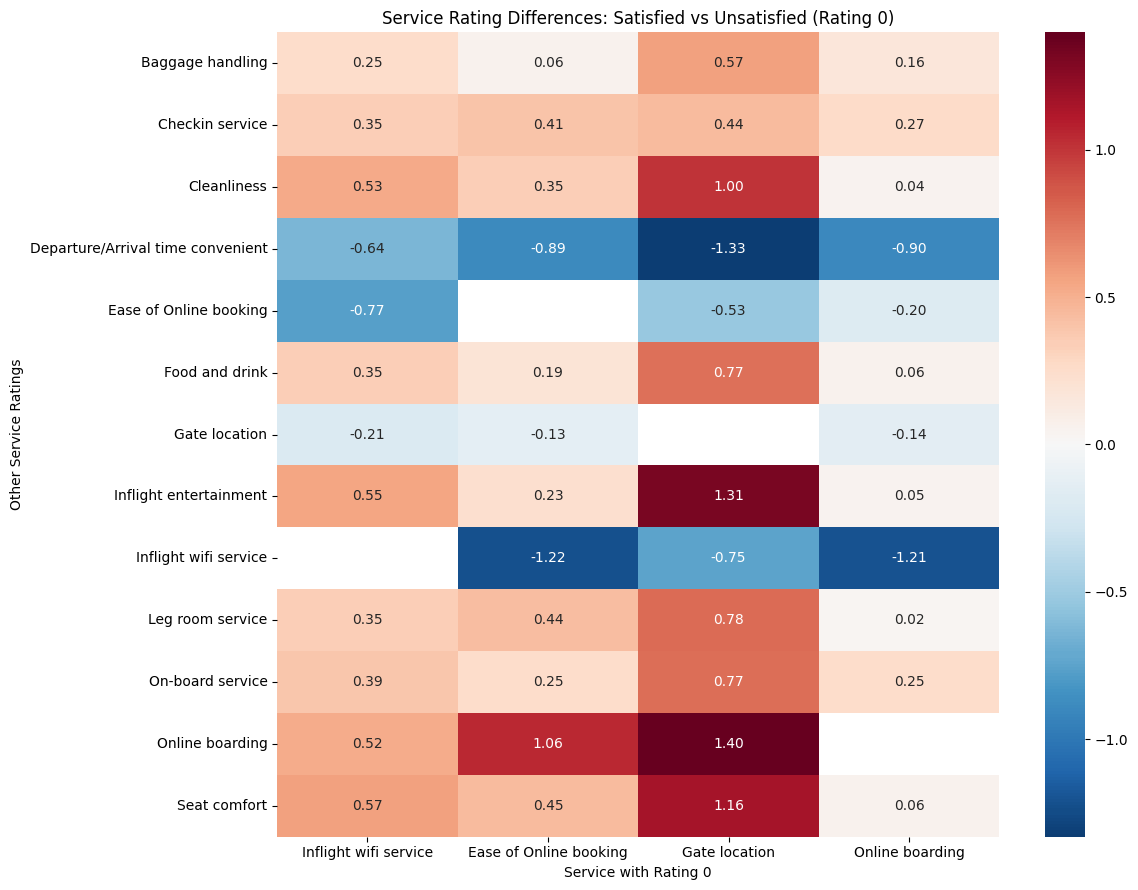

In [ ]:
heatmap_df = pd.DataFrame({
    target: results[target]["差分"]
    for target in target_cols
})

plt.figure(figsize=(12, 9))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title(
    "Service Rating Differences: "
    "Satisfied vs Unsatisfied (Rating 0)"
)

plt.xlabel("Service with Rating 0")
plt.ylabel("Other Service Ratings")

plt.tight_layout()
plt.show()

機内Wi-Fi、オンライン予約、ゲート位置、オンライン搭乗手続きの4項目について、評価0の乗客を対象に、総合満足者と不満足者のほかのサービス評価を比較した。

その結果、総合満足者は不満足者よりも、座席の快適さ、清潔さ、機内エンターテインメント、チェックインサービスなどを高く評価する傾向が確認された。

特にゲート位置の評価が0の乗客では、多くのサービス項目で満足者の平均評価が高く、ほかのサービスへの高評価が総合満足と関連している可能性が示された。

一方で、機内Wi-Fiや発着時刻の利便性など、一部の項目では不満足者のほうが高い評価を示しており、すべてのサービスで同様の傾向が確認されたわけではない。

以上より、特定サービスへの低評価があっても、ほかのサービスへの高評価が総合満足と関連する可能性はあるものの、それだけで高い総合満足率を説明することはできない。

「ほかのサービスの評価が高く、総合満足度を補っている」という仮説は**部分的にそう**といえる？

#### 評価0は「不満」ではなく「未利用・評価対象外」を表している

kaggleのホームページで評価0の意味につて確認、「評価なしだった」。ただし、「評価なし」が未利用・該当なし・未回答のどれを意味するかまでは、今回の説明だけでは断定できない。

例えば、機内Wi-Fiの評価が0だった乗客の88.7%が総合満足していたことについて、これまでは「Wi-Fiの評価が低くても、ほかのサービスが補っているのではないか」と考えていました。
しかし、評価0が「評価なし」であるなら、そもそもWi-Fiに不満を感じていた乗客とは限りません。
そのため、仮説を修正する必要があります。

#### 仮説修正

「特定サービスの評価が0でも総合満足率が高いのは、ほかのサービスが満足度を補っているからではないか」を「特定サービスを評価していない乗客でも総合満足度が高いのは、ほかのサービスへの評価や乗客属性が総合満足度と関連しているからではないか」に修正する。

#### 現時点でのこの仮説の結論

特定サービスの評価が0（評価なし）の乗客について、総合満足者と不満足者のサービス評価を比較した。
その結果、4項目すべてにおいて、総合満足者のほうが高く評価しているサービスが確認された。特に、座席の快適性、機内エンターテインメント、オンライン搭乗などで比較的大きな差が見られた。
一方、すべてのサービスで同様の傾向が見られたわけではなく、評価差の大きさも項目によって異なっていた。
したがって、ほかのサービスへの評価が総合満足度と関連しているという仮説は部分的に支持された。 ただし、乗客属性の影響や各サービスの独立した関連性は未検証であり、追加分析が必要である。

## EDA再開

### 乗客属性別の総合満足率の比較

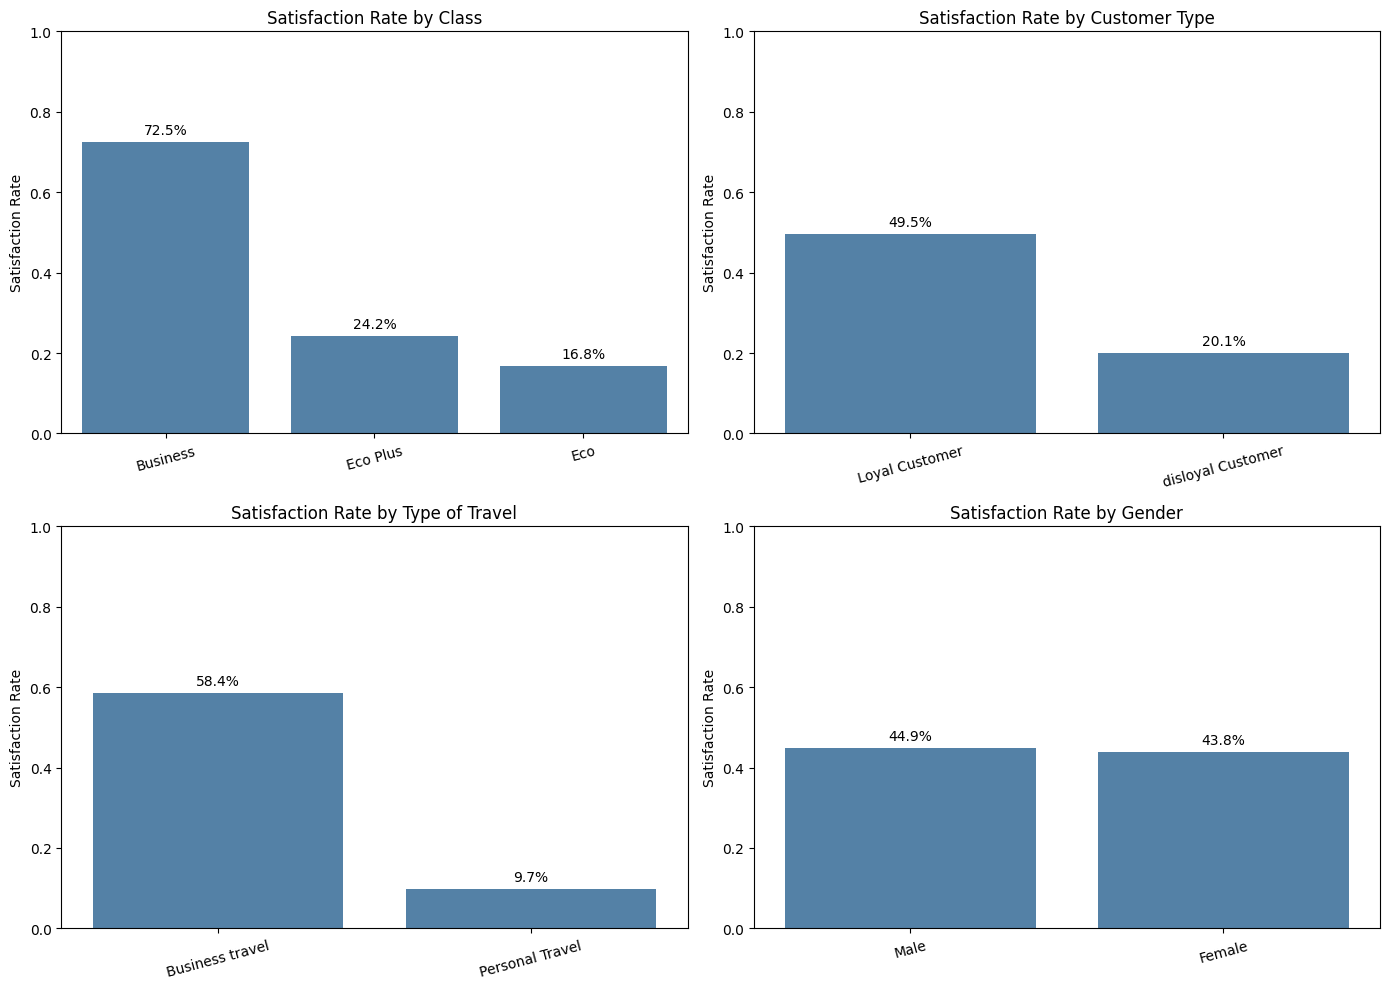

In [ ]:
# 乗客属性別の総合満足率
attribute_cols = [
    "Class",
    "Customer Type",
    "Type of Travel",
    "Gender"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, attribute_cols):

    summary = (
        train.groupby(col)["satisfaction"]
        .agg(["mean", "count"])
        .reset_index()
        .sort_values("mean", ascending=False)
    )

    sns.barplot(
        data=summary,
        x=col,
        y="mean",
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Satisfaction Rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Satisfaction Rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)

    for i, rate in enumerate(summary["mean"]):
        ax.text(
            i, rate + 0.02,
            f"{rate:.1%}",
            ha="center",
            fontsize=10
        )

plt.tight_layout()
plt.show()

- 搭乗クラス（Class）
  - Businessクラスの満足率は72.5%で、Ecoクラスの16.8%と比べて55.7%高くなっています。

- 顧客タイプ（Customer Type）
  - ロイヤル顧客の満足率は、非ロイヤル顧客より29.4%高くなっています。

- 旅行目的（Type of Travel）
  - 出張目的の乗客の満足率は58.4%、個人旅行では9.7%です。48.7%の差があります。

- 性別（Gender）
  - 男女の満足率の差は1.1%と小さくなっています。

乗客属性別の総合満足率を比較した結果、搭乗クラス、旅行目的、顧客タイプによって満足率に大きな違いが見られた。一方、性別による違いは小さかった。特にBusinessクラスおよび出張目的の乗客で満足率が高い傾向が確認された。ただし、各属性は相互に関連している可能性があるため、これらの結果だけで満足度への因果的な影響を判断することはできない。

#### 搭乗クラスと旅行目的の人数を確認する

Type of Travel,Business travel,Personal Travel
Class,,
Business,338272,3940
Eco,141612,185792
Eco Plus,17557,12462


Type of Travel,Business travel,Personal Travel
Class,,
Business,98.8,1.2
Eco,43.3,56.7
Eco Plus,58.5,41.5


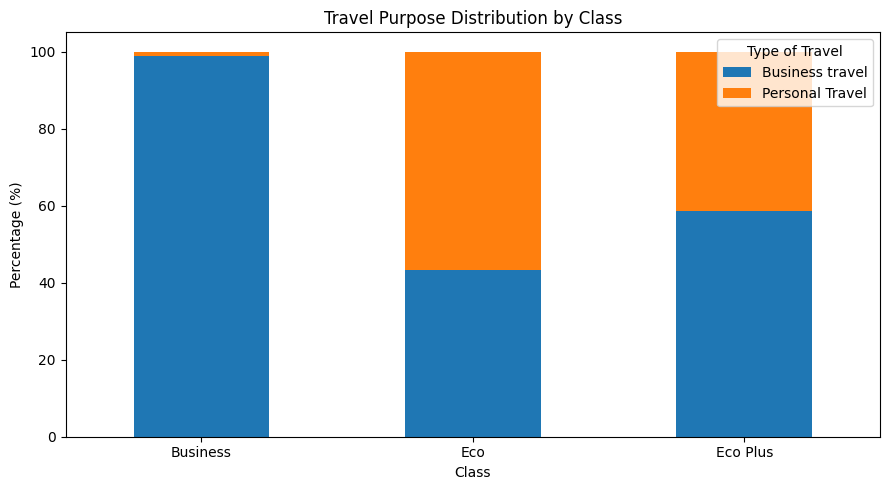

In [ ]:
# 搭乗クラス × 旅行目的の人数
cross_count = pd.crosstab(
    train["Class"],
    train["Type of Travel"]
)

display(cross_count)

# クラスごとの旅行目的の割合
cross_ratio = pd.crosstab(
    train["Class"],
    train["Type of Travel"],
    normalize="index"
) * 100

display(cross_ratio.round(1))

# 可視化
ax = cross_ratio.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Travel Purpose Distribution by Class")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage (%)")
ax.legend(title="Type of Travel")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 搭乗クラスと旅行目的を組み合わせた満足率を比較する

,Class,Type of Travel,count,satisfaction_rate
0,Business,Business travel,338272,73.2
1,Business,Personal Travel,3940,11.2
2,Eco,Business travel,141612,26.0
3,Eco,Personal Travel,185792,9.7
4,Eco Plus,Business travel,17557,34.6
5,Eco Plus,Personal Travel,12462,9.5


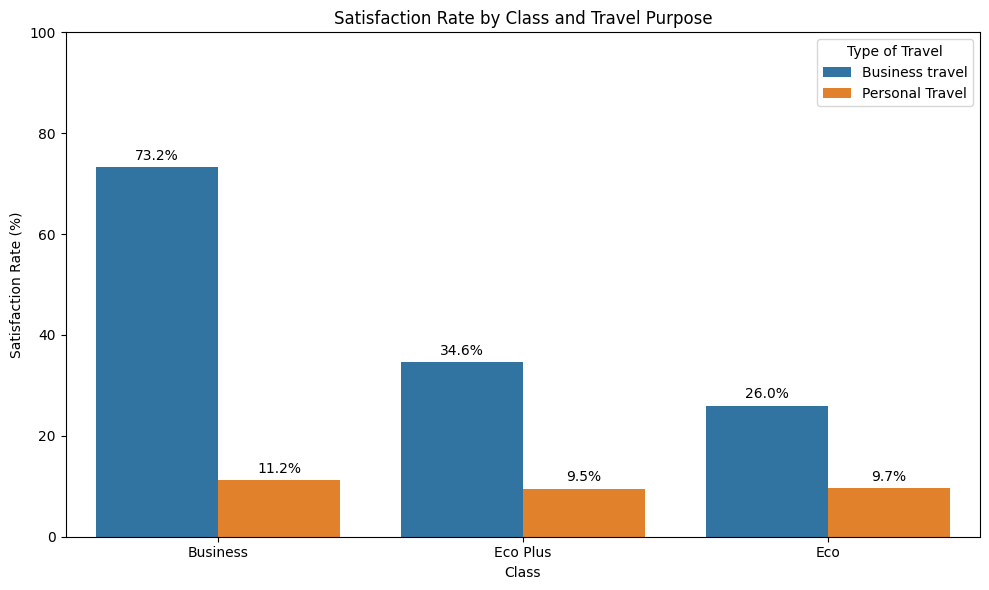

In [ ]:
# クラス × 旅行目的ごとの満足率
satisfaction_cross = (
    train.groupby(
        ["Class", "Type of Travel"]
    )["satisfaction"]
    .agg(["mean", "count"])
    .reset_index()
)

satisfaction_cross["satisfaction_rate"] = (
    satisfaction_cross["mean"] * 100
)

display(
    satisfaction_cross[
        ["Class", "Type of Travel", "count", "satisfaction_rate"]
    ].round(1)
)

# グラフ
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=satisfaction_cross,
    x="Class",
    y="satisfaction_rate",
    hue="Type of Travel",
    order=["Business", "Eco Plus", "Eco"],
    errorbar=None
)

ax.set_title("Satisfaction Rate by Class and Travel Purpose")
ax.set_xlabel("Class")
ax.set_ylabel("Satisfaction Rate (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

搭乗クラスと旅行目的を組み合わせて総合満足率を分析した結果、Businessクラスの98.8%が出張目的であり、両属性には強い関連が見られた。
また、同じ搭乗クラス内で比較しても、すべてのクラスで出張目的の乗客の満足率が高かった。特にBusinessクラスでは、出張目的が73.2%、個人旅行が11.2%と大きな差があった。
一方、個人旅行では搭乗クラスによる満足率の差は小さかった。
以上から、総合満足度には搭乗クラスと旅行目的の両方が関連し、その関連の強さは組み合わせによって異なる可能性が示唆された。ただし、観察データのため因果関係は断定できない。

出張目的でBusinessクラスを利用する乗客は、ほかの乗客グループと比較して総合満足率が高い傾向にある。

### 年齢、飛行距離、出発遅延時間、到着遅延時間(数値データ)における満足率

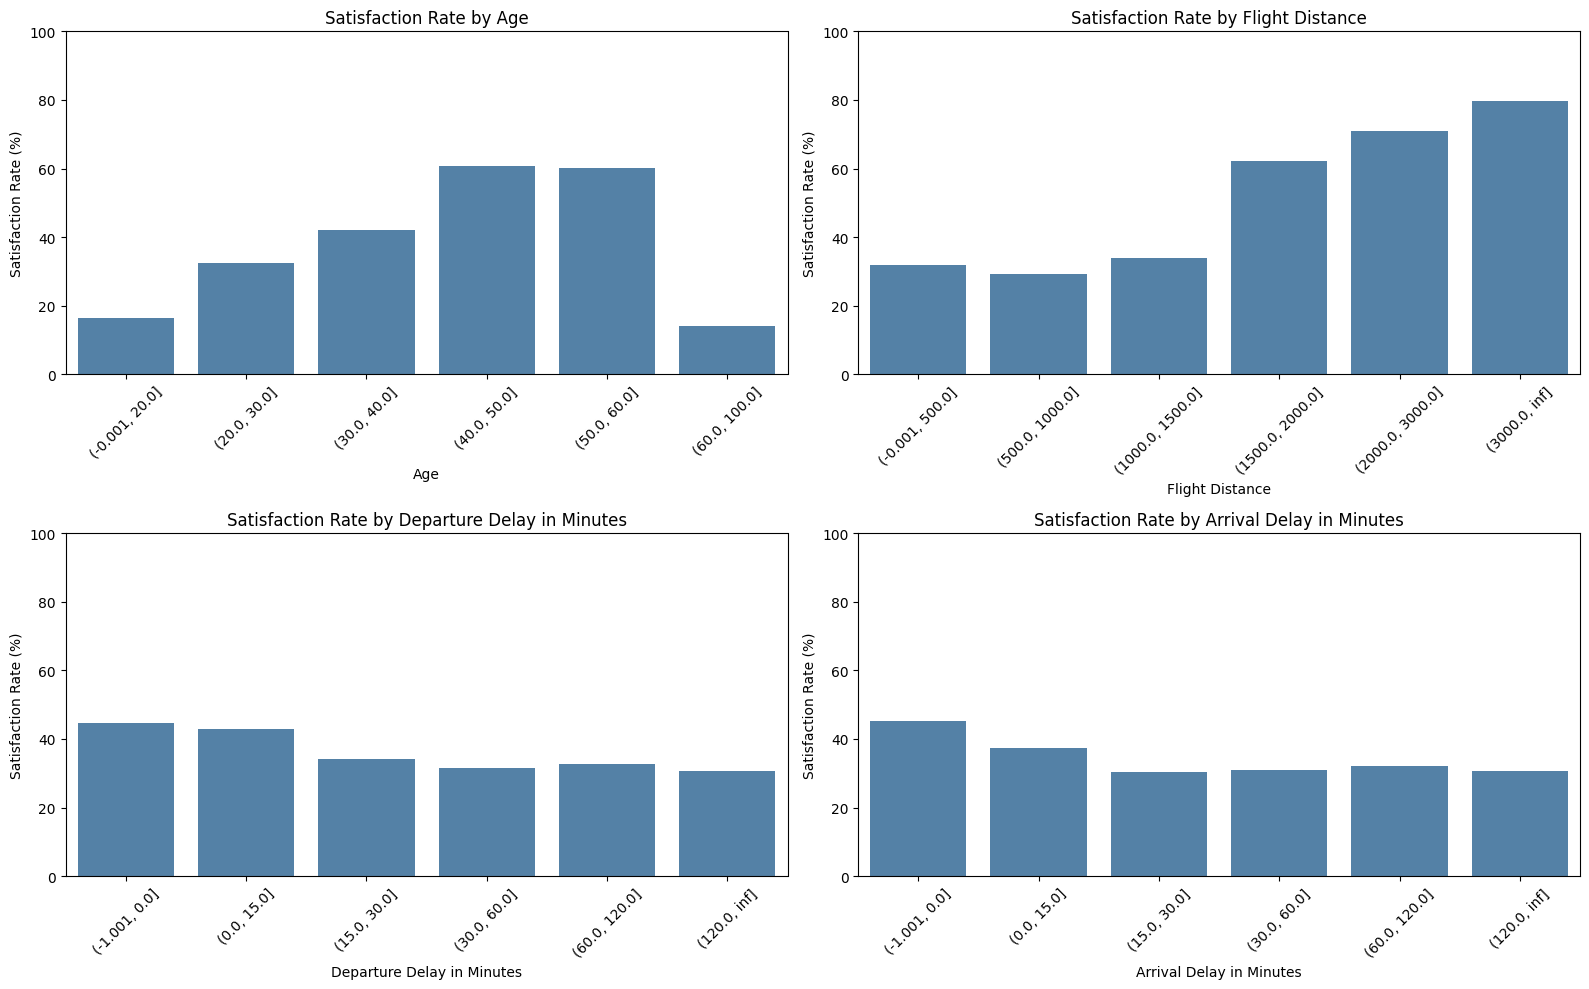

In [ ]:
# 分析する数値変数と区間
bins_config = {
    "Age": [0, 20, 30, 40, 50, 60, 100],
    "Flight Distance": [0, 500, 1000, 1500, 2000, 3000, float("inf")],
    "Departure Delay in Minutes": [-1, 0, 15, 30, 60, 120, float("inf")],
    "Arrival Delay in Minutes": [-1, 0, 15, 30, 60, 120, float("inf")]
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (col, bins) in zip(axes.flat, bins_config.items()):

    temp = train[[col, "satisfaction"]].copy()

    temp["group"] = pd.cut(
        temp[col],
        bins=bins,
        include_lowest=True
    )

    result = (
        temp.groupby("group", observed=True)["satisfaction"]
        .agg(["mean", "count"])
        .reset_index()
    )

    result["satisfaction_rate"] = result["mean"] * 100
    result["group"] = result["group"].astype(str)

    sns.barplot(
        data=result,
        x="group",
        y="satisfaction_rate",
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Satisfaction Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Satisfaction Rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

年齢、飛行距離、出発・到着遅延時間と総合満足率の関係を分析した。
年齢では40〜60歳の乗客の満足率が高く、若年層および60歳超では低い傾向が確認された。
飛行距離では、1,500マイルを超えるグループで満足率が大きく上昇しており、長距離フライトの乗客ほど満足率が高い傾向が見られた。
また、出発・到着遅延時間では、遅延がない乗客と比較して、遅延のある乗客の満足率が低い傾向が確認された。

次は、数値変数と乗客属性の関係を確認する。特に今回の飛行距離の結果について、「長距離フライトだから満足率が高いのか、それとも長距離便にBusinessクラスや出張目的の乗客が多いからなのか」を切り分けるため、搭乗クラス別・旅行目的別に飛行距離と満足率の関係を比較する

#### 飛行距離と総合満足率の関係を、搭乗クラス・旅行目的ごとに比較する

飛行距離が長いほど満足率が高い傾向が見られました。しかし、Businessクラスの乗客は出張目的が98.8%を占めていた。長距離フライトで満足率が高いのは、飛行距離そのものとの関連なのか、それとも搭乗クラスや旅行目的の構成が関係しているのか？

##### 飛行距離 × 搭乗クラス

,Class,Distance Group,mean,count,satisfaction_rate
0,Business,0-500,0.6,17787,57.4
1,Business,500-1000,0.6,81860,63.2
2,Business,1000-1500,0.7,30034,66.9
3,Business,1500-2000,0.8,59610,76.1
4,Business,2000-3000,0.8,87156,78.3
5,Business,3000+,0.8,65765,79.9
6,Eco,0-500,0.2,46133,22.4
7,Eco,500-1000,0.2,203623,16.2
8,Eco,1000-1500,0.2,52374,15.9
9,Eco,1500-2000,0.1,14918,12.1


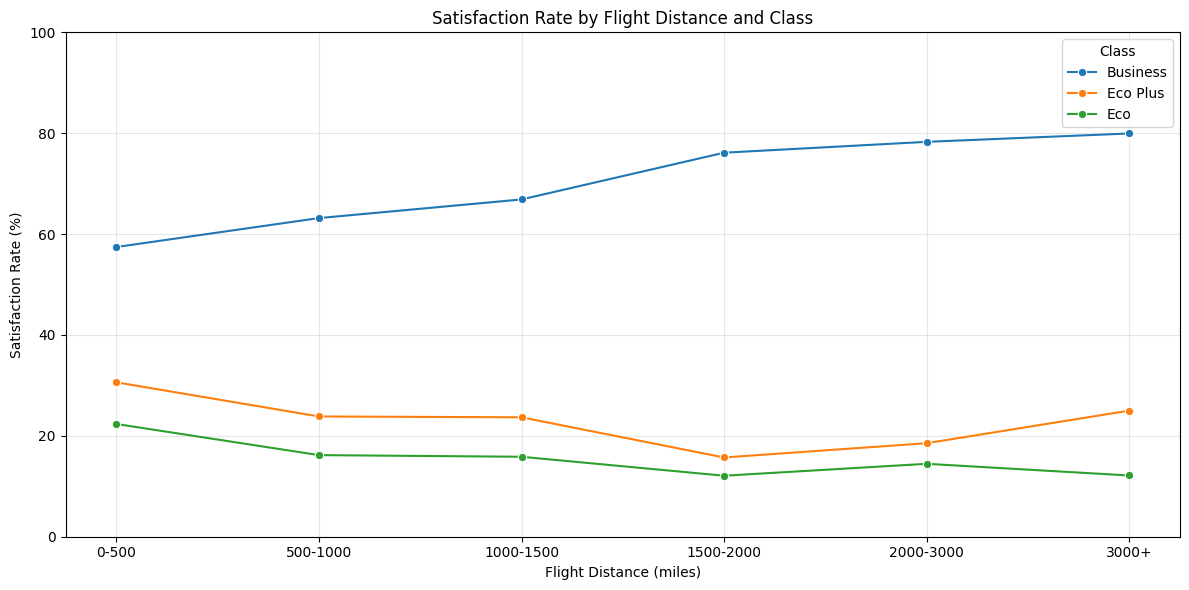

In [ ]:
# 飛行距離の区間
distance_bins = [0, 500, 1000, 1500, 2000, 3000, float("inf")]

distance_labels = [
    "0-500",
    "500-1000",
    "1000-1500",
    "1500-2000",
    "2000-3000",
    "3000+"
]

# 元のデータを変更しない
eda_df = train.copy()

eda_df["Distance Group"] = pd.cut(
    eda_df["Flight Distance"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

# 搭乗クラス × 飛行距離
class_result = (
    eda_df.groupby(
        ["Class", "Distance Group"],
        observed=True
    )["satisfaction"]
    .agg(["mean", "count"])
    .reset_index()
)

class_result["satisfaction_rate"] = (
    class_result["mean"] * 100
)

display(class_result.round(1))

# グラフ
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=class_result,
    x="Distance Group",
    y="satisfaction_rate",
    hue="Class",
    hue_order=["Business", "Eco Plus", "Eco"],
    marker="o",
    errorbar=None
)

plt.title("Satisfaction Rate by Flight Distance and Class")
plt.xlabel("Flight Distance (miles)")
plt.ylabel("Satisfaction Rate (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Businessクラスでは、距離が長くなるにつれて満足率が一貫して上昇しています。一方、Ecoクラスではむしろ低下する傾向があり、Eco Plusも概ね低い水準にとどまっています。

##### 飛行距離 × 旅行目的

,Type of Travel,Distance Group,mean,count,satisfaction_rate
0,Business travel,0-500,0.4,43188,44.2
1,Business travel,500-1000,0.4,178047,43.4
2,Business travel,1000-1500,0.5,55879,47.2
3,Business travel,1500-2000,0.7,64260,72.0
4,Business travel,2000-3000,0.8,90259,76.5
5,Business travel,3000+,0.8,65808,79.9
6,Personal Travel,0-500,0.1,25269,11.2
7,Personal Travel,500-1000,0.1,125967,9.3
8,Personal Travel,1000-1500,0.1,30757,9.8
9,Personal Travel,1500-2000,0.1,11821,10.1


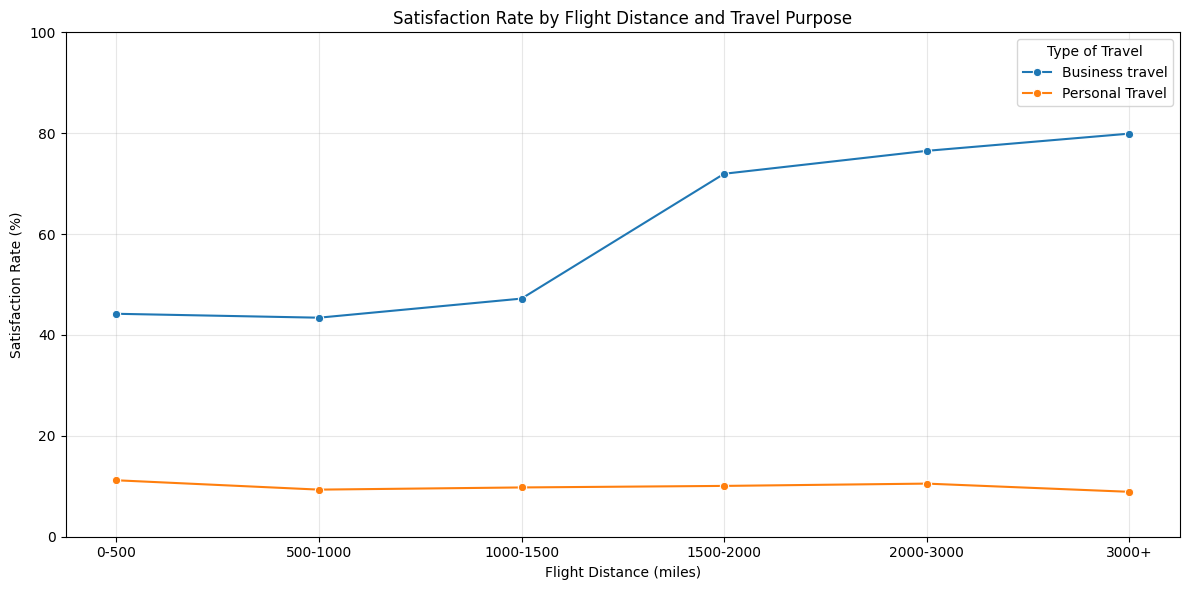

In [ ]:
# 旅行目的 × 飛行距離
travel_result = (
    eda_df.groupby(
        ["Type of Travel", "Distance Group"],
        observed=True
    )["satisfaction"]
    .agg(["mean", "count"])
    .reset_index()
)

travel_result["satisfaction_rate"] = (
    travel_result["mean"] * 100
)

display(travel_result.round(1))

# グラフ
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=travel_result,
    x="Distance Group",
    y="satisfaction_rate",
    hue="Type of Travel",
    marker="o",
    errorbar=None
)

plt.title("Satisfaction Rate by Flight Distance and Travel Purpose")
plt.xlabel("Flight Distance (miles)")
plt.ylabel("Satisfaction Rate (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

出張目的の乗客では、1500マイルを超えるあたりから満足率が大きく上昇しています。
一方、個人旅行では距離に関係なく満足率が約9〜11%で推移しています。
つまり、長距離フライトで満足率が高いという傾向は、主に出張目的の乗客に見られると解釈できます。

飛行距離が長いほど総合満足率が高くなる傾向が確認された。ただし、搭乗クラスと旅行目的で層別化すると、その傾向は主にBusinessクラスおよび出張目的の乗客で顕著だった。一方、Ecoクラスや個人旅行では同様の上昇傾向は確認されなかった。したがって、飛行距離と総合満足度の関連には、搭乗クラスや旅行目的が関係している可能性がある。

### 相関行列

今回のEDAではPearsonとSpearmanを併記する方針。

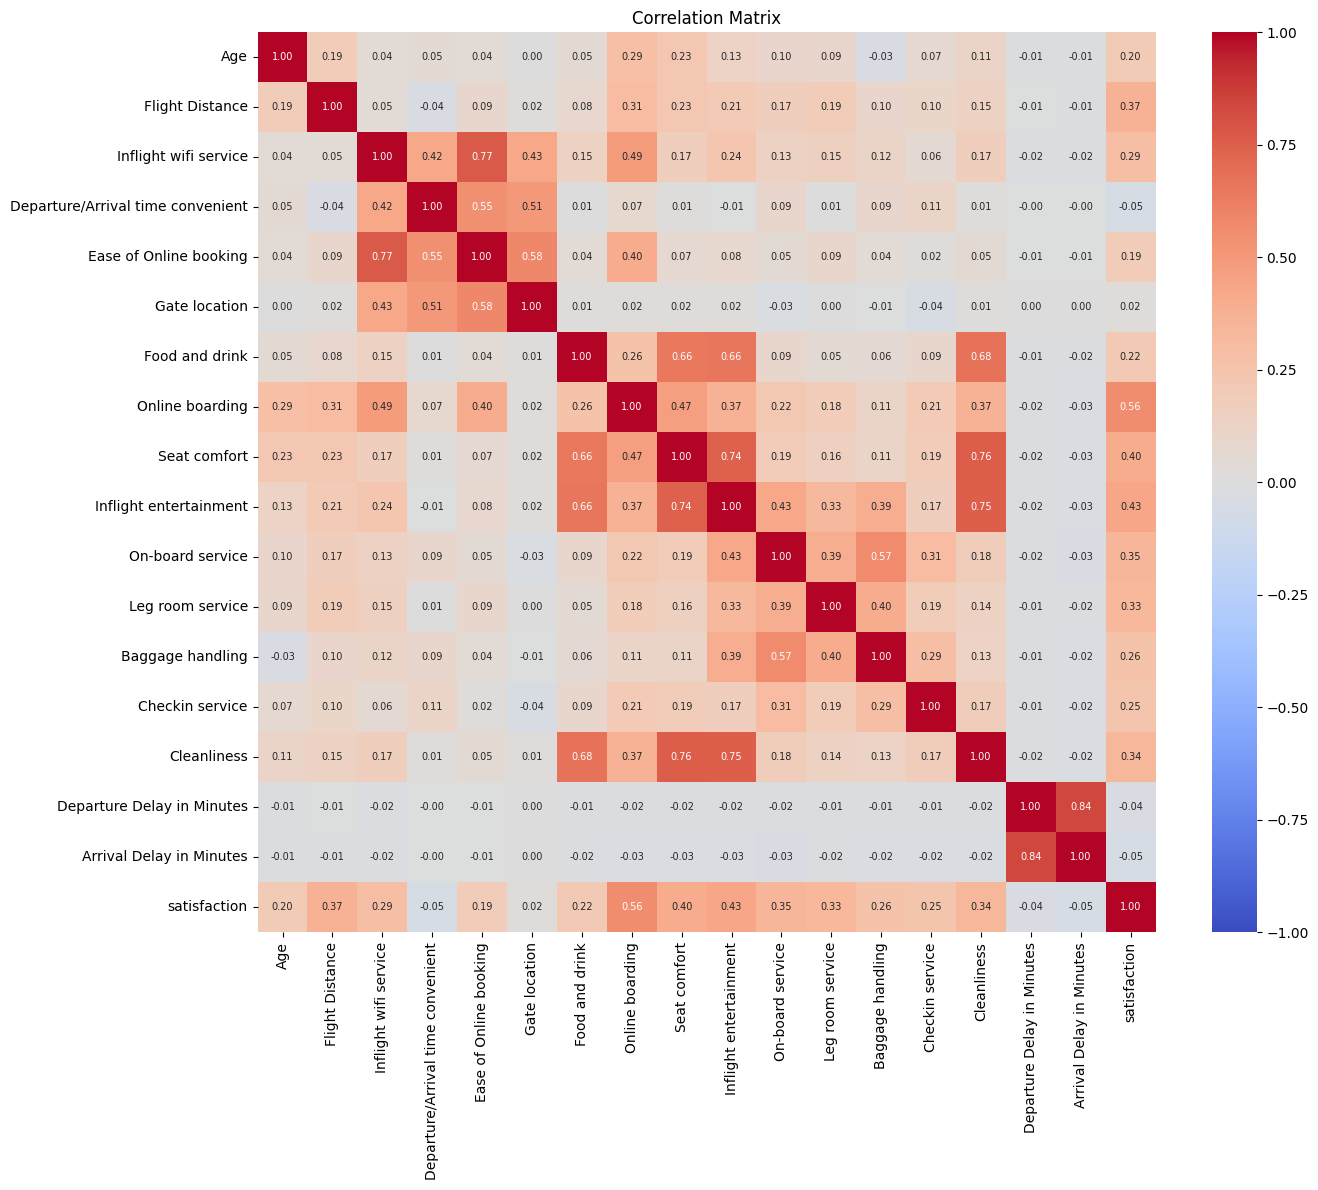

,satisfaction
Online boarding,0.559583
Inflight entertainment,0.430755
Seat comfort,0.401488
Flight Distance,0.370038
On-board service,0.346618
Cleanliness,0.338853
Leg room service,0.330116
Inflight wifi service,0.291275
Baggage handling,0.258118
Checkin service,0.249799


In [ ]:
# 数値変数を抽出し、IDを除外
numeric_df = train.select_dtypes(include="number").drop(
    columns=["id"],
    errors="ignore"
)

# bool型の目的変数を追加
numeric_df["satisfaction"] = train["satisfaction"].astype(int)

corr = numeric_df.corr()

plt.figure(figsize=(14, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# 満足度との相関係数
display(
    corr["satisfaction"]
    .drop("satisfaction")
    .sort_values(ascending=False)
)

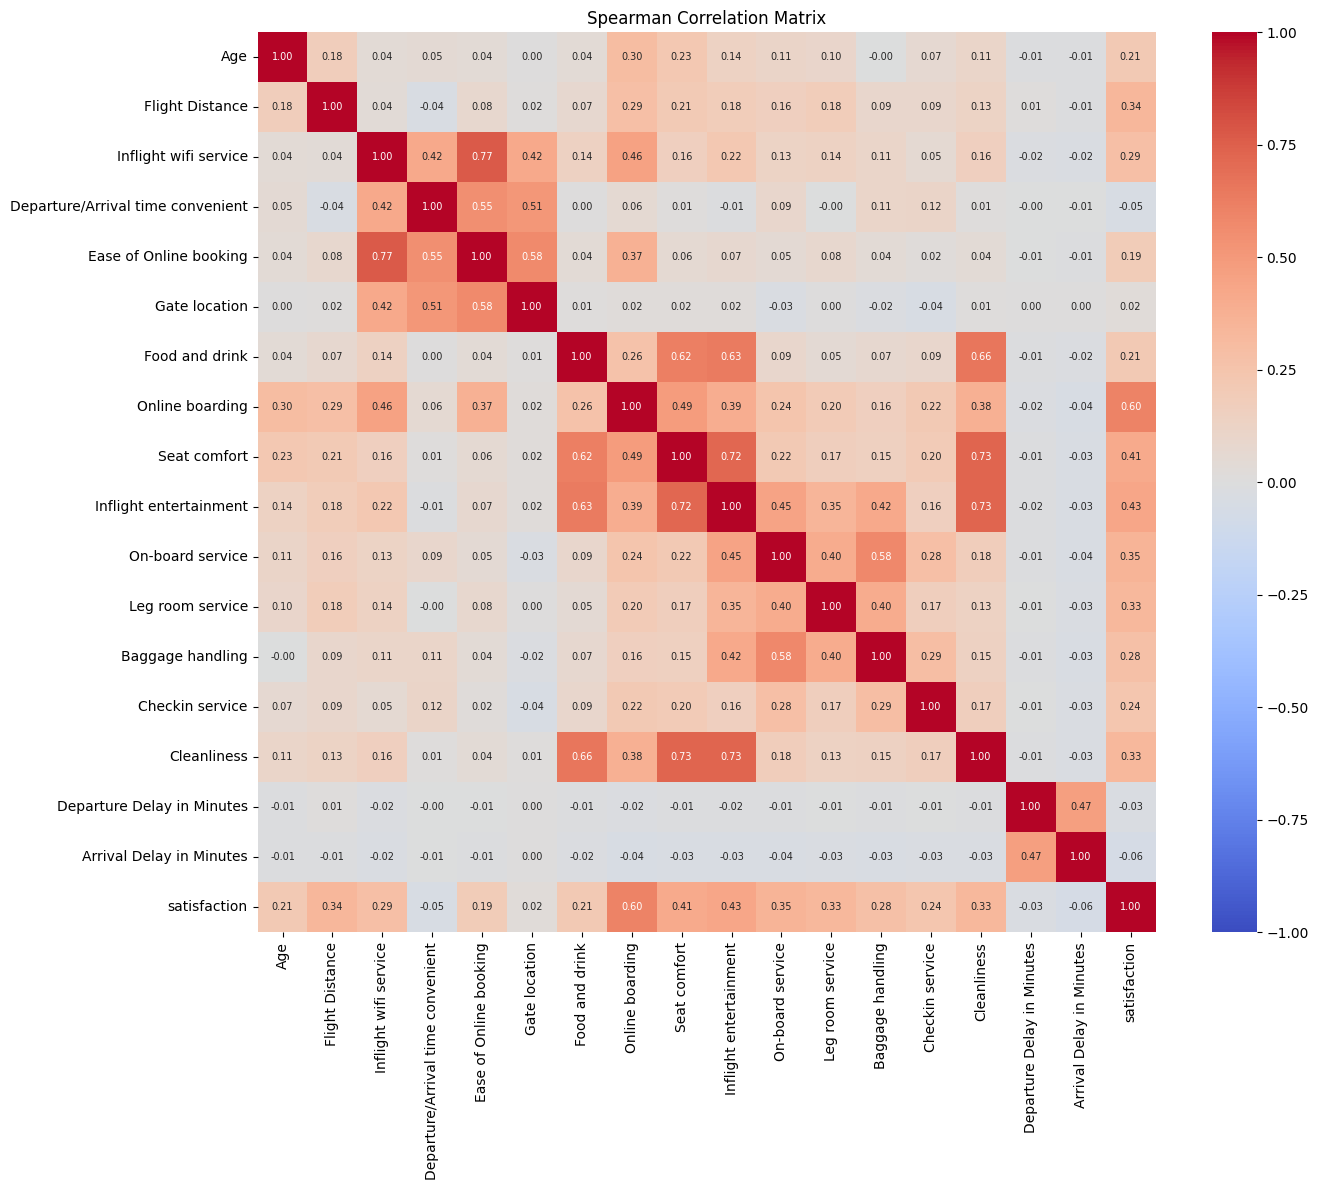

In [ ]:
# Spearmanの順位相関係数
spearman_corr = numeric_df.corr(method="spearman")

plt.figure(figsize=(14, 12))

sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# 目的変数との相関を比較
comparison = pd.DataFrame({
    "Pearson": corr["satisfaction"],
    "Spearman": spearman_corr["satisfaction"]
})

comparison = comparison.drop(
    index="satisfaction"
).sort_values(
    by="Spearman",
    ascending=False
)

display(comparison.round(3))

,Pearson,Spearman
Online boarding,0.560,0.602
Inflight entertainment,0.431,0.433
Seat comfort,0.401,0.413
On-board service,0.347,0.354
Flight Distance,0.370,0.337
Cleanliness,0.339,0.335
Leg room service,0.330,0.332
Inflight wifi service,0.291,0.287
Baggage handling,0.258,0.280
Checkin service,0.250,0.241


PearsonとSpearmanでほぼ同じ傾向が得られています。

- Online boarding は両方の相関係数で最も高く、満足度との関連が強い。
- 機内エンターテインメント、座席の快適性、機内サービスも満足度と正の関連がある。
- 飛行距離も正の関連を示すが、これまでのEDAから座席クラスや旅行目的の構成が影響している可能性がある。
- 遅延時間の相関は弱い。ただし、遅延が満足度に影響しないという意味ではなく、非線形な関係や他の変数との交互作用が存在する可能性がある。

#### 説明変数同士の相関

In [ ]:
# 1. 数値型の説明変数を取得
# idと目的変数satisfactionは除外
numeric_cols = (
    train.select_dtypes(include=["number", "bool"])
    .columns
    .drop(["id", "satisfaction"], errors="ignore")
)

X_corr = train[numeric_cols]

# 2. PearsonとSpearmanの相関行列
pearson_corr = X_corr.corr(method="pearson")
spearman_corr = X_corr.corr(method="spearman")

# 3. 説明変数の組み合わせを一覧化
rows = []

for i, col1 in enumerate(numeric_cols):
    for col2 in numeric_cols[i + 1:]:
        p = pearson_corr.loc[col1, col2]
        s = spearman_corr.loc[col1, col2]

        rows.append({
            "Variable 1": col1,
            "Variable 2": col2,
            "Pearson": p,
            "Spearman": s,
            "Difference": s - p,
            "Abs Correlation": max(abs(p), abs(s))
        })

corr_comparison = pd.DataFrame(rows)

# 4. 相関が強い順に並び替え
corr_comparison = corr_comparison.sort_values(
    "Abs Correlation",
    ascending=False
)

# 5. 上位20組を表示
display(
    corr_comparison[
        ["Variable 1", "Variable 2",
         "Pearson", "Spearman", "Difference"]
    ]
    .head(20)
    .style
    .format({
        "Pearson": "{:.3f}",
        "Spearman": "{:.3f}",
        "Difference": "{:+.3f}"
    })
    .background_gradient(
        subset=["Pearson", "Spearman"],
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )
)

,Variable 1,Variable 2,Pearson,Spearman,Difference
135,Departure Delay in Minutes,Arrival Delay in Minutes,0.842,0.472,-0.370
32,Inflight wifi service,Ease of Online booking,0.772,0.770,-0.002
105,Seat comfort,Cleanliness,0.763,0.733,-0.030
112,Inflight entertainment,Cleanliness,0.751,0.727,-0.024
100,Seat comfort,Inflight entertainment,0.745,0.723,-0.022
88,Food and drink,Cleanliness,0.678,0.657,-0.021
83,Food and drink,Inflight entertainment,0.656,0.633,-0.023
82,Food and drink,Seat comfort,0.656,0.620,-0.036
116,On-board service,Baggage handling,0.568,0.581,+0.013
58,Ease of Online booking,Gate location,0.580,0.577,-0.003


説明変数間の関係性を評価するため、Pearson相関係数およびSpearman順位相関係数を算出し、両者を比較した。

その結果、出発遅延時間と到着遅延時間には強いPearson相関（r = 0.842）が認められた一方、Spearman相関は0.472にとどまり、両者の間に比較的大きな差が確認された。この差には、遅延時間の分布の偏りや外れ値などが影響している可能性があるため、追加の可視化による検証が必要である。

また、機内Wi-Fiとオンライン予約の容易さ（Pearson = 0.772、Spearman = 0.770）、座席の快適性と清潔さ（Pearson = 0.763、Spearman = 0.733）、機内エンターテインメントと清潔さ（Pearson = 0.751、Spearman = 0.727）など、複数のサービス評価項目間に強い正の相関が確認された。

これらの変数では両相関係数がおおむね一致しており、評価項目間に共通した変動傾向が存在することが示唆された。

以上より、説明変数間には情報の重複が存在する可能性がある。今後はVIFによる多重共線性の評価を行い、さらに機械学習モデルとSHAPを用いて、各変数が満足度予測にどの程度寄与しているかを検証する。

# 航空会社の顧客満足度予測：探索的データ分析（EDA）のまとめ

## 1. 分析目的

本分析では、航空会社の顧客満足度データを用いて、顧客満足度に関連する要因を明らかにすることを目的とした。

特に、以下の観点から探索的データ分析（EDA）を実施した。

- 顧客属性（搭乗クラス、旅行目的、顧客タイプ、性別）と満足度の関係
- 年齢、飛行距離、出発・到着遅延時間と満足度の関係
- 搭乗クラス、旅行目的、飛行距離の組み合わせによる満足率の違い
- 目的変数と説明変数の相関関係
- 説明変数同士の相関関係および多重共線性の可能性

最終的には、EDAによって得られた知見をもとに仮説を構築し、機械学習モデルによる満足度予測と特徴量重要度の解釈につなげる。

---

## 2. 顧客属性別の満足度分析

### 2.1 搭乗クラス別

| 搭乗クラス | 満足率 |
|---|---:|
| Business | 72.5% |
| Eco Plus | 24.2% |
| Eco | 16.8% |

Businessクラスの満足率は72.5%であり、Eco PlusおよびEcoと比較して大幅に高かった。

この結果から、搭乗クラスと顧客満足度の間には明確な関連が認められた。

ただし、搭乗クラスによって旅行目的や飛行距離などの顧客構成が異なる可能性があるため、搭乗クラス単独の効果とは断定できない。

### 2.2 顧客タイプ別

| 顧客タイプ | 満足率 |
|---|---:|
| Loyal Customer | 49.5% |
| disloyal Customer | 20.1% |

ロイヤル顧客の満足率は非ロイヤル顧客より約29.4ポイント高かった。

顧客タイプと満足度には関連が認められるが、満足度がロイヤルティを高める可能性もあるため、因果関係の方向については判断できない。

### 2.3 旅行目的別

| 旅行目的 | 満足率 |
|---|---:|
| Business travel | 58.4% |
| Personal Travel | 9.7% |

ビジネス目的の顧客は、個人旅行目的の顧客と比較して満足率が著しく高かった。

旅行目的は満足度を予測するうえで重要な説明変数となる可能性がある。

### 2.4 性別

| 性別 | 満足率 |
|---|---:|
| Male | 44.9% |
| Female | 43.8% |

男女間の満足率の差は約1.1ポイントと小さかった。

今回の単純集計では、性別による満足率の大きな違いは確認されなかった。

---

## 3. 搭乗クラスと旅行目的のクロス分析

| 搭乗クラス | Business travel | Personal Travel |
|---|---:|---:|
| Business | 73.2% | 11.2% |
| Eco Plus | 34.6% | 9.5% |
| Eco | 26.0% | 9.7% |

※数値は各グループ内の満足率。

### 分析結果

- ビジネス目的でBusinessクラスを利用する顧客の満足率が73.2%と最も高かった。
- 個人旅行目的の顧客では、搭乗クラスにかかわらず満足率が約10%と低かった。
- Businessクラス利用者の98.8%はビジネス目的であり、搭乗クラスと旅行目的の構成には大きな偏りがあった。

### 考察

搭乗クラスと旅行目的は独立していない可能性が高く、両者の組み合わせを考慮することが重要である。

特に、搭乗クラスによる満足率の違いは、旅行目的の構成の違いによって一部説明される可能性がある。

**仮説H1：搭乗クラスと旅行目的の組み合わせは、顧客満足度と強く関連する。**

---

## 4. 年齢・飛行距離・遅延時間の分析

### 4.1 年齢と満足度

40〜60歳の顧客では満足率が約60%と高かった。

一方、20歳以下や60歳超のグループでは満足率が低い傾向が認められた。

年齢と満足度の関係は単純な線形関係ではなく、非線形な関係を持つ可能性がある。

### 4.2 飛行距離と満足度

全体では、飛行距離が長いほど満足率が高くなる傾向が認められた。

ただし、搭乗クラス別に分析すると、異なる傾向が確認された。

| 飛行距離（マイル） | Business | Eco Plus | Eco |
|---|---:|---:|---:|
| 0–500 | 57.4% | 30.6% | 22.4% |
| 500–1000 | 63.2% | 23.8% | 16.2% |
| 1000–1500 | 66.9% | 23.7% | 15.9% |
| 1500–2000 | 76.1% | 15.7% | 12.1% |
| 2000–3000 | 78.3% | 18.5% | 14.5% |
| 3000以上 | 79.9% | 25.0% | 12.1% |

Businessクラスでは飛行距離が長くなるほど満足率が上昇した。

一方、EcoおよびEco Plusでは同様の上昇傾向は認められなかった。

また、旅行目的別の分析では、ビジネス目的の顧客は長距離ほど満足率が高くなる一方、個人旅行目的の顧客では飛行距離にかかわらず約9〜11%で推移した。

このことから、飛行距離と満足度の関係は、搭乗クラスや旅行目的によって異なる可能性がある。

なお、長距離のEcoおよびEco Plusではサンプル数が少ない区間があるため、推定値の安定性には注意が必要である。

**仮説H2：飛行距離と顧客満足度の関係には、搭乗クラスや旅行目的による交互作用が存在する。**

### 4.3 出発・到着遅延時間と満足度

遅延がない顧客では満足率が比較的高く、遅延が発生したグループでは満足率が低下する傾向が見られた。

一方、満足度との単純相関は以下のとおりであった。

| 変数 | Pearson | Spearman |
|---|---:|---:|
| 出発遅延時間 | -0.036 | -0.029 |
| 到着遅延時間 | -0.052 | -0.058 |

いずれも非常に弱い負の相関であった。

したがって、遅延時間と満足度の関係は、単純な相関係数のみでは十分に捉えられない可能性がある。

---

## 5. 目的変数と説明変数の相関分析

Pearson相関係数とSpearman順位相関係数を算出し、顧客満足度との関連を比較した。

| 説明変数 | Pearson | Spearman |
|---|---:|---:|
| Online boarding | 0.560 | 0.602 |
| Inflight entertainment | 0.431 | 0.433 |
| Seat comfort | 0.401 | 0.413 |
| Flight Distance | 0.370 | 0.337 |
| On-board service | 0.347 | 0.354 |
| Cleanliness | 0.339 | 0.335 |
| Leg room service | 0.330 | 0.332 |
| Inflight wifi service | 0.291 | 0.287 |
| Baggage handling | 0.258 | 0.280 |
| Checkin service | 0.250 | 0.241 |

### 分析結果

Online boardingが最も高い相関を示した。

特にSpearman相関係数は0.602であり、オンライン搭乗手続きの評価が高い顧客ほど満足度が高い傾向が認められた。

また、機内エンターテインメント、座席の快適性、機内サービス、清潔さなども満足度と正の相関を示した。

PearsonとSpearmanは全体として類似した傾向を示したが、Online boardingではSpearmanの方がやや高かった。

### 考察

オンライン搭乗手続きの評価や機内サービスに関する評価項目は、満足度予測に有用な特徴量となる可能性がある。

ただし、相関分析は単変量の関連を示すものであり、他の説明変数を調整した独立した寄与や因果関係を示すものではない。

**仮説H3：オンライン搭乗手続きの評価は、他の変数を考慮した予測モデルにおいても重要な特徴量となる。**

---

## 6. 説明変数同士の相関分析

説明変数間の関連を把握するため、Pearson相関係数とSpearman順位相関係数を比較した。

| 説明変数の組み合わせ | Pearson | Spearman |
|---|---:|---:|
| 出発遅延 × 到着遅延 | 0.842 | 0.472 |
| 機内Wi-Fi × オンライン予約の容易さ | 0.772 | 0.770 |
| 座席の快適性 × 清潔さ | 0.763 | 0.733 |
| 機内エンタメ × 清潔さ | 0.751 | 0.727 |
| 座席の快適性 × 機内エンタメ | 0.745 | 0.723 |
| 食事・飲み物 × 清潔さ | 0.678 | 0.657 |
| 食事・飲み物 × 機内エンタメ | 0.656 | 0.633 |
| 機内サービス × 手荷物の取り扱い | 0.568 | 0.581 |

### 6.1 出発遅延と到着遅延

Pearson相関係数は0.842と非常に高い一方、Spearman相関係数は0.472であり、両者の間に大きな差が認められた。

この違いには、外れ値、遅延時間の分布の偏り、同順位の多さなどが影響している可能性がある。

今後は散布図および分布の確認によって、この差が生じる要因を検証する必要がある。

### 6.2 サービス評価項目間の相関

機内Wi-Fiとオンライン予約の容易さ、座席の快適性と清潔さ、機内エンターテインメントと清潔さなどに強い正の相関が認められた。

これらの組み合わせではPearsonとSpearmanの差が比較的小さく、両手法で一貫した関連が確認された。

複数のサービス評価項目が共通した顧客評価傾向を反映している可能性がある。

### 6.3 多重共線性への示唆

説明変数間に強い相関が存在することから、ロジスティック回帰などの線形モデルでは、多重共線性によって回帰係数の推定や解釈が不安定になる可能性がある。

今後はVIFを用いて多重共線性を確認する。

ただし、相関が高いという理由だけで説明変数を削除するのではなく、予測性能やモデルの解釈可能性を踏まえて特徴量選択を検討する。

**仮説H4：複数のサービス評価項目には共通した情報が含まれており、モデルによっては特徴量の冗長性が問題となる可能性がある。**

---

## 7. 総合考察

これまでのEDAから、以下の知見が得られた。

**① 顧客属性による満足率の違いが大きい。**

搭乗クラス、旅行目的、顧客タイプによって満足率に大きな差が認められた。特に、ビジネス目的のBusinessクラス利用者の満足率が高かった。

**② 飛行距離と満足度の関係は顧客セグメントによって異なる。**

Businessクラスやビジネス目的の顧客では長距離ほど満足率が高い傾向が見られたが、Ecoや個人旅行目的では同様の傾向は確認されなかった。

**③ オンライン搭乗手続きの評価は満足度と比較的強く関連する。**

Online boardingは、分析対象の数値変数の中で満足度との相関が最も高かった。

**④ サービス評価項目間には強い相関が存在する。**

座席の快適性、清潔さ、機内エンターテインメントなどの間には強い正の相関が認められた。

**⑤ 遅延時間には追加分析が必要である。**

出発遅延と到着遅延のPearson・Spearman相関係数には大きな差があり、分布や外れ値の影響を確認する必要がある。

---

## 8. 今後の分析計画

### STEP 1：追加の探索的分析

- 出発遅延と到着遅延の散布図および外れ値の確認
- VIFによる多重共線性の評価
- 必要に応じたカテゴリ変数間の関連分析
- 満足度と関連する交互作用の検討

### STEP 2：機械学習モデルの構築

以下のモデルを用いて満足度予測を実施する。

- Logistic Regression：ベースラインモデル
- LightGBM：非線形な関係や交互作用を捉えるモデル
- CatBoost：カテゴリ変数を扱える勾配ブースティングモデル

層化分割や交差検証を用いて、モデルの汎化性能を評価する。

評価指標にはROC-AUC、Precision、Recall、F1-score、混同行列などを使用する。

### STEP 3：モデル解釈

SHAPを用いて、各特徴量がモデルの予測にどの程度寄与しているかを評価する。

特に、以下の点を検証する。

- Online boardingはモデルでも重要な特徴量となるか
- 搭乗クラスと旅行目的の組み合わせは予測に寄与するか
- 飛行距離と搭乗クラスの交互作用は確認できるか
- 相関の強いサービス評価項目はモデル内でどのように扱われるか

---

## 9. 結論

本分析では、航空会社の顧客満足度データに対して、顧客属性別分析、クロス集計、層別分析、Pearson・Spearman相関分析を実施した。

その結果、搭乗クラス、旅行目的、飛行距離、オンライン搭乗手続き、機内サービス評価などが顧客満足度と関連していることが確認された。

特に、搭乗クラスと旅行目的の組み合わせによる満足率の違い、および飛行距離と満足度の関係が顧客セグメントによって異なる点が重要な発見であった。

また、説明変数間には強い相関が存在することから、予測モデルの構築時には多重共線性や特徴量の冗長性に注意する必要がある。

今後は、EDAで得られた仮説をもとに機械学習モデルを構築し、予測性能の比較とSHAPによるモデル解釈を通じて、顧客満足度予測に有用な要因を検証する。

## 遅延時間の追加分析

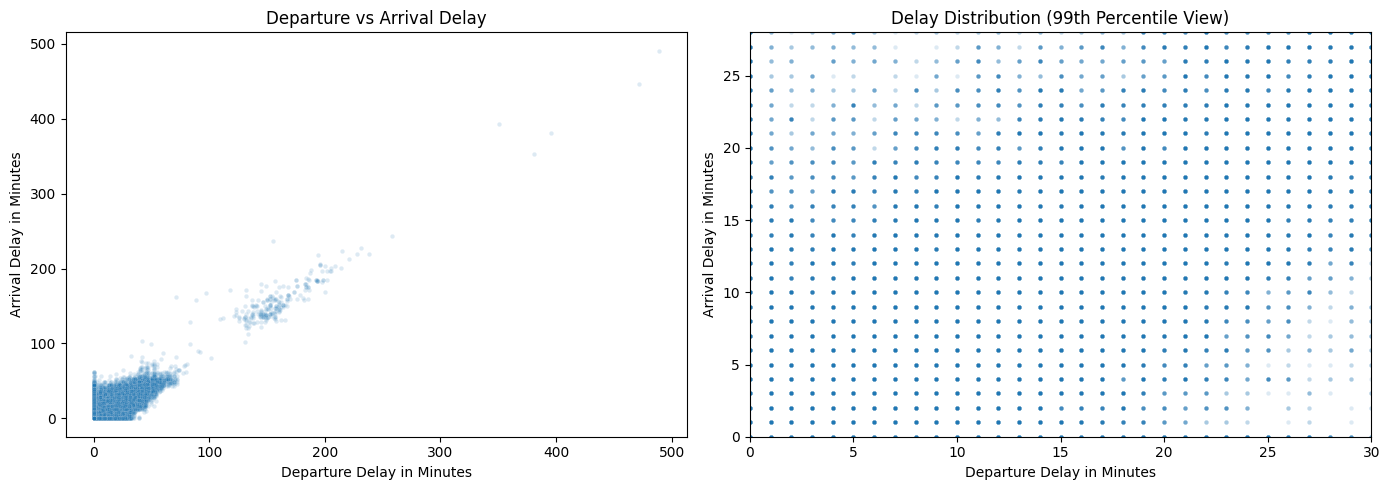

Pearson correlation: 0.842
Spearman correlation: 0.472
Departure zero rate: 90.8%
Arrival zero rate: 91.6%


,Departure Delay in Minutes,Arrival Delay in Minutes
count,699343.000000,699343.000000
mean,1.173596,1.134280
std,5.964274,5.749304
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,489.000000,491.000000


In [ ]:

# 使用する列
departure = "Departure Delay in Minutes"
arrival = "Arrival Delay in Minutes"

# trainから必要なデータを取得
delay_df = train[[departure, arrival]].copy()

# 数値型に変換し、欠損値を除外
delay_df[departure] = pd.to_numeric(
    delay_df[departure], errors="coerce"
)
delay_df[arrival] = pd.to_numeric(
    delay_df[arrival], errors="coerce"
)
delay_df = delay_df.dropna()

# 99パーセンタイルを計算
x_max = delay_df[departure].quantile(0.99)
y_max = delay_df[arrival].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 全データの散布図
sns.scatterplot(
    data=delay_df,
    x=departure,
    y=arrival,
    alpha=0.15,
    s=10,
    ax=axes[0]
)
axes[0].set_title("Departure vs Arrival Delay")

# ② 外れ値の影響を抑えた表示
sns.scatterplot(
    data=delay_df,
    x=departure,
    y=arrival,
    alpha=0.15,
    s=10,
    ax=axes[1]
)
axes[1].set_xlim(0, max(x_max, 1))
axes[1].set_ylim(0, max(y_max, 1))
axes[1].set_title("Delay Distribution (99th Percentile View)")

plt.tight_layout()
plt.show()

# 相関係数
print("Pearson correlation:",
      round(delay_df[departure].corr(delay_df[arrival], method="pearson"), 3))

print("Spearman correlation:",
      round(delay_df[departure].corr(delay_df[arrival], method="spearman"), 3))

# 遅延0分の割合
print(f"Departure zero rate: {(delay_df[departure] == 0).mean():.1%}")
print(f"Arrival zero rate: {(delay_df[arrival] == 0).mean():.1%}")

# 基本統計量
display(delay_df.describe())


,mean,count,satisfaction_rate
Departure Delay Group,,,
No Delay,0.447991,634941,44.799123
Delayed,0.400376,64402,40.037576


,mean,count,satisfaction_rate
Arrival Delay Group,,,
No Delay,0.452104,640415,45.210371
Delayed,0.351259,58928,35.125916


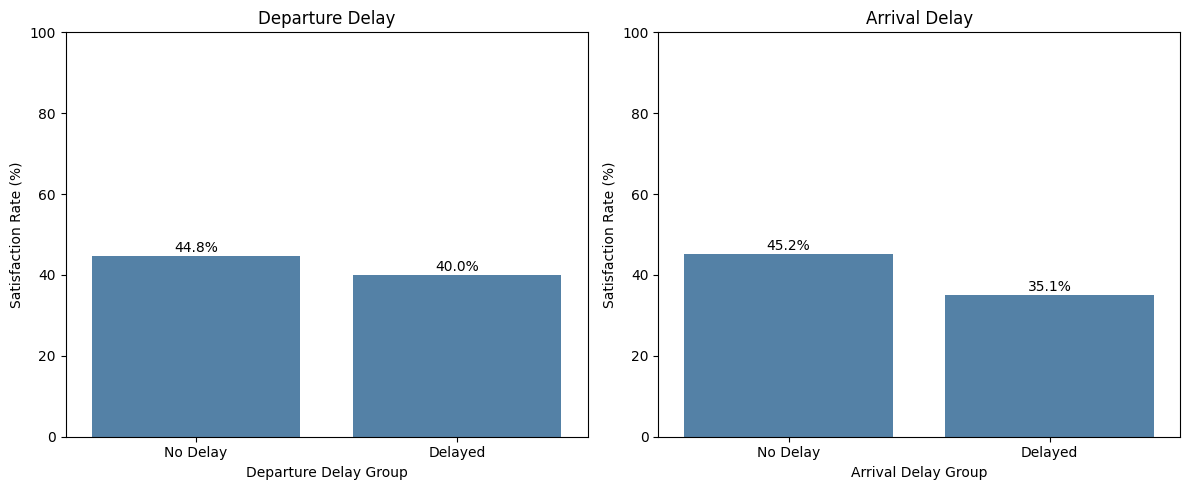

In [ ]:
departure = "Departure Delay in Minutes"
arrival = "Arrival Delay in Minutes"

# 元データを変更しない
delay_analysis = train[
    [departure, arrival, "satisfaction"]
].copy().dropna()

# 遅延の有無を分類
delay_analysis["Departure Delay Group"] = (
    delay_analysis[departure]
    .gt(0)
    .map({False: "No Delay", True: "Delayed"})
)

delay_analysis["Arrival Delay Group"] = (
    delay_analysis[arrival]
    .gt(0)
    .map({False: "No Delay", True: "Delayed"})
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, group_col, title in zip(
    axes,
    ["Departure Delay Group", "Arrival Delay Group"],
    ["Departure Delay", "Arrival Delay"]
):
    summary = (
        delay_analysis.groupby(group_col)["satisfaction"]
        .agg(["mean", "count"])
        .reindex(["No Delay", "Delayed"])
    )

    summary["satisfaction_rate"] = summary["mean"] * 100

    display(summary)

    sns.barplot(
        x=summary.index,
        y=summary["satisfaction_rate"],
        ax=ax,
        color="steelblue"
    )

    ax.set_title(title)
    ax.set_ylabel("Satisfaction Rate (%)")
    ax.set_ylim(0, 100)

    for i, value in enumerate(summary["satisfaction_rate"]):
        ax.text(i, value + 1, f"{value:.1f}%",
                ha="center")

plt.tight_layout()
plt.show()


,Class,Type of Travel,Arrival Delay Group,mean,count,satisfaction_rate
0,Business,Business travel,Delayed,0.64,26462,64.00
1,Business,Business travel,No Delay,0.74,311696,74.03
2,Business,Personal Travel,Delayed,0.06,311,6.11
3,Business,Personal Travel,No Delay,0.12,3628,11.63
4,Eco,Business travel,Delayed,0.17,13598,16.97
5,Eco,Business travel,No Delay,0.27,127950,26.96
6,Eco,Personal Travel,Delayed,0.06,15573,6.07
7,Eco,Personal Travel,No Delay,0.10,170119,10.04
8,Eco Plus,Business travel,Delayed,0.23,1868,23.18
9,Eco Plus,Business travel,No Delay,0.36,15684,36.00


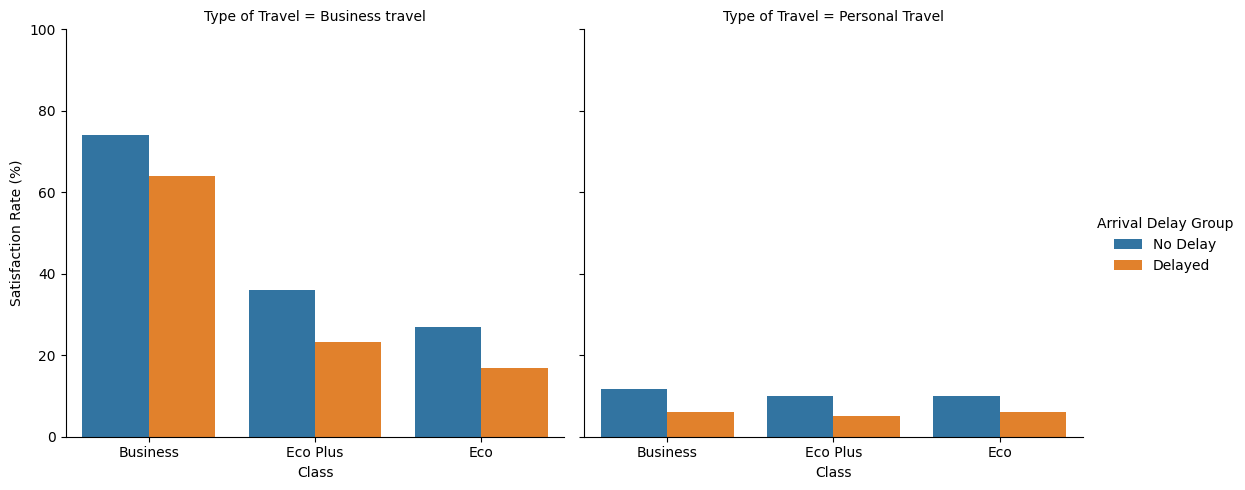

In [ ]:
# 分析データ
cols = [
    "Class",
    "Type of Travel",
    "Arrival Delay in Minutes",
    "satisfaction"
]

analysis_df = train[cols].copy().dropna()

# 到着遅延の有無
analysis_df["Arrival Delay Group"] = (
    analysis_df["Arrival Delay in Minutes"]
    .gt(0)
    .map({False: "No Delay", True: "Delayed"})
)

# クラス別・旅行目的別の集計
summary = (
    analysis_df
    .groupby(
        ["Class", "Type of Travel", "Arrival Delay Group"]
    )["satisfaction"]
    .agg(["mean", "count"])
    .reset_index()
)

summary["satisfaction_rate"] = summary["mean"] * 100

display(summary.round(2))

# 可視化
g = sns.catplot(
    data=summary,
    x="Class",
    y="satisfaction_rate",
    hue="Arrival Delay Group",
    col="Type of Travel",
    kind="bar",
    order=["Business", "Eco Plus", "Eco"],
    hue_order=["No Delay", "Delayed"],
    height=5,
    aspect=1.1
)

g.set_axis_labels("Class", "Satisfaction Rate (%)")
g.set(ylim=(0, 100))

plt.show()



# 遅延時間の追加分析：総合まとめ

## 1. 分析目的

航空会社の顧客満足度に対して、出発遅延および到着遅延がどのように関連しているかを明らかにする。

具体的には、以下の分析を実施した。

1. 出発遅延と到着遅延の相関分析
2. 遅延時間の分布の確認
3. 遅延の有無による満足率の比較
4. 搭乗クラス・旅行目的別の層別分析

---

## 2. 出発遅延と到着遅延の相関分析

| 変数の組み合わせ | Pearson | Spearman |
|---|---:|---:|
| 出発遅延 × 到着遅延 | 0.842 | 0.472 |

### 分析結果

- Pearson相関係数は0.842であり、強い正の線形相関が認められた。
- Spearman相関係数は0.472であり、中程度の正の順位相関が認められた。
- PearsonとSpearmanの相関係数には大きな差が見られた。

### 考察

出発遅延と到着遅延には強い線形的な関連がある一方、順位相関は相対的に小さい。

これは、遅延時間が0分に集中していることや、一部に大きな遅延が存在することが関係している可能性がある。

また、出発遅延と到着遅延は関連性が高いため、予測モデルに両方を投入する場合には、特徴量の冗長性や多重共線性に注意する必要がある。

---

## 3. 遅延時間の分布

| 指標 | 出発遅延 | 到着遅延 |
|---|---:|---:|
| 平均遅延時間 | 1.17分 | 1.13分 |
| 標準偏差 | 5.96分 | 5.75分 |
| 中央値 | 0分 | 0分 |
| 75パーセンタイル | 0分 | 0分 |
| 最大遅延時間 | 489分 | 491分 |
| 遅延なしの割合 | 90.8% | 91.6% |

### 分析結果

- 出発遅延の90.8%、到着遅延の91.6%が0分であった。
- いずれの遅延時間も中央値は0分であった。
- 一方で、最大約490分の大きな遅延が存在した。
- 遅延時間の分布は0分に集中し、右側に長い裾を持つ分布であった。

### 考察

大部分の乗客は遅延を経験していないため、平均遅延時間だけでは分布の特徴を十分に表現できない。

また、0分が非常に多いことから、遅延時間を連続値として扱うだけでなく、遅延の有無を表す二値変数を作成することが有効と考えられる。

---

## 4. 遅延の有無による満足率の比較

### 4.1 出発遅延

| 出発遅延 | 満足率 |
|---|---:|
| 遅延なし | 44.8% |
| 遅延あり | 40.0% |
| 差 | -4.8ポイント |

出発遅延が発生したグループでは、遅延がないグループより満足率が約4.8ポイント低かった。

### 4.2 到着遅延

| 到着遅延 | 満足率 |
|---|---:|
| 遅延なし | 45.2% |
| 遅延あり | 35.1% |
| 差 | -10.1ポイント |

到着遅延が発生したグループでは、遅延がないグループより満足率が約10.1ポイント低かった。

### 4.3 相関分析との比較

| 変数 | Pearson | Spearman |
|---|---:|---:|
| 出発遅延時間 × 満足度 | -0.036 | -0.029 |
| 到着遅延時間 × 満足度 | -0.052 | -0.058 |

### 考察

遅延時間と満足度の単純な相関係数は、いずれも0に近い値であった。

一方、遅延の有無でグループ分けした場合には、満足率に差が認められた。

特に、到着遅延では約10ポイントの差が見られ、出発遅延よりも大きかった。

この結果は、遅延時間の長さとの単純な線形・順位相関だけでは、満足度との関係を十分に捉えられない可能性を示している。

ただし、今回の結果は観察データに基づく関連であり、遅延による因果的な影響を証明するものではない。

---

## 5. 搭乗クラス・旅行目的別の層別分析

到着遅延の有無による満足率を、搭乗クラスと旅行目的で層別化して比較した。

### 5.1 ビジネス目的

| 搭乗クラス | 遅延なし | 遅延あり | 差 |
|---|---:|---:|---:|
| Business | 74.0% | 64.0% | -10.0pt |
| Eco Plus | 36.0% | 23.2% | -12.8pt |
| Eco | 27.0% | 17.0% | -10.0pt |

### 5.2 個人旅行目的

| 搭乗クラス | 遅延なし | 遅延あり | 差 |
|---|---:|---:|---:|
| Business | 11.6% | 6.1% | -5.5pt |
| Eco Plus | 10.0% | 5.2% | -4.8pt |
| Eco | 10.0% | 6.1% | -4.0pt |

### 5.3 分析結果

**① すべてのグループで、到着遅延ありの満足率が低かった。**

搭乗クラスや旅行目的にかかわらず、到着遅延が発生したグループの満足率は低かった。

**② ビジネス目的では、満足率の差が比較的大きかった。**

ビジネス目的では約10〜13ポイントの差が認められた。

一方、個人旅行では約4〜6ポイントの差であった。

**③ ビジネス目的のEco Plusで最も大きな差が見られた。**

Eco Plusのビジネス目的利用者では、満足率が36.0%から23.2%となり、12.8ポイントの差が認められた。

**④ ビジネスクラスのビジネス目的利用者は、遅延時でも満足率が高かった。**

到着遅延が発生していても満足率は64.0%であり、他の組み合わせと比較して高かった。

### 考察

ビジネス目的の利用者では、到着遅延と満足度の関連が個人旅行より強い可能性が示唆された。

仕事上の時間的制約などが関係している可能性はあるが、今回のデータだけでは理由を特定できない。

また、搭乗クラス、飛行距離、年齢、サービス評価などの交絡要因が存在する可能性がある。

そのため、層別分析の結果だけで、旅行目的によって遅延の影響が異なると断定することはできない。

---

## 6. 遅延時間の追加分析から得られた主な知見

### 知見①：出発遅延と到着遅延には強い関連がある

Pearson相関係数は0.842であり、出発遅延と到着遅延には強い線形相関が確認された。

ただし、Spearman相関係数は0.472であり、分布の特徴によって相関係数の大きさが異なることが示された。

### 知見②：遅延時間は0分に集中している

出発遅延・到着遅延の約9割が0分であった。

このため、遅延時間を連続値として扱うだけではなく、遅延の有無を区別する分析が重要と考えられる。

### 知見③：到着遅延の有無による満足率の差が大きい

出発遅延では約4.8ポイント、到着遅延では約10.1ポイントの満足率の差が認められた。

したがって、到着遅延は顧客満足度を分析する上で注目すべき説明変数と考えられる。

### 知見④：旅行目的によって遅延との関連が異なる可能性がある

ビジネス目的では約10〜13ポイント、個人旅行では約4〜6ポイントの差が観察された。

旅行目的と到着遅延の交互作用を検証する必要がある。

---

## 7. 今後の分析方針

### ① ロジスティック回帰分析

目的変数を顧客満足度（0/1）として、以下の説明変数を用いた多変量解析を実施する。

- 到着遅延の有無
- 搭乗クラス
- 旅行目的
- 年齢
- 飛行距離
- オンライン搭乗手続き
- 座席の快適性
- 機内エンターテインメント

他の説明変数を調整した上で、到着遅延と満足度の関連をオッズ比と95%信頼区間で評価する。

### ② 交互作用の検証

到着遅延と旅行目的の交互作用項を導入する。

これにより、旅行目的によって到着遅延と満足度の関連が異なるかを統計的に検証する。

### ③ 遅延時間の特徴量設計

予測モデル構築時には、以下の特徴量を比較する。

- 遅延時間の連続値
- 遅延の有無を表す二値変数
- 遅延時間帯を表すカテゴリ変数

交差検証によって、それぞれの特徴量設計が予測性能に与える影響を評価する。

---

## 8. 総合結論

今回の追加分析では、遅延時間と顧客満足度の単純な相関係数は小さかったものの、遅延の有無によって満足率に差が認められた。

特に、到着遅延が発生したグループでは、遅延がないグループより満足率が約10.1ポイント低かった。

さらに、搭乗クラス・旅行目的別の層別分析から、ビジネス目的の利用者では、個人旅行の利用者よりも到着遅延の有無による満足率の差が大きい傾向が観察された。

以上より、**到着遅延は顧客満足度との関連を検討する上で重要な変数であり、その関連の強さは旅行目的によって異なる可能性がある**と考えられる。

今後は多変量ロジスティック回帰分析および交互作用の検証を実施し、交絡要因を考慮した上で、これらの関連をより詳細に評価する。


## 多変量ロジスティック回帰分析

### データの確認・前処理

In [ ]:
# データをコピー
analysis_df = train.copy()

# ID列を除外
analysis_df = analysis_df.drop(
    columns=["id", "ID"],
    errors="ignore"
)

# 目的変数
target = "satisfaction"

# 説明変数
features = [
    col for col in analysis_df.columns
    if col != target
]

print("データ数:", len(analysis_df))
print("説明変数数:", len(features))

print("\n【目的変数の分布】")
print(analysis_df[target].value_counts(dropna=False))

print("\n【説明変数一覧】")
display(
    pd.DataFrame({
        "Variable": features,
        "Data Type": analysis_df[features].dtypes.astype(str).values,
        "Missing": analysis_df[features].isna().sum().values
    })
)

print("\n【カテゴリ変数の値】")
for col in analysis_df.select_dtypes(
    include=["object", "category"]
).columns:
    print(f"\n{col}")
    print(analysis_df[col].value_counts(dropna=False).head(10))


データ数: 699635
説明変数数: 21

【目的変数の分布】
satisfaction
False    389296
True     310339
Name: count, dtype: int64

【説明変数一覧】


,Variable,Data Type,Missing
0,Age,int64,0
1,Flight Distance,int64,0
2,Inflight wifi service,int64,0
3,Departure/Arrival time convenient,int64,0
4,Ease of Online booking,int64,0
5,Gate location,int64,0
6,Food and drink,int64,0
7,Online boarding,int64,0
8,Seat comfort,int64,0
9,Inflight entertainment,int64,0



【カテゴリ変数の値】

Gender
Gender
Male      351683
Female    347952
Name: count, dtype: int64

Customer Type
Customer Type
Loyal Customer       576990
disloyal Customer    122645
Name: count, dtype: int64

Type of Travel
Type of Travel
Business travel    497441
Personal Travel    202194
Name: count, dtype: int64

Class
Class
Business    342212
Eco         327404
Eco Plus     30019
Name: count, dtype: int64


目的変数の割合は約56：44であり、極端なクラス不均衡はありません。

到着遅延の欠損は全体の約0.042%と少数です。今回は欠損292件を除外して進めて問題ないと考えます。ただし、欠損がランダムに生じているとは限らない点には注意します。

### Model 1(到着遅延＋顧客属性)

In [ ]:
# 元データをコピー
df = train.copy()

# 目的変数を0/1に変換
df["satisfaction"] = df["satisfaction"].astype(int)

# 到着遅延が欠損している行を除外
df = df.dropna(
    subset=["Arrival Delay in Minutes"]
).copy()

# 到着遅延の有無
df["arrival_delayed"] = (
    df["Arrival Delay in Minutes"] > 0
).astype(int)

# 数式で扱いやすい列名に変更
df = df.rename(columns={
    "Age": "age",
    "Gender": "gender",
    "Customer Type": "customer_type",
    "Type of Travel": "travel_type",
    "Class": "travel_class",
    "Flight Distance": "flight_distance"
})

# Model 1：基本属性を調整
formula1 = """
satisfaction ~ arrival_delayed
+ age
+ flight_distance
+ C(gender)
+ C(customer_type)
+ C(travel_type)
+ C(travel_class)
"""

model1 = smf.logit(
    formula=formula1,
    data=df
).fit(disp=False, maxiter=200)

print(model1.summary())


                           Logit Regression Results                           
Dep. Variable:           satisfaction   No. Observations:               699343
Model:                          Logit   Df Residuals:                   699334
Method:                           MLE   Df Model:                            8
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3199
Time:                        11:34:40   Log-Likelihood:            -3.2664e+05
converged:                       True   LL-Null:                   -4.8029e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
Intercept                                 1.0756      0.015     73.363      0.000       1.047       1.104
C(gender)[T.Male]                         0.0441  

In [ ]:
ci = model1.conf_int()

or_table = pd.DataFrame({
    "OR": np.exp(model1.params),
    "CI_lower": np.exp(ci[0]),
    "CI_upper": np.exp(ci[1]),
    "p_value": model1.pvalues
})

display(or_table.round(4))

print("\n【到着遅延の調整オッズ比】")
display(or_table.loc[["arrival_delayed"]].round(4))


,OR,CI_lower,CI_upper,p_value
Intercept,2.9318,2.8488,3.0173,0.0
C(gender)[T.Male],1.0451,1.0325,1.0579,0.0
C(customer_type)[T.disloyal Customer],0.1685,0.1653,0.1717,0.0
C(travel_type)[T.Personal Travel],0.1315,0.1290,0.1341,0.0
C(travel_class)[T.Eco],0.2240,0.2204,0.2277,0.0
C(travel_class)[T.Eco Plus],0.1932,0.1874,0.1993,0.0
arrival_delayed,0.5678,0.5555,0.5804,0.0
age,1.0046,1.0041,1.0051,0.0
flight_distance,1.0000,1.0000,1.0000,0.0



【到着遅延の調整オッズ比】


,OR,CI_lower,CI_upper,p_value
arrival_delayed,0.5678,0.5555,0.5804,0.0



### Model 1：基本属性を調整したロジスティック回帰分析

#### 分析目的
到着遅延と顧客満足度の関連について、年齢、性別、顧客タイプ、旅行目的、搭乗クラス、飛行距離を調整した上で検証した。

#### 分析結果
- 分析対象：699,343件
- McFadden Pseudo R²：0.3199
- モデル全体の尤度比検定：p < 0.001
- 到着遅延の調整オッズ比：0.5678
- 95%信頼区間：0.5555〜0.5804
- p < 0.001

#### 考察
基本属性を調整した後でも、到着遅延ありの乗客では、遅延なしの乗客と比較して満足オッズが約43.2%低い結果となった。

95%信頼区間は1を含まず、統計的に有意な負の関連が認められた。

また、顧客タイプ、旅行目的、搭乗クラスも満足度と強く関連していた。

一方、今回のモデルでは各種サービス評価を調整していないため、到着遅延と満足度の関連に未調整の要因が残っている可能性がある。

#### 結論
到着遅延の有無は、基本属性を調整した後でも顧客満足度と有意に関連していた。

次の分析ではサービス評価項目を追加し、到着遅延の調整オッズ比がどのように変化するかを検証する。


### Model 2(Model 1＋全サービス評価)

In [ ]:
# サービス評価14項目
service_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

# Model 1の基本属性
base_formula = """
satisfaction ~ arrival_delayed
+ age
+ flight_distance
+ C(gender)
+ C(customer_type)
+ C(travel_type)
+ C(travel_class)
"""

# サービス評価を数式に追加
service_terms = [
    f'Q("{col}")'
    for col in service_cols
]

formula2 = (
    base_formula
    + "\n+ "
    + "\n+ ".join(service_terms)
)

# Model 2
model2 = smf.logit(
    formula=formula2,
    data=df
).fit(disp=False, maxiter=200)

print(model2.summary())


                           Logit Regression Results                           
Dep. Variable:           satisfaction   No. Observations:               699343
Model:                          Logit   Df Residuals:                   699321
Method:                           MLE   Df Model:                           21
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.4989
Time:                        11:34:56   Log-Likelihood:            -2.4067e+05
converged:                       True   LL-Null:                   -4.8029e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                                 -5.7145      0.030   -190.670      0.000      -5.773      -5.656
C(gender)[T.Male]                          0.09

In [ ]:
def extract_or(model, variable):
    ci = model.conf_int().loc[variable]
    return {
        "OR": np.exp(model.params[variable]),
        "CI_lower": np.exp(ci[0]),
        "CI_upper": np.exp(ci[1]),
        "p_value": model.pvalues[variable]
    }

comparison = pd.DataFrame({
    "Model 1": extract_or(model1, "arrival_delayed"),
    "Model 2": extract_or(model2, "arrival_delayed")
}).T

display(comparison.round(4))

print("Model 1 Pseudo R²:", round(model1.prsquared, 4))
print("Model 2 Pseudo R²:", round(model2.prsquared, 4))


,OR,CI_lower,CI_upper,p_value
Model 1,0.5678,0.5555,0.5804,0.0
Model 2,0.6406,0.6238,0.6579,0.0


Model 1 Pseudo R²: 0.3199
Model 2 Pseudo R²: 0.4989


In [ ]:
# Model 2の95%信頼区間
ci = model2.conf_int()

# 回帰係数をORに変換
or_table2 = pd.DataFrame({
    "Coefficient": model2.params,
    "OR": np.exp(model2.params),
    "CI_lower": np.exp(ci[0]),
    "CI_upper": np.exp(ci[1]),
    "p_value": model2.pvalues
})

# 表示桁数を設定
display(
    or_table2.style.format({
        "Coefficient": "{:.4f}",
        "OR": "{:.4f}",
        "CI_lower": "{:.4f}",
        "CI_upper": "{:.4f}",
        "p_value": "{:.3e}"
    })
)

,Coefficient,OR,CI_lower,CI_upper,p_value
Intercept,-5.7145,0.0033,0.0031,0.0035,0.000e+00
C(gender)[T.Male],0.0956,1.1003,1.0844,1.1164,7.131e-38
C(customer_type)[T.disloyal Customer],-1.8195,0.1621,0.1583,0.1660,0.000e+00
C(travel_type)[T.Personal Travel],-2.3182,0.0985,0.0959,0.1010,0.000e+00
C(travel_class)[T.Eco],-0.6332,0.5309,0.5198,0.5422,0.000e+00
C(travel_class)[T.Eco Plus],-0.7052,0.4940,0.4754,0.5133,2.699e-284
arrival_delayed,-0.4453,0.6406,0.6238,0.6579,1.883e-236
age,-0.0085,0.9916,0.9910,0.9922,4.356e-159
flight_distance,0.0000,1.0000,1.0000,1.0000,9.861e-01
"Q(""Inflight wifi service"")",0.3242,1.3829,1.3699,1.3960,0.000e+00


In [ ]:
# 切片を除外してORの降順に並べる
or_sorted = (
    or_table2
    .drop(index="Intercept", errors="ignore")
    .sort_values("OR", ascending=False)
)

display(
    or_sorted.style.format({
        "Coefficient": "{:.4f}",
        "OR": "{:.4f}",
        "CI_lower": "{:.4f}",
        "CI_upper": "{:.4f}",
        "p_value": "{:.3e}"
    })
)

,Coefficient,OR,CI_lower,CI_upper,p_value
"Q(""Online boarding"")",0.6430,1.9023,1.8859,1.9187,0.000e+00
"Q(""Inflight wifi service"")",0.3242,1.3829,1.3699,1.3960,0.000e+00
"Q(""On-board service"")",0.2996,1.3494,1.3386,1.3602,0.000e+00
"Q(""Checkin service"")",0.2996,1.3493,1.3403,1.3584,0.000e+00
"Q(""Leg room service"")",0.1942,1.2143,1.2062,1.2224,0.000e+00
"Q(""Cleanliness"")",0.1939,1.2139,1.2021,1.2259,0.000e+00
"Q(""Baggage handling"")",0.1909,1.2104,1.1993,1.2215,0.000e+00
C(gender)[T.Male],0.0956,1.1003,1.0844,1.1164,7.131e-38
"Q(""Seat comfort"")",0.0693,1.0717,1.0605,1.0831,1.003e-37
"Q(""Inflight entertainment"")",0.0644,1.0665,1.0540,1.0792,1.535e-26



# Model 2：多変量ロジスティック回帰分析の結果・考察

## 1. 分析目的

Model 1では、年齢、性別、顧客タイプ、旅行目的、搭乗クラス、飛行距離を調整し、到着遅延と顧客満足度の関連を検証した。

Model 2では、これらの基本属性に加えて、13項目のサービス評価を説明変数として投入した。

これにより、以下の点を検証する。

1. サービス評価を調整した後も、到着遅延と顧客満足度の関連が認められるか。
2. サービス評価の追加によってモデルの適合度がどのように変化するか。
3. 各サービス評価項目と顧客満足度の条件付きの関連を確認する。

---

## 2. モデルの概要

### 目的変数
- 顧客満足度（satisfaction）
  - 0：不満足
  - 1：満足

### 説明変数

**基本属性・到着遅延**
- 到着遅延の有無
- 年齢
- 性別
- 顧客タイプ
- 旅行目的
- 搭乗クラス
- 飛行距離

**サービス評価13項目**
- Inflight wifi service
- Departure/Arrival time convenient
- Ease of Online booking
- Gate location
- Food and drink
- Online boarding
- Seat comfort
- Inflight entertainment
- On-board service
- Leg room service
- Baggage handling
- Checkin service
- Cleanliness

### 分析手法
- 多変量ロジスティック回帰分析
- 最尤推定法
- オッズ比（OR）
- 95%信頼区間
- p値
- McFadden Pseudo R²

分析対象は、到着遅延時間に欠損のある292件を除外した699,343件とした。

---

## 3. Model 1とModel 2の比較

| 評価指標 | Model 1 | Model 2 |
|---|---:|---:|
| 観測数 | 699,343 | 699,343 |
| 説明変数の自由度 | 8 | 21 |
| McFadden Pseudo R² | 0.3199 | 0.4989 |
| 到着遅延の調整OR | 0.5678 | 0.6406 |
| ORの95%信頼区間 | 0.5555–0.5804 | 0.6238–0.6579 |
| 到着遅延のp値 | <0.001 | <0.001 |

### 分析結果

サービス評価13項目を追加したことで、McFadden Pseudo R²は0.3199から0.4989に上昇した。

これは、Model 2がModel 1よりも観測データに対して良好な適合を示したことを意味する。

ただし、Pseudo R²は通常の線形回帰の決定係数とは異なり、顧客満足度の49.89%を説明できたという意味ではない。

また、未知データに対する予測性能を直接示す指標ではない。

---

## 4. 到着遅延と顧客満足度の関連

### Model 1
- 調整OR：0.5678
- 95%信頼区間：0.5555–0.5804
- p < 0.001

### Model 2
- 調整OR：0.6406
- 95%信頼区間：0.6238–0.6579
- p < 0.001

### 解釈

Model 2では、基本属性およびサービス評価を一定とした場合、到着遅延ありの乗客の満足オッズは、遅延なしの乗客の約0.641倍であった。

これは、到着遅延ありの乗客では、満足オッズが約35.9%低いことを意味する。

95%信頼区間は1を含まず、統計的に有意な負の関連が認められた。

Model 1のORは0.5678、Model 2のORは0.6406であり、サービス評価を追加すると、到着遅延と満足度の負の関連は弱まった。

ただし、ロジスティック回帰のオッズ比には非可縮性があるため、ORの変化をすべて交絡や媒介効果によるものと解釈することはできない。

また、今回の分析は観察データに基づいており、因果関係を証明するものではない。

---

## 5. サービス評価項目の分析結果

以下は、Model 2の回帰係数から算出したオッズ比である。

表示された回帰係数に基づく概算値であり、正確な値は学習済みモデルの係数から算出する。

| サービス評価項目 | OR（約） | 関連の方向 |
|---|---:|---|
| Online boarding | 1.902 | 正 |
| Inflight wifi service | 1.383 | 正 |
| Checkin service | 1.349 | 正 |
| On-board service | 1.344 | 正 |
| Cleanliness | 1.214 | 正 |
| Leg room service | 1.214 | 正 |
| Baggage handling | 1.210 | 正 |
| Seat comfort | 1.072 | 正 |
| Inflight entertainment | 1.067 | 正 |
| Gate location | 1.037 | 正 |
| Food and drink | 0.942 | 負 |
| Ease of Online booking | 0.911 | 負 |
| Departure/Arrival time convenient | 0.871 | 負 |

### 5.1 Online boarding

Online boardingのORは約1.902であった。

他の説明変数を一定とした場合、評価が1段階高くなると、満足オッズが約1.90倍となる推定結果であった。

単純相関分析でも満足度との関連が強く、今回の多変量解析でも正の関連が認められた。

### 5.2 Inflight wifi service

Inflight wifi serviceのORは約1.383であった。

他の説明変数を調整した後も、評価が高いほど満足オッズが高いという正の関連が認められた。

### 5.3 Checkin service・On-board service

Checkin serviceとOn-board serviceも、満足度と正の関連を示した。

ただし、サービス評価項目間には相関が存在するため、オッズ比の大小をそのままサービスの重要度ランキングとして扱うことは適切ではない。

### 5.4 負の係数が得られた項目

以下の項目では、単純相関分析と異なり、Model 2で負の回帰係数が得られた。

- Food and drink
- Ease of Online booking
- Departure/Arrival time convenient

これは、他のサービス評価を一定とした場合の条件付きの関連が、単純相関と異なることを示している。

サービス評価同士の多重共線性、交絡、モデル仕様などが関係している可能性がある。

したがって、これらのサービス評価を高めることで顧客満足度が低下すると因果的に解釈することはできない。

---

## 6. 多重共線性に関する考察

以前のEDAでは、説明変数間に以下のような強い相関が確認された。

| 変数の組み合わせ | Pearson相関 |
|---|---:|
| Inflight wifi service × Ease of Online booking | 0.772 |
| Seat comfort × Cleanliness | 0.763 |
| Inflight entertainment × Cleanliness | 0.751 |
| Seat comfort × Inflight entertainment | 0.745 |

これらの相関から、サービス評価項目間に多重共線性が存在する可能性がある。

多重共線性が強い場合、個々の回帰係数や標準誤差が不安定になり、解釈が難しくなることがある。

今後はVIFや係数の安定性を確認する必要がある。

ただし、説明変数間の相関が高いという理由だけで、直ちに変数を削除するべきではない。

また、サービス評価を順序尺度として数値投入しているため、評価が1段階上がるごとに対数オッズが一定量変化するという仮定にも注意が必要である。

---

## 7. 総合考察

今回のModel 2では、基本属性に加えて13項目のサービス評価を調整した結果、到着遅延と顧客満足度の間に統計的に有意な負の関連が認められた。

到着遅延の調整ORはModel 1の0.5678からModel 2の0.6406へ変化したが、95%信頼区間は依然として1を含まなかった。

このことから、到着遅延の有無は、基本属性やサービス評価を考慮した後でも、顧客満足度と関連していることが示された。

また、サービス評価の追加によりMcFadden Pseudo R²が0.3199から0.4989へ上昇し、観測データに対するモデル適合度が改善した。

サービス評価項目では、Online boardingやInflight wifi serviceなどに正の関連が認められた。

一方、一部のサービス評価では単純相関と多変量回帰の係数の符号が異なっており、説明変数間の相関構造やモデル仕様について追加検証が必要と考えられる。

---

## 8. 結論

**基本属性および13項目のサービス評価を調整した後でも、到着遅延ありの乗客では、遅延なしの乗客より満足オッズが約35.9%低かった（調整OR=0.6406、95%CI：0.6238–0.6579、p<0.001）。**

また、サービス評価の追加によりモデル適合度が改善し、顧客満足度には到着遅延だけでなく、複数のサービス評価項目も関連していることが確認された。

ただし、今回の結果は統計的な関連を示すものであり、因果効果や未知データへの予測性能を直接示すものではない。

### 次の分析方針

1. Model 3：到着遅延と旅行目的の交互作用を検証する。
2. 旅行目的別の調整後予測満足確率を算出する。
3. サービス評価項目の多重共線性を確認する。
4. Logistic Regression、LightGBM、CatBoostによる予測モデルを構築し、交差検証で性能を比較する。


### Model 3(到着遅延と旅行目的の交互作用分析)

In [ ]:
# Model 2の数式に交互作用項を追加
formula3 = formula2 + """
+ arrival_delayed:C(travel_type)
"""

# Model 3の学習
model3 = smf.logit(
    formula=formula3,
    data=df
).fit(disp=False, maxiter=200)

print(model3.summary())


                           Logit Regression Results                           
Dep. Variable:           satisfaction   No. Observations:               699343
Model:                          Logit   Df Residuals:                   699320
Method:                           MLE   Df Model:                           22
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.4989
Time:                        11:35:13   Log-Likelihood:            -2.4066e+05
converged:                       True   LL-Null:                   -4.8029e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
Intercept                                            -5.7173      0.030   -190.694      0.000      -5.776      -5.659
C(gender)[T.Ma

In [ ]:
# 尤度比検定
lr_stat = 2 * (model3.llf - model2.llf)

df_diff = int(
    model3.df_model - model2.df_model
)

p_value = chi2.sf(lr_stat, df_diff)

comparison = pd.DataFrame({
    "Model": ["Model 2", "Model 3"],
    "Pseudo R²": [
        model2.prsquared,
        model3.prsquared
    ],
    "AIC": [
        model2.aic,
        model3.aic
    ],
    "BIC": [
        model2.bic,
        model3.bic
    ]
})

display(comparison.round(4))

print("【尤度比検定】")
print(f"LR statistic: {lr_stat:.4f}")
print(f"Degrees of freedom: {df_diff}")
print(f"p-value: {p_value:.6g}")


,Model,Pseudo R²,AIC,BIC
0,Model 2,0.4989,481381.0386,481633.1124
1,Model 3,0.4989,481368.3000,481631.8316


【尤度比検定】
LR statistic: 14.7387
Degrees of freedom: 1
p-value: 0.000123487


In [ ]:
# 旅行目的のカテゴリを確認
print(df["travel_type"].value_counts())

# モデル内の交互作用項を確認
print([
    name for name in model3.params.index
    if "arrival_delayed" in name
])

# Business travelを基準とした場合
base = "arrival_delayed"
interaction = (
    "arrival_delayed:C(travel_type)[T.Personal Travel]"
)

# 係数と分散共分散行列
params = model3.params
cov = model3.cov_params()

# Business travel
beta_business = params[base]
se_business = np.sqrt(cov.loc[base, base])

# Personal Travel
beta_personal = params[base] + params[interaction]

var_personal = (
    cov.loc[base, base]
    + cov.loc[interaction, interaction]
    + 2 * cov.loc[base, interaction]
)

se_personal = np.sqrt(var_personal)

results = pd.DataFrame({
    "Travel Type": [
        "Business travel",
        "Personal Travel"
    ],
    "OR": [
        np.exp(beta_business),
        np.exp(beta_personal)
    ],
    "CI_lower": [
        np.exp(beta_business - 1.96 * se_business),
        np.exp(beta_personal - 1.96 * se_personal)
    ],
    "CI_upper": [
        np.exp(beta_business + 1.96 * se_business),
        np.exp(beta_personal + 1.96 * se_personal)
    ]
})

display(results.round(4))


travel_type
Business travel    497258
Personal Travel    202085
Name: count, dtype: int64
['arrival_delayed', 'arrival_delayed:C(travel_type)[T.Personal Travel]']


,Travel Type,OR,CI_lower,CI_upper
0,Business travel,0.6554,0.6366,0.6748
1,Personal Travel,0.5677,0.5303,0.6078


In [ ]:
adjusted_results = []

for travel_type in [
    "Business travel",
    "Personal Travel"
]:
    for delayed in [0, 1]:
        temp = df.copy()

        temp["travel_type"] = travel_type
        temp["arrival_delayed"] = delayed

        predicted = model3.predict(temp)

        adjusted_results.append({
            "Travel Type": travel_type,
            "Arrival Delay": (
                "Delayed" if delayed == 1
                else "No Delay"
            ),
            "Adjusted Satisfaction Rate (%)": (
                predicted.mean() * 100
            )
        })

adjusted_df = pd.DataFrame(adjusted_results)

display(adjusted_df.round(2))


,Travel Type,Arrival Delay,Adjusted Satisfaction Rate (%)
0,Business travel,No Delay,53.97
1,Business travel,Delayed,48.19
2,Personal Travel,No Delay,23.45
3,Personal Travel,Delayed,17.19



# Model 3：到着遅延と旅行目的の交互作用分析

## 1. 分析目的

到着遅延と顧客満足度の関連が、旅行目的
（Business Travel / Personal Travel）によって異なるかを検証した。

Model 2の説明変数に、到着遅延と旅行目的の交互作用項を追加した。

## 2. 仮説

- H0：旅行目的によって到着遅延の条件付きオッズ比は変わらない。
- H1：旅行目的によって到着遅延の条件付きオッズ比が異なる。

## 3. Model 2とModel 3の比較

| 指標 | Model 2 | Model 3 |
|---|---:|---:|
| 観測数 | 699,343 | 699,343 |
| McFadden Pseudo R² | 0.4989 | 0.4989 |
| AIC | 481381.0386 | 481368.3000 |
| BIC | 481633.1124 | 481631.8316 |

尤度比検定：
- LR統計量：14.7387
- 自由度：1
- p値：0.000123487

交互作用項の追加により、モデルの適合度は統計的に有意に改善した。

ただし、Pseudo R²の変化は非常に小さく、実質的な改善は限定的であった。

## 4. 旅行目的別の調整オッズ比

| 旅行目的 | OR | 95%信頼区間 |
|---|---:|---|
| Business travel | 0.6554 | 0.6366–0.6748 |
| Personal Travel | 0.5677 | 0.5303–0.6078 |

Business travelでは、到着遅延ありの乗客の満足オッズは、遅延なしの乗客と比較して約34.5%低かった。

Personal Travelでは、約43.2%低かった。

交互作用項の係数は-0.1436であり、Personal Travelの到着遅延ORはBusiness travelの約0.866倍であった。

したがって、基本属性とサービス評価を調整した場合、個人旅行の方が到着遅延と満足オッズの負の関連が強かった。

## 5. 調整後予測満足率

| 旅行目的 | 遅延なし | 遅延あり | 差 |
|---|---:|---:|---:|
| Business travel | 53.97% | 48.19% | -5.78ポイント |
| Personal Travel | 23.45% | 17.19% | -6.26ポイント |

共通の共変量分布を用いて標準化した予測満足率でも、個人旅行の方が低下幅がわずかに大きかった。

ただし、これはモデルに基づく予測値であり、因果効果ではない。

## 6. 総合考察

Model 3では、到着遅延と旅行目的の交互作用が統計的に有意であった（p=0.000123487）。

旅行目的別の調整ORは、Business travelで0.6554、Personal Travelで0.5677となり、個人旅行の方が到着遅延と満足度の負の関連が強かった。

一方、Model 2からModel 3への適合度改善は小さく、交互作用の実質的な寄与は限定的である。

EDAで確認した満足率の差と今回の調整ORの傾向が異なるのは、共変量調整の有無や評価尺度の違いなどが考えられる。

## 7. 結論

到着遅延と顧客満足度の関連は、旅行目的によって統計的に有意に異なった。

基本属性とサービス評価を調整した結果、個人旅行の方が到着遅延と満足オッズの負の関連が強かった。

ただし、統計的有意性に比べてモデル適合度の改善は小さく、因果関係も断定できない。


- ここまでの結論
  - 今回の分析から、次のことが確認できました。
1. 到着遅延ありの乗客では、満足率が低い傾向が見られた。
2. 基本属性とサービス評価を調整した後も、到着遅延と満足度には有意な負の関連が残った。
3. 旅行目的によって、到着遅延の条件付きオッズ比が異なることが確認された。
4. サービス評価の追加によってモデルの適合度が改善した。
5. 一部のサービス評価では単純相関と多変量回帰の係数の符号が異なり、多重共線性などの追加検討が必要である。

## 機械学習による顧客満足度の予測モデル構築

### データの分割

In [ ]:
# 元データをコピー
data_ml = train.copy()

# 目的変数
y = data_ml["satisfaction"].astype(int)

# 説明変数
X = data_ml.drop(
    columns=["satisfaction", "id"],
    errors="ignore"
)

print("説明変数の数:", X.shape[1])
print("データ件数:", len(X))

display(X.head())


説明変数の数: 21
データ件数: 699635


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,36,694,4,4,4,3,1,4,1,1,...,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco
1,56,651,5,5,5,5,5,4,4,5,...,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business
2,31,1371,3,4,2,5,3,3,3,3,...,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco
3,10,1616,3,5,3,3,3,3,3,3,...,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
4,23,481,3,4,3,4,5,3,5,5,...,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("学習データ:", X_train.shape)
print("テストデータ:", X_test.shape)

print("\n学習データの満足率:")
print(y_train.mean())

print("\nテストデータの満足率:")
print(y_test.mean())

学習データ: (559708, 21)
テストデータ: (139927, 21)

学習データの満足率:
0.44357236273199596

テストデータの満足率:
0.4435741493778899


In [ ]:
# 数値変数
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# カテゴリ変数
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("数値変数:", len(numeric_cols))
print(numeric_cols)

print("\nカテゴリ変数:", len(categorical_cols))
print(categorical_cols)

print("\n欠損値:")
display(X_train.isnull().sum().sort_values(ascending=False))


数値変数: 17
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

カテゴリ変数: 4
['Gender', 'Customer Type', 'Type of Travel', 'Class']

欠損値:


,0
Arrival Delay in Minutes,227
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Age,0
Ease of Online booking,0
Gate location,0
Online boarding,0
Food and drink,0
Inflight entertainment,0


### Logistic Regression用の前処理

In [ ]:
# # 数値変数の前処理
# numeric_transformer = Pipeline([
#     ("imputer", SimpleImputer(strategy="median")),
#     ("scaler", StandardScaler())
# ])

# # カテゴリ変数の前処理
# categorical_transformer = Pipeline([
#     ("imputer", SimpleImputer(strategy="most_frequent")),
#     ("onehot", OneHotEncoder(
#         handle_unknown="ignore"
#     ))
# ])

# # 前処理を統合
# preprocessor = ColumnTransformer([
#     ("num", numeric_transformer, numeric_cols),
#     ("cat", categorical_transformer, categorical_cols)
# ])

# print("前処理パイプライン構築完了")


### Logistic Regressionのベースライン構築

In [ ]:
# # 前処理 + モデル
# lr_pipeline = Pipeline([
#     ("preprocessor", preprocessor),
#     ("model", LogisticRegression(
#         max_iter=1000,
#         random_state=42
#     ))
# ])

# # 5分割層化交差検証
# cv = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# # 学習データ内で交差検証
# cv_results = cross_validate(
#     lr_pipeline,
#     X_train,
#     y_train,
#     cv=cv,
#     scoring={
#         "roc_auc": "roc_auc",
#         "neg_log_loss": "neg_log_loss",
#         "accuracy": "accuracy"
#     },
#     n_jobs=-1
# )

# print("【Logistic Regression：5-Fold CV】")

# print(
#     "ROC-AUC:",
#     round(cv_results["test_roc_auc"].mean(), 5)
# )

# print(
#     "Log Loss:",
#     round(-cv_results["test_neg_log_loss"].mean(), 5)
# )

# print(
#     "Accuracy:",
#     round(cv_results["test_accuracy"].mean(), 5)
# )

# print(
#     "ROC-AUC 標準偏差:",
#     round(cv_results["test_roc_auc"].std(), 5)
# )


### LightGBMを構築(前処理とモデル構築)

In [ ]:
# # カテゴリ変数の前処理
# cat_transformer_lgb = Pipeline([
#     ("imputer", SimpleImputer(strategy="most_frequent")),
#     ("onehot", OneHotEncoder(handle_unknown="ignore"))
# ])

# # 数値変数はそのまま使用
# preprocessor_lgb = ColumnTransformer([
#     ("num", "passthrough", numeric_cols),
#     ("cat", cat_transformer_lgb, categorical_cols)
# ])

# # LightGBM
# lgb_pipeline = Pipeline([
#     ("preprocessor", preprocessor_lgb),
#     ("model", lgb.LGBMClassifier(
#         objective="binary",
#         n_estimators=300,
#         learning_rate=0.05,
#         num_leaves=31,
#         random_state=42,
#         n_jobs=1,
#         verbosity=-1
#     ))
# ])

# print("LightGBM Pipeline 構築完了")


In [ ]:
# lgb_cv_results = cross_validate(
#     lgb_pipeline,
#     X_train,
#     y_train,
#     cv=cv,
#     scoring={
#         "roc_auc": "roc_auc",
#         "neg_log_loss": "neg_log_loss",
#         "accuracy": "accuracy"
#     },
#     n_jobs=-1
# )

# print("【LightGBM：5-Fold CV】")

# print(
#     "ROC-AUC:",
#     round(lgb_cv_results["test_roc_auc"].mean(), 5)
# )

# print(
#     "Log Loss:",
#     round(-lgb_cv_results["test_neg_log_loss"].mean(), 5)
# )

# print(
#     "Accuracy:",
#     round(lgb_cv_results["test_accuracy"].mean(), 5)
# )

# print(
#     "ROC-AUC 標準偏差:",
#     round(lgb_cv_results["test_roc_auc"].std(), 5)
# )



## LightGBM：5-Fold交差検証結果

### 分析目的
Logistic Regressionをベースラインとして、非線形な関係や説明変数間の交互作用を学習できるLightGBMを構築し、予測性能を比較した。

### 分析条件
- モデル：LightGBM（勾配ブースティング決定木）
- 検証方法：Stratified 5-Fold Cross Validation
- データ分割：学習80%、最終テスト20%
- 数値変数：標準化なし
- カテゴリ変数：One-Hot Encoding
- 評価指標：ROC-AUC、Log Loss、Accuracy

### 評価結果

| 指標 | Logistic Regression | LightGBM |
|---|---:|---:|
| ROC-AUC | 0.92186 | 0.95827 |
| Log Loss | 0.34361 | 0.22892 |
| Accuracy | 0.87851 | 0.92544 |
| ROC-AUC標準偏差 | 0.00070 | 0.00040 |

### 考察

LightGBMではROC-AUCが0.95827となり、Logistic Regressionの0.92186を上回った。

Accuracyは約92.54%となり、Logistic Regressionから約4.69ポイント改善した。

また、Log Lossは0.34361から0.22892へ低下し、予測確率の品質も改善した。

この結果は、LightGBMが説明変数と顧客満足度の非線形な関係や交互作用を捉えている可能性を示している。

ROC-AUCの標準偏差も0.00040と小さく、今回の5分割交差検証では安定した性能が得られた。

ただし、最終テストデータによる評価はまだ実施していない。

### 次の分析
CatBoostを構築し、Logistic Regression・LightGBM・CatBoostの3モデルで予測性能を比較する。


## CatBoostの構築

In [ ]:
# 元の学習データをコピー
X_train_cat = X_train.copy()

# カテゴリ変数を文字列に変換
for col in categorical_cols:
    X_train_cat[col] = (
        X_train_cat[col]
        .fillna("Missing")
        .astype(str)
    )

print("カテゴリ変数:")
print(categorical_cols)

print("データ形状:", X_train_cat.shape)


カテゴリ変数:
['Gender', 'Customer Type', 'Type of Travel', 'Class']
データ形状: (559708, 21)


In [ ]:
# # cat_featuresはここでは指定しない
# cat_model = CatBoostClassifier(
#     iterations=500,
#     depth=6,
#     learning_rate=0.05,
#     loss_function="Logloss",
#     eval_metric="AUC",
#     random_seed=42,
#     verbose=False,
#     thread_count=2
# )

# print("CatBoostモデル構築完了")


In [ ]:
# cat_cv_results = cross_validate(
#     cat_model,
#     X_train_cat,
#     y_train,
#     cv=cv,
#     scoring={
#         "roc_auc": "roc_auc",
#         "neg_log_loss": "neg_log_loss",
#         "accuracy": "accuracy"
#     },
#     params={
#         "cat_features": categorical_cols
#     },
#     n_jobs=1,
#     error_score="raise"
# )

# print("【CatBoost：5-Fold CV】")

# print(
#     "ROC-AUC:",
#     round(cat_cv_results["test_roc_auc"].mean(), 5)
# )

# print(
#     "Log Loss:",
#     round(-cat_cv_results["test_neg_log_loss"].mean(), 5)
# )

# print(
#     "Accuracy:",
#     round(cat_cv_results["test_accuracy"].mean(), 5)
# )

# print(
#     "ROC-AUC標準偏差:",
#     round(cat_cv_results["test_roc_auc"].std(), 5)
# )


In [ ]:
# comparison_ml = pd.DataFrame({
#     "Model": [
#         "Logistic Regression",
#         "LightGBM",
#         "CatBoost"
#     ],
#     "ROC-AUC": [
#         cv_results["test_roc_auc"].mean(),
#         lgb_cv_results["test_roc_auc"].mean(),
#         cat_cv_results["test_roc_auc"].mean()
#     ],
#     "Log Loss": [
#         -cv_results["test_neg_log_loss"].mean(),
#         -lgb_cv_results["test_neg_log_loss"].mean(),
#         -cat_cv_results["test_neg_log_loss"].mean()
#     ],
#     "Accuracy": [
#         cv_results["test_accuracy"].mean(),
#         lgb_cv_results["test_accuracy"].mean(),
#         cat_cv_results["test_accuracy"].mean()
#     ],
#     "ROC-AUC SD": [
#         cv_results["test_roc_auc"].std(),
#         lgb_cv_results["test_roc_auc"].std(),
#         cat_cv_results["test_roc_auc"].std()
#     ]
# })

# display(
#     comparison_ml.sort_values(
#         "ROC-AUC",
#         ascending=False
#     ).round(5)
# )



## 予測モデルの比較結果

### 分析目的

顧客満足度の二値分類について、Logistic Regression、LightGBM、CatBoostの3モデルを構築し、予測性能を比較した。

### 評価方法

- 学習データ：全体の80%
- 最終テストデータ：全体の20%（未使用）
- 交差検証：Stratified 5-Fold CV
- 主評価指標：ROC-AUC
- 副評価指標：Log Loss、Accuracy

### 評価結果

| モデル | ROC-AUC | Log Loss | Accuracy | ROC-AUC SD |
|---|---:|---:|---:|---:|
| LightGBM | 0.95827 | 0.22892 | 0.92544 | 0.00040 |
| CatBoost | 0.95794 | 0.23015 | 0.92525 | 0.00044 |
| Logistic Regression | 0.92186 | 0.34361 | 0.87851 | 0.00070 |

### 考察

LightGBMとCatBoostは、Logistic Regressionをすべての評価指標で上回った。

特にLightGBMはROC-AUCが0.95827、Accuracyが92.54%となり、今回の3モデルの中で最も高い性能を示した。

一方、LightGBMとCatBoostのROC-AUCの差は0.00033と非常に小さく、実質的な性能はほぼ同等と考えられる。

また、ROC-AUCの標準偏差は3モデルとも小さく、今回の交差検証では安定した性能が得られた。

以上より、LightGBMを最終モデルの第一候補として選定する。

ただし、最終的な汎化性能については、モデル選択と調整を完了した後、未使用のテストデータで評価する必要がある。



## Logistic Regression・LightGBM・CatBoostの3モデルを保存

In [ ]:
# # ① Logistic Regression
# lr_pipeline.fit(X_train, y_train)

# joblib.dump(
#     lr_pipeline,
#     SAVE_DIR / "logistic_regression.joblib"
# )

# print("Logistic Regression 保存完了")

# # ② LightGBM
# lgb_pipeline.fit(X_train, y_train)

# joblib.dump(
#     lgb_pipeline,
#     SAVE_DIR / "lightgbm.joblib"
# )

# print("LightGBM 保存完了")

# # ③ CatBoost
# cat_final = CatBoostClassifier(
#     iterations=500,
#     depth=6,
#     learning_rate=0.05,
#     loss_function="Logloss",
#     eval_metric="AUC",
#     random_seed=42,
#     verbose=False,
#     thread_count=2
# )

# cat_final.fit(
#     X_train_cat,
#     y_train,
#     cat_features=categorical_cols
# )

# cat_final.save_model(
#     str(SAVE_DIR / "catboost.cbm")
# )

# print("CatBoost 保存完了")


In [ ]:
# # 3モデルの比較結果
# joblib.dump(
#     comparison_ml,
#     SAVE_DIR / "model_comparison.joblib"
# )

# # 各モデルのCV結果
# joblib.dump(
#     cv_results,
#     SAVE_DIR / "lr_cv_results.joblib"
# )

# joblib.dump(
#     lgb_cv_results,
#     SAVE_DIR / "lgb_cv_results.joblib"
# )

# joblib.dump(
#     cat_cv_results,
#     SAVE_DIR / "cat_cv_results.joblib"
# )

# print("交差検証結果の保存完了")


## 再起動後のモデルの復元

In [ ]:
drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/Airline_Satisfaction/models"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("保存先:", SAVE_DIR)


Mounted at /content/drive
保存先: /content/drive/MyDrive/Airline_Satisfaction/models


In [ ]:
# Logistic Regression
lr_model = joblib.load(
    SAVE_DIR / "logistic_regression.joblib"
)

# LightGBM
lgb_model = joblib.load(
    SAVE_DIR / "lightgbm.joblib"
)

# CatBoost
cat_model_loaded = CatBoostClassifier()

cat_model_loaded.load_model(
    str(SAVE_DIR / "catboost.cbm")
)

CatBoostClassifier(depth=6, eval_metric='AUC', iterations=500, learning_rate=0.05, loss_function='Logloss', random_seed=42, thread_count=2, verbose=0)

## OptunaによるLightGBMの調整

In [ ]:
# 学習データとモデルの状態を確認
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("復元モデル:")
print(type(lgb_model))

print("Pipelineの構成:")
print(lgb_model.named_steps.keys())

print("保存先:")
print(SAVE_DIR)


X_train: (559708, 21)
y_train: (559708,)
復元モデル:
<class 'sklearn.pipeline.Pipeline'>
Pipelineの構成:
dict_keys(['preprocessor', 'model'])
保存先:
/content/drive/MyDrive/Airline_Satisfaction/models


In [ ]:
# # 保存済みモデルから前処理を取得
# preprocessor = lgb_model.named_steps["preprocessor"]

# # 3-Fold交差検証
# cv_tuning = StratifiedKFold(
#     n_splits=3,
#     shuffle=True,
#     random_state=42
# )

# # Optunaの目的関数
# def objective(trial):

#     params = {
#         "objective": "binary",
#         "n_estimators": trial.suggest_int(
#             "n_estimators", 200, 600, step=100
#         ),
#         "learning_rate": trial.suggest_float(
#             "learning_rate", 0.02, 0.1, log=True
#         ),
#         "num_leaves": trial.suggest_int(
#             "num_leaves", 15, 63
#         ),
#         "max_depth": trial.suggest_int(
#             "max_depth", 4, 10
#         ),
#         "min_child_samples": trial.suggest_int(
#             "min_child_samples", 20, 100
#         ),
#         "reg_lambda": trial.suggest_float(
#             "reg_lambda", 1e-3, 10, log=True
#         ),
#         "random_state": 42,
#         "n_jobs": 1,
#         "verbosity": -1
#     }

#     pipeline = Pipeline([
#         ("preprocessor", clone(preprocessor)),
#         ("model", lgb.LGBMClassifier(**params))
#     ])

#     scores = cross_val_score(
#         pipeline,
#         X_train,
#         y_train,
#         cv=cv_tuning,
#         scoring="roc_auc",
#         n_jobs=-1
#     )

#     return scores.mean()

# print("objective関数の定義完了")


In [ ]:
#  local_db = Path("/content/lightgbm_optuna.db")
#  drive_db = SAVE_DIR / "lightgbm_optuna.db"

#  # 前回のバックアップがある場合は復元
#  if drive_db.exists() and not local_db.exists():
#      shutil.copy2(drive_db, local_db)

#  study = optuna.create_study(
#      direction="maximize",
#      study_name="lightgbm_tuning",
#      storage=f"sqlite:///{local_db}",
#      load_if_exists=True
#  )

#  print("現在の試行数:", len(study.trials))


In [ ]:
#  def backup_study(study, trial):
#      # SQLiteのバックアップAPIを使用
#      with sqlite3.connect(local_db) as source:
#          with sqlite3.connect(drive_db) as destination:
#              source.backup(destination)

#      print(
#          f"Trial {trial.number} の結果を保存しました"
#      )

#  # 合計10試行まで実施
#  remaining = max(0, 10 - len(study.trials))

#  if remaining > 0:
#      study.optimize(
#          objective,
#          n_trials=remaining,
#          callbacks=[backup_study],
#          gc_after_trial=True
#      )

#  print("最良ROC-AUC:", study.best_value)
#  print("最良パラメータ:")
#  print(study.best_params)


In [ ]:
# # Optunaの最良パラメータ
# best_params = study.best_params.copy()

# best_params.update({
#     "objective": "binary",
#     "random_state": 42,
#     "n_jobs": 1,
#     "verbosity": -1
# })

# # 最良パラメータでPipelineを構築
# lgb_tuned = Pipeline([
#     ("preprocessor", clone(
#         lgb_model.named_steps["preprocessor"]
#     )),
#     ("model", lgb.LGBMClassifier(**best_params))
# ])

# # ベースラインと同じ分割条件を使用
# cv_final = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# # 5-Fold CV
# tuned_cv_results = cross_validate(
#     lgb_tuned,
#     X_train,
#     y_train,
#     cv=cv_final,
#     scoring={
#         "roc_auc": "roc_auc",
#         "neg_log_loss": "neg_log_loss",
#         "accuracy": "accuracy"
#     },
#     n_jobs=-1
# )

# print("【Optuna調整後 LightGBM：5-Fold CV】")
# print(
#     "ROC-AUC:",
#     round(tuned_cv_results["test_roc_auc"].mean(), 5)
# )
# print(
#     "Log Loss:",
#     round(-tuned_cv_results["test_neg_log_loss"].mean(), 5)
# )
# print(
#     "Accuracy:",
#     round(tuned_cv_results["test_accuracy"].mean(), 5)
# )
# print(
#     "ROC-AUC標準偏差:",
#     round(tuned_cv_results["test_roc_auc"].std(), 5)
# )

# # 交差検証結果を保存
# joblib.dump(
#     tuned_cv_results,
#     SAVE_DIR / "lgb_tuned_cv_results.joblib"
# )

# print("交差検証結果を保存しました")


In [ ]:
# # 最良パラメータを反映したPipeline
# lgb_tuned_final = clone(lgb_tuned)

# # 学習データ全体で学習
# lgb_tuned_final.fit(X_train, y_train)

# # 学習済みモデルを保存
# joblib.dump(
#     lgb_tuned_final,
#     SAVE_DIR / "lgb_tuned_final.joblib"
# )

# print("最終モデルの保存完了")

In [ ]:
# joblib.dump(
#     study.best_params,
#     SAVE_DIR / "lgb_best_params.joblib"
# )

# print("最良パラメータの保存完了")

In [ ]:
# 最良パラメータ
best_params = joblib.load(
    SAVE_DIR / "lgb_best_params.joblib"
)

# 交差検証結果
tuned_cv_results = joblib.load(
    SAVE_DIR / "lgb_tuned_cv_results.joblib"
)

# 学習済みモデル
lgb_tuned_final = joblib.load(
    SAVE_DIR / "lgb_tuned_final.joblib"
)

print("すべて復元しました")

すべて復元しました


In [ ]:
# 最適化済みモデルで予測
y_pred_proba = lgb_tuned_final.predict_proba(X_test)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

# 評価
print("【最適化後 LightGBM：テストデータ評価】")
print("ROC-AUC:", round(roc_auc_score(y_test, y_pred_proba), 5))
print("Log Loss:", round(log_loss(y_test, y_pred_proba), 5))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 5))

print("\n【分類レポート】")
print(classification_report(y_test, y_pred))

print("\n【混同行列】")
print(confusion_matrix(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


【最適化後 LightGBM：テストデータ評価】
ROC-AUC: 0.95755
Log Loss: 0.23077
Accuracy: 0.92454

【分類レポート】
              precision    recall  f1-score   support

           0       0.92      0.94      0.93     77859
           1       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927


【混同行列】
[[73441  4418]
 [ 6141 55927]]


In [ ]:
models = {
    "LightGBM（最適化前）": lgb_model,
    "LightGBM（Optuna最適化後）": lgb_tuned_final
}

results = []

for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Log Loss": log_loss(y_test, proba),
        "Accuracy": accuracy_score(y_test, pred)
    })

comparison_test = pd.DataFrame(results)
display(comparison_test.round(5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,ROC-AUC,Log Loss,Accuracy
0,LightGBM（最適化前）,0.95692,0.23231,0.92369
1,LightGBM（Optuna最適化後）,0.95755,0.23077,0.92454


## SHAPによる特徴量分析

,Feature,Importance
1,num__Flight Distance,4854
0,num__Age,3876
2,num__Inflight wifi service,1918
7,num__Online boarding,1593
13,num__Checkin service,1565
12,num__Baggage handling,1385
10,num__On-board service,1277
11,num__Leg room service,1243
5,num__Gate location,1241
8,num__Seat comfort,1169


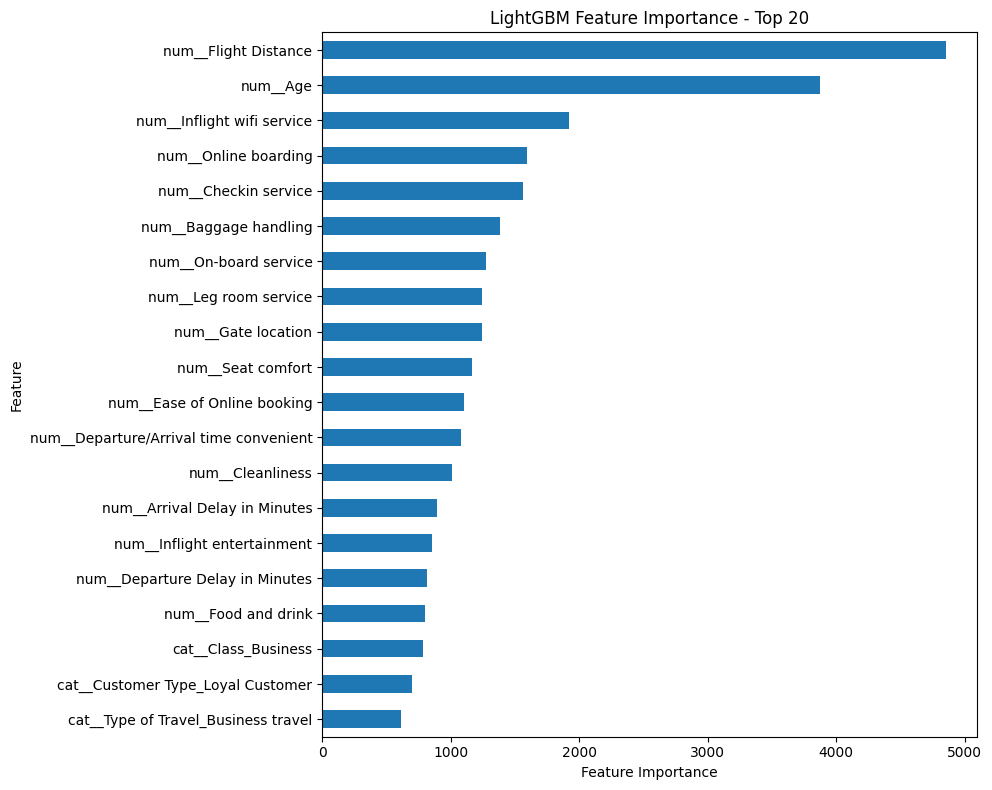

In [ ]:
# 最適化後のPipelineからLightGBMを取得
model = lgb_tuned_final.named_steps["model"]

# 前処理後の特徴量名を取得
preprocessor = lgb_tuned_final.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()

# 特徴量重要度
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

# 可視化
importance_df.head(20).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 8),
    legend=False
)

plt.title("LightGBM Feature Importance - Top 20")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

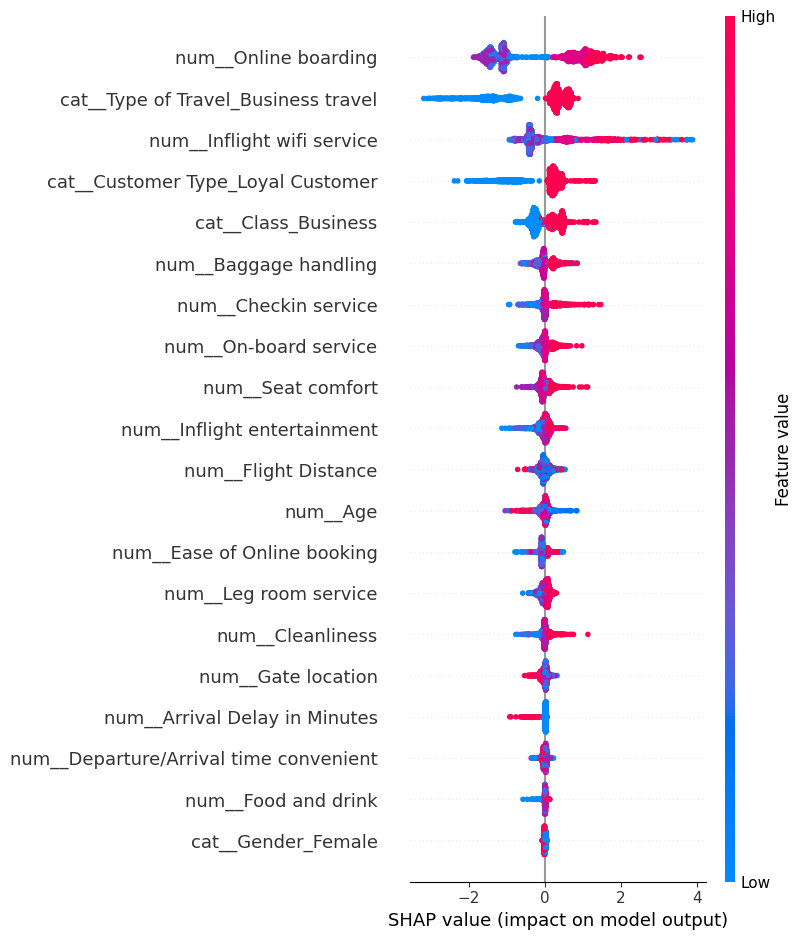

In [ ]:
# 最適化後のモデル
pipeline = lgb_tuned_final

preprocessor = pipeline.named_steps["preprocessor"]
model = pipeline.named_steps["model"]

# テストデータから2000件抽出
X_sample = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)

# 学習時と同じ前処理
X_transformed = preprocessor.transform(X_sample)

# 特徴量名
feature_names = preprocessor.get_feature_names_out()

# SHAP計算
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_transformed)

# 二値分類のクラス1に対応する値を使用
values = shap_values.values

if values.ndim == 3:
    values = values[:, :, 1]

# SHAP summary plot
shap.summary_plot(
    values,
    X_transformed,
    feature_names=feature_names,
    max_display=20,
    show=True
)

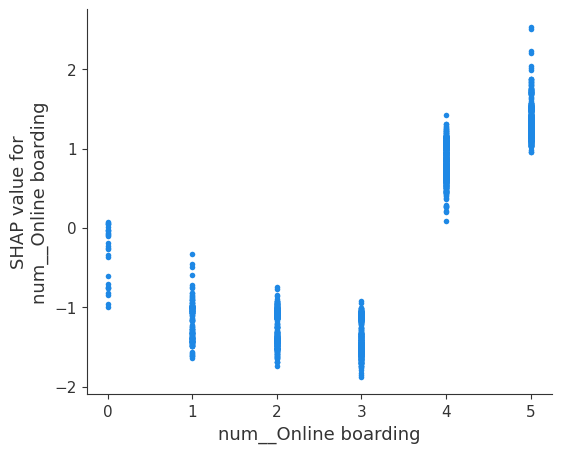

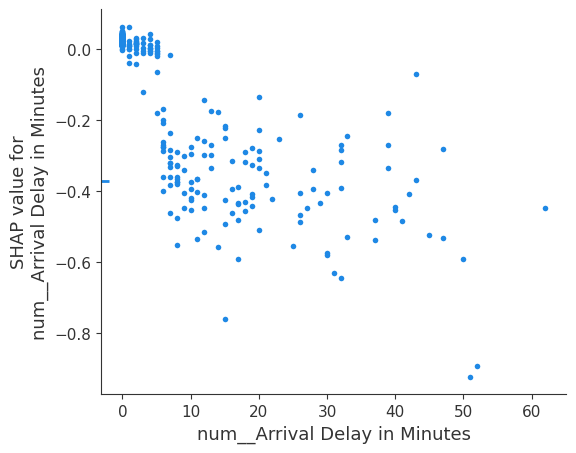

In [ ]:
# Online boarding
shap.dependence_plot(
    "num__Online boarding",
    values,
    X_transformed,
    feature_names=feature_names,
    interaction_index=None
)

# Arrival Delay
shap.dependence_plot(
    "num__Arrival Delay in Minutes",
    values,
    X_transformed,
    feature_names=feature_names,
    interaction_index=None
)

In [ ]:
# NumPy配列をDataFrameに変換
X_shap_df = pd.DataFrame(
    X_transformed,
    columns=feature_names
)

# SHAP値もDataFrameに変換
shap_df = pd.DataFrame(
    values,
    columns=feature_names
)

# ① Online boarding
online_col = "num__Online boarding"

online_summary = pd.DataFrame({
    "評価": X_shap_df[online_col].to_numpy(),
    "SHAP値": shap_df[online_col].to_numpy()
})

print("【Online boarding：評価別SHAP値】")

display(
    online_summary.groupby("評価")["SHAP値"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

# ② Arrival Delay
delay_col = "num__Arrival Delay in Minutes"

delay_summary = pd.DataFrame({
    "遅延時間": X_shap_df[delay_col].to_numpy(),
    "SHAP値": shap_df[delay_col].to_numpy()
})

delay_summary["遅延区分"] = pd.cut(
    delay_summary["遅延時間"],
    bins=[-np.inf, 0, 5, 10, 20, 30, 60, np.inf],
    labels=[
        "0分", "1〜5分", "6〜10分",
        "11〜20分", "21〜30分",
        "31〜60分", "61分以上"
    ]
)

print("【Arrival Delay：遅延時間別SHAP値】")

display(
    delay_summary.groupby("遅延区分", observed=True)["SHAP値"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

【Online boarding：評価別SHAP値】


,count,mean,median,std
評価,,,,
0.0,27,-0.334,-0.225,0.360
1.0,158,-1.174,-1.152,0.245
2.0,350,-1.245,-1.160,0.210
3.0,448,-1.346,-1.384,0.217
4.0,577,0.848,0.852,0.216
5.0,440,1.351,1.311,0.223


【Arrival Delay：遅延時間別SHAP値】


,count,mean,median,std
遅延区分,,,,
0分,1821,0.026,0.026,0.006
1〜5分,49,-0.001,0.005,0.038
6〜10分,41,-0.333,-0.332,0.094
11〜20分,46,-0.366,-0.366,0.127
21〜30分,16,-0.417,-0.414,0.107
31〜60分,25,-0.443,-0.444,0.200
61分以上,1,-0.447,-0.447,NaN


# SHAP分析結果の考察

## 1. 分析目的

LightGBMによる航空会社の顧客満足度予測モデルについて、SHAP（SHapley Additive exPlanations）を用いて各説明変数の予測への寄与を分析した。

SHAP summary plotで重要な説明変数を特定し、dependence plotおよびSHAP値の集計によって、説明変数の値と満足予測への寄与の関係を確認した。

## 2. SHAP summary plotの結果

平均絶対SHAP値による重要度では、主に以下の説明変数が上位となった。

1. Online boarding（オンライン搭乗手続きの評価）
2. Type of Travel：Business travel（旅行目的）
3. Inflight wifi service（機内Wi-Fiの評価）
4. Customer Type：Loyal Customer（顧客区分）
5. Class：Business（座席クラス）

Online boardingやInflight wifi serviceでは、評価が高いほど満足予測を高める方向に寄与する傾向が認められた。

また、Business travel、Loyal Customer、Business Classに該当することも、満足予測を高める方向に寄与していた。

一方、LightGBMの分割回数に基づく特徴量重要度では、Flight DistanceとAgeが上位であったが、SHAPではそれぞれ11位、12位であった。

この結果から、モデルの分岐に頻繁に利用される特徴量と、予測値への平均的な寄与が大きい特徴量は必ずしも一致しないことが確認された。

## 3. Online boardingの分析

### 評価別の平均SHAP値

| 評価 | 件数 | 平均SHAP値 |
|---|---:|---:|
| 0 | 27 | -0.334 |
| 1 | 158 | -1.174 |
| 2 | 350 | -1.245 |
| 3 | 448 | -1.346 |
| 4 | 577 | +0.848 |
| 5 | 440 | +1.351 |

### 考察

Online boardingの評価1〜3では、平均SHAP値が約-1.17〜-1.35となり、満足予測を下げる方向に寄与していた。

一方、評価4では+0.848、評価5では+1.351となり、満足予測を高める方向に寄与していた。

特に評価3から4の間では、平均SHAP値に約2.194の差が認められた。

この結果から、LightGBMはOnline boardingの評価と満足予測の関係を単純な線形関係としてではなく、評価3と4の間で大きく変化する非線形な関係として学習している可能性が示唆された。

また、評価0の平均SHAP値は-0.334であり、評価1〜3よりもマイナス寄与が小さかった。評価0が未利用・未評価などを意味する可能性も考えられるため、データ定義の確認が必要である。

## 4. Arrival Delay in Minutesの分析

### 遅延時間別の平均SHAP値

| 遅延時間 | 件数 | 平均SHAP値 |
|---|---:|---:|
| 0分 | 1,821 | +0.026 |
| 1〜5分 | 49 | -0.001 |
| 6〜10分 | 41 | -0.333 |
| 11〜20分 | 46 | -0.366 |
| 21〜30分 | 16 | -0.417 |
| 31〜60分 | 25 | -0.443 |
| 61分以上 | 1 | -0.447 |

### 考察

到着遅延が0分の場合、平均SHAP値は+0.026であり、満足予測への寄与はほぼゼロであった。

1〜5分の遅延でも平均SHAP値は-0.001とほぼゼロであったが、6〜10分では-0.333となり、満足予測を下げる方向への寄与が大きくなった。

さらに、11〜20分では-0.366、21〜30分では-0.417、31〜60分では-0.443となり、遅延時間が長い区分ほど平均SHAP値が低下する傾向が認められた。

この結果から、LightGBMは到着遅延と満足予測の関係について、短時間の遅延とそれ以上の遅延で寄与が変化する非線形な関係を学習している可能性が示唆された。

ただし、6分を厳密なしきい値と判断することはできない。また、61分以上は1件のみであり、この区分の結果を一般化することは適切ではない。

## 5. EDA・ロジスティック回帰との比較

これまでのEDAでは、Online boardingと満足度の間に強い正の相関が認められた。

また、到着遅延の有無による満足率の比較では、遅延なし群の満足率が45.21%、遅延あり群が35.13%であり、約10.08ポイントの差が認められた。

ロジスティック回帰分析においても、他の説明変数を調整した条件下で、到着遅延と満足度の間に負の関連が認められた。

今回のSHAP分析では、これらの関連に加えて、Online boardingの評価3と4の間や、到着遅延の短時間区分で、モデルの予測寄与が大きく変化することが確認された。

このことから、EDAおよびロジスティック回帰で確認された関連を、LightGBMが非線形な関係として学習していることが示唆された。

## 6. 分析上の限界

- SHAP値はモデルの予測への寄与を示す指標であり、因果効果を表すものではない。
- SHAP値の差は、満足確率や満足率の差と同義ではない。
- 今回の分析は2,000件のサンプルに基づいており、サンプルの違いによる結果の安定性については追加検証が必要である。
- 説明変数間の相関や交互作用によって、個々のSHAP値が影響を受ける可能性がある。
- 各評価・遅延区分の平均SHAP値の差は、他の条件を固定した場合の変化量を直接表すものではない。

## 7. 結論

今回のSHAP分析では、Online boarding、旅行目的、Inflight wifi serviceが、LightGBMによる顧客満足度予測において重要な説明変数であることが確認された。

特にOnline boardingでは、評価3以下と4以上で満足予測への寄与が大きく異なっていた。

また、到着遅延では、1〜5分と6〜10分の区分間で平均SHAP値が大きく変化し、それ以上の遅延区分では負の寄与が続く傾向が認められた。

以上より、顧客満足度の予測には、サービス評価や旅行目的などの説明変数が重要であり、一部の説明変数と満足予測との関係には非線形性が存在することが示唆された。

今後は、旅行目的別に到着遅延のSHAP値を比較し、Business travelとPersonal Travelで遅延の予測寄与が異なるかを検討する。

## 旅行目的別のSHAP分析

,count,mean,median,std
Travel Type,,,,
Business travel,1431,-0.0028,0.0235,0.1059
Personal Travel,569,0.0038,0.0273,0.1049


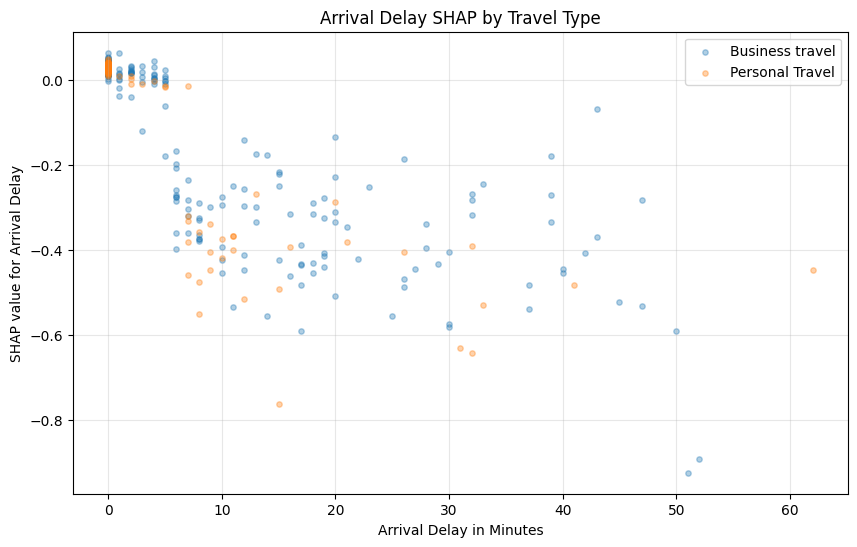

In [ ]:
# 特徴量名を取得
feature_names = lgb_tuned_final.named_steps[
    "preprocessor"
].get_feature_names_out()

# NumPy配列をDataFrameに変換
X_shap_df = pd.DataFrame(
    X_transformed,
    columns=feature_names
)

# SHAP値もDataFrameに変換
shap_values_df = pd.DataFrame(
    np.asarray(shap_df),
    columns=feature_names
)

# 行数が一致しているか確認
assert len(X_shap_df) == len(shap_values_df)

# 対象特徴量
travel_col = "cat__Type of Travel_Business travel"
delay_col = "num__Arrival Delay in Minutes"

# 旅行目的別の分析用データ
analysis_df = pd.DataFrame({
    "Business travel": X_shap_df[travel_col].to_numpy(),
    "Arrival Delay": X_shap_df[delay_col].to_numpy(),
    "Arrival Delay SHAP": shap_values_df[delay_col].to_numpy()
})

# 旅行目的を分類
analysis_df["Travel Type"] = analysis_df[
    "Business travel"
].map({
    1: "Business travel",
    0: "Personal Travel"
})

# 旅行目的別の集計
summary = analysis_df.groupby("Travel Type")[
    "Arrival Delay SHAP"
].agg(["count", "mean", "median", "std"])

display(summary.round(4))

# 可視化
plt.figure(figsize=(10, 6))

for travel_type, group in analysis_df.groupby("Travel Type"):
    plt.scatter(
        group["Arrival Delay"],
        group["Arrival Delay SHAP"],
        alpha=0.35,
        s=15,
        label=travel_type
    )

plt.xlabel("Arrival Delay in Minutes")
plt.ylabel("SHAP value for Arrival Delay")
plt.title("Arrival Delay SHAP by Travel Type")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

count    mean  median     std
Travel Type     Delay Group                               
Business travel 0分            1290  0.0252  0.0244  0.0066
                1〜5分            41  0.0003  0.0094  0.0415
                6〜10分           28 -0.3137 -0.3016  0.0689
                11〜20分          37 -0.3507 -0.3346  0.1182
                21〜30分          14 -0.4207 -0.4274  0.1144
                31〜60分          20 -0.4201 -0.3885  0.2132
Personal Travel 0分             531  0.0280  0.0277  0.0049
                1〜5分             8 -0.0049 -0.0067  0.0103
                6〜10分           13 -0.3752 -0.3815  0.1267
                11〜20分           9 -0.4280 -0.3930  0.1489
                21〜30分           2 -0.3929 -0.3929  0.0169
                31〜60分           5 -0.5352 -0.5299  0.1050
                61分以上            1 -0.4469 -0.4469     NaN

/tmp/ipykernel_400/490761525.py:49: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_400/490761525.py:49: UserWarning: Glyph 12316 (\N{WAVE DASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_400/490761525.py:49: UserWarning: Glyph 20197 (\N{CJK UNIFIED IDEOGRAPH-4EE5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_400/490761525.py:49: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12316 (\N{WAVE DASH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/

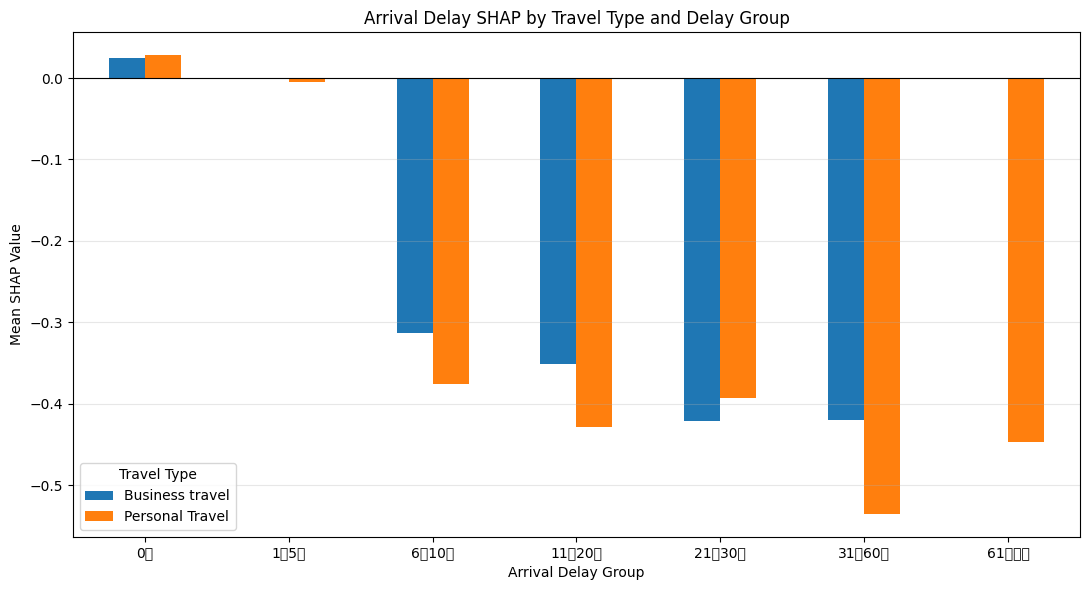

各グループのサンプル数


Travel Type,Business travel,Personal Travel
Delay Group,,
0分,1290.0,531.0
1〜5分,41.0,8.0
6〜10分,28.0,13.0
11〜20分,37.0,9.0
21〜30分,14.0,2.0
31〜60分,20.0,5.0
61分以上,NaN,1.0


In [ ]:
# 遅延時間を区分
bins = [-np.inf, 0, 5, 10, 20, 30, 60, np.inf]

labels = [
    "0分",
    "1〜5分",
    "6〜10分",
    "11〜20分",
    "21〜30分",
    "31〜60分",
    "61分以上"
]

analysis_df["Delay Group"] = pd.cut(
    analysis_df["Arrival Delay"],
    bins=bins,
    labels=labels
)

# 旅行目的 × 遅延時間帯別のSHAP集計
group_summary = (
    analysis_df
    .groupby(
        ["Travel Type", "Delay Group"],
        observed=True
    )["Arrival Delay SHAP"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

display(group_summary)

# 平均SHAP値を比較
pivot_mean = group_summary["mean"].unstack("Travel Type")
pivot_count = group_summary["count"].unstack("Travel Type")

ax = pivot_mean.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Arrival Delay SHAP by Travel Type and Delay Group")
plt.xlabel("Arrival Delay Group")
plt.ylabel("Mean SHAP Value")
plt.legend(title="Travel Type")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("各グループのサンプル数")
display(pivot_count)

In [ ]:
# 元データを利用
eda_df = train.copy()

bins = [-np.inf, 0, 5, 10, 20, 30, 60, np.inf]
labels = [
    "0分", "1〜5分", "6〜10分",
    "11〜20分", "21〜30分",
    "31〜60分", "61分以上"
]

eda_df["Delay Group"] = pd.cut(
    eda_df["Arrival Delay in Minutes"],
    bins=bins,
    labels=labels
)

result = (
    eda_df
    .groupby(["Type of Travel", "Delay Group"], observed=True)
    ["satisfaction"]
    .agg(
        count="count",
        satisfaction_rate="mean"
    )
)

result["satisfaction_rate"] *= 100

display(result.round(2))

count  satisfaction_rate
Type of Travel  Delay Group                           
Business travel 0分           455330              59.49
                1〜5分          13752              60.52
                6〜10分          9068              38.82
                11〜20分        10130              41.35
                21〜30分         4870              40.08
                31〜60分         3896              41.20
                61分以上           212              41.04
Personal Travel 0分           185085              10.07
                1〜5分           5413               8.90
                6〜10分          3739               4.39
                11〜20分         4126               4.85
                21〜30分         2080               4.18
                31〜60分         1544               5.25
                61分以上            98               9.18

## 旅行目的別の到着遅延に関するSHAP分析

### 1. 分析目的

LightGBMによる航空会社の顧客満足度予測モデルを対象に、到着遅延時間が満足度の予測にどのように寄与しているかをSHAP値によって評価した。

特に、旅行目的（Business travel / Personal Travel）によって、到着遅延の寄与に違いがあるかを検討した。

### 2. 分析方法

最適化済みLightGBMモデルを用いて、テストデータから抽出した2,000件についてSHAP値を算出した。

- 目的変数：顧客満足度（満足=1、不満=0）
- 対象特徴量：Arrival Delay in Minutes
- 比較群：Business travel / Personal Travel
- 評価指標：到着遅延のSHAP値
- 分析方法：旅行目的別のSHAP値の集計、散布図による比較、遅延時間帯別の平均SHAP値の比較

SHAP値は、各特徴量がモデルの予測に与える寄与を表す。今回のSHAP値では、正の値は満足側への寄与、負の値は不満側への寄与を意味する。

なお、SHAP値は予測モデルの出力に対する寄与であり、顧客満足確率の変化量や因果効果を直接表すものではない。

### 3. 旅行目的別のSHAP値

| 旅行目的 | 件数 | 平均SHAP値 | 中央値 | 標準偏差 |
|---|---:|---:|---:|---:|
| Business travel | 1,431 | -0.0028 | 0.0235 | 0.1059 |
| Personal Travel | 569 | 0.0038 | 0.0273 | 0.1049 |

#### 結果と解釈

- Business travelの平均SHAP値は-0.0028、Personal Travelでは0.0038であった。
- 両群とも平均SHAP値は0付近に位置し、旅行目的別の全体平均では大きな違いは認められなかった。
- 中央値は両群とも正の値であった。
- 標準偏差もほぼ同程度であり、SHAP値の全体的なばらつきに顕著な違いは見られなかった。

ただし、分析対象の大部分が遅延0分のデータであるため、全体平均だけでは遅延発生時の特徴を十分に捉えられない可能性がある。

そこで、遅延時間帯別の分析を実施した。

### 4. 遅延時間帯別の平均SHAP値

| 遅延時間帯 | Business travel | Personal Travel |
|---|---:|---:|
| 0分 | 0.0252 | 0.0280 |
| 1〜5分 | 0.0003 | -0.0049 |
| 6〜10分 | -0.3137 | -0.3752 |
| 11〜20分 | -0.3507 | -0.4280 |
| 21〜30分 | -0.4207 | -0.3929 |
| 31〜60分 | -0.4201 | -0.5352 |
| 61分以上 | 該当なし | -0.4469 |

#### 4.1. 遅延0分

Business travelでは0.0252、Personal Travelでは0.0280となり、両群ともわずかに正の寄与を示した。

遅延が発生していない場合、到着遅延という特徴量は、モデルの満足側の予測にわずかに寄与していた。

#### 4.2. 1〜5分の遅延

Business travelでは0.0003、Personal Travelでは-0.0049となった。

両群ともSHAP値はほぼ0であり、モデル上ではこの時間帯の到着遅延の寄与は比較的小さかった。

#### 4.3. 6〜10分の遅延

Business travelでは-0.3137、Personal Travelでは-0.3752となった。

1〜5分の遅延と比較して、両群ともSHAP値が大きく負の方向に変化した。

この結果から、今回のモデルでは6〜10分の遅延時間帯において、到着遅延が不満側の予測に強く寄与していることが確認された。

ただし、6分という厳密な閾値が存在することを示すものではない。

#### 4.4. 11〜60分の遅延

11〜60分の時間帯では、両群とも平均SHAP値が継続して負の値を示した。

特に31〜60分では、Business travelが-0.4201、Personal Travelが-0.5352となり、Personal Travelの方が負の寄与が大きかった。

ただし、Personal Travelの31〜60分のサンプル数は5件であり、この差については慎重な解釈が必要である。

### 5. 遅延時間帯別のサンプル数

| 遅延時間帯 | Business travel | Personal Travel |
|---|---:|---:|
| 0分 | 1,290 | 531 |
| 1〜5分 | 41 | 8 |
| 6〜10分 | 28 | 13 |
| 11〜20分 | 37 | 9 |
| 21〜30分 | 14 | 2 |
| 31〜60分 | 20 | 5 |
| 61分以上 | 0 | 1 |

分析対象2,000件のうち、遅延0分は1,821件であり、全体の91.05%を占めていた。

そのため、遅延時間帯別の分析では、特にPersonal Travelの遅延発生群のサンプル数が少ない。

今回の結果はモデルの傾向を把握するための探索的分析として位置付け、旅行目的間の差を確定的に判断することは避ける。

### 6. 散布図による分析

旅行目的別の散布図では、両群とも到着遅延が0分付近ではSHAP値が0付近の正の値に集中していた。

一方、6分以上の遅延では負のSHAP値を示すデータが多くなり、到着遅延が不満側の予測に寄与する傾向が確認された。

ただし、同程度の遅延時間でもSHAP値にはばらつきが見られた。

これは、LightGBMが他の説明変数との組み合わせや非線形な関係を考慮して予測していることと整合する。

### 7. 考察

今回の分析から、以下の特徴が確認された。

1. **遅延時間帯による寄与の違い**

   遅延0分および1〜5分では到着遅延のSHAP値は0付近であったが、6〜10分では大きく負の方向に変化した。

2. **旅行目的間の共通性**

   Business travelとPersonal Travelの両方で、6分以上の遅延が不満側の予測に寄与する傾向が見られた。

3. **旅行目的間の差異**

   一部の遅延時間帯ではPersonal Travelの方が負の寄与が大きかった。ただし、時間帯によって差の方向は異なり、サンプル数も限られるため、どちらの旅行目的が一貫して遅延に敏感であるかは判断できない。

4. **全体平均による評価の限界**

   遅延0分のデータが約91%を占めていたため、旅行目的別の平均SHAP値は両群とも0付近となった。遅延の影響を検討する際には、全体平均だけでなく遅延時間帯別の比較が重要である。

### 8. 結論

LightGBMのSHAP分析により、到着遅延が顧客満足度の予測に寄与する特徴量であることが確認された。

特に、6〜10分の遅延時間帯でSHAP値が大きく負の方向に変化しており、両方の旅行目的で共通した傾向が認められた。

一方、旅行目的間の寄与の違いについては、遅延発生群のサンプル数が少なく、今回のSHAP分析のみで明確な結論を導くことは難しい。

今後は、より多くのデータを用いたSHAP分析と、ロジスティック回帰における到着遅延と旅行目的の交互作用の検証を行い、結果の頑健性を確認する。

## 交互作用検証

In [ ]:
# Model 3：到着遅延 × 旅行目的の交互作用を追加
formula3 = formula2 + """
+ arrival_delayed:C(travel_type)
"""

model3 = smf.logit(
    formula=formula3,
    data=df
).fit(disp=False, maxiter=200)

# Model 2 と Model 3 の尤度比検定
lr_stat = 2 * (model3.llf - model2.llf)
df_diff = int(model3.df_model - model2.df_model)
p_value = chi2.sf(lr_stat, df_diff)

print("【交互作用の尤度比検定】")
print(f"尤度比統計量: {lr_stat:.4f}")
print(f"自由度: {df_diff}")
print(f"p値: {p_value:.6g}")

# 交互作用に関連するオッズ比と95%信頼区間
ci = model3.conf_int()

or_table = pd.DataFrame({
    "OR": np.exp(model3.params),
    "CI_lower": np.exp(ci[0]),
    "CI_upper": np.exp(ci[1]),
    "p_value": model3.pvalues
})

display(
    or_table.loc[
        or_table.index.str.contains("arrival_delayed")
    ].round(4)
)

【交互作用の尤度比検定】
尤度比統計量: 14.7387
自由度: 1
p値: 0.000123487


,OR,CI_lower,CI_upper,p_value
arrival_delayed,0.6554,0.6366,0.6748,0.0000
arrival_delayed:C(travel_type)[T.Personal Travel],0.8662,0.8043,0.9329,0.0001


## 到着遅延と旅行目的の交互作用検証（ロジスティック回帰 Model 3）

### 1. 分析目的

これまでのEDAおよびLightGBMのSHAP分析から、到着遅延が顧客満足度の予測に負の寄与を示すことが確認された。

また、旅行目的（Business travel / Personal Travel）によって、到着遅延時間帯別の満足率やSHAP値に違いが見られた。

そこで、**到着遅延と顧客満足度の関連が旅行目的によって異なるか**を統計的に検証することを目的とした。

### 2. 検証仮説

- **帰無仮説（H₀）**：到着遅延と顧客満足度の関連は、旅行目的によって異ならない（交互作用係数 = 0）。
- **対立仮説（H₁）**：到着遅延と顧客満足度の関連は、旅行目的によって異なる（交互作用係数 ≠ 0）。

有意水準は5%とした。

### 3. 分析方法

多変量ロジスティック回帰を用いて、以下の2つのモデルを比較した。

**Model 2：交互作用なし**

到着遅延の有無、年齢、飛行距離、性別、顧客タイプ、旅行目的、搭乗クラス、13項目のサービス評価を説明変数とした。

**Model 3：交互作用あり**

Model 2の説明変数に、以下の交互作用項を追加した。

`arrival_delayed × travel_type`

到着遅延は、0分を「遅延なし」、1分以上を「遅延あり」とする二値変数として扱った。

Model 2とModel 3の適合度を尤度比検定によって比較し、交互作用の統計的有意性を評価した。

### 4. 分析結果

#### 4.1. 尤度比検定

| 指標 | 結果 |
|---|---:|
| 尤度比統計量 | 14.7387 |
| 自由度 | 1 |
| p値 | 0.0001235 |
| 有意水準 | 0.05 |

p値は0.05を下回ったため、帰無仮説を棄却した。

したがって、**旅行目的によって、到着遅延と顧客満足度の関連が統計的に有意に異なる**ことが示された。

#### 4.2. オッズ比と95%信頼区間

| 変数 | オッズ比 | 95%信頼区間 | p値 |
|---|---:|---|---:|
| 到着遅延（Business travel） | 0.6554 | 0.6366–0.6748 | <0.001 |
| 到着遅延 × Personal Travel | 0.8662 | 0.8043–0.9329 | 約0.0001 |

交互作用のオッズ比0.8662は、Business travelを基準とした到着遅延のオッズ比の比率を表す。

そのため、Personal Travelにおける到着遅延のオッズ比は、以下のように求められる。

$$
OR_{\mathrm{Personal}} = 0.6554 \times 0.8662 \approx 0.5677
$$

旅行目的別の到着遅延のオッズ比は、以下のとおりとなった。

| 旅行目的 | 到着遅延のオッズ比 | オッズの低下率 |
|---|---:|---:|
| Business travel | 0.6554 | 約34.5% |
| Personal Travel | 0.5677 | 約43.2% |

#### 4.3. オッズ比の解釈

**Business travel**

他の説明変数を一定とした場合、到着遅延ありの乗客は、遅延なしの乗客と比較して、満足するオッズが約34.5%低かった。

**Personal Travel**

同様に、到着遅延ありの乗客は、遅延なしの乗客と比較して、満足するオッズが約43.2%低かった。

したがって、オッズ比の尺度では、Personal Travelの方が到着遅延と顧客満足度の負の関連が強いことが示された。

なお、オッズの低下率は満足確率の低下率とは異なる。

### 5. EDA・SHAP分析との比較

| 分析手法 | 主な結果 |
|---|---|
| EDA | 到着遅延ありでは、両旅行目的で満足率が低下 |
| SHAP分析 | 6〜10分以降の遅延で、満足側の予測への寄与が大きく低下 |
| 交互作用検証 | 到着遅延と満足度の関連が旅行目的によって統計的に有意に異なる |

EDAでは、Business travelの方が満足率の絶対的な低下幅が大きい傾向が見られた。

一方、交互作用検証では、Personal Travelの方が到着遅延に対するオッズ比が小さかった。

この違いは、満足率の絶対的な差とオッズ比が異なる尺度であること、またロジスティック回帰では他の説明変数を調整していることによって説明できる。

なお、今回の交互作用検証は遅延の有無を対象としており、SHAP分析で観察された「6〜10分の遅延時間帯での変化」を直接検証したものではない。

### 6. 考察

今回の分析から、到着遅延と顧客満足度の関連は、旅行目的によって異なることが示された。

特にPersonal Travelでは、Business travelと比較して、到着遅延に伴う満足のオッズの低下が相対的に大きかった。

このことから、顧客満足度を分析する際には、到着遅延を単独で評価するだけでなく、旅行目的との組み合わせを考慮することが重要と考えられる。

ただし、本分析は観察データに基づくものであり、到着遅延が満足度を低下させる因果効果を証明するものではない。

また、サービス評価を含む複数の説明変数で調整しているため、推定結果はそれらの変数を一定とした条件付きの関連として解釈する必要がある。

### 7. 結論

多変量ロジスティック回帰による交互作用検証の結果、到着遅延と顧客満足度の関連は、旅行目的によって統計的に有意に異なることが確認された（尤度比検定：p=0.0001235）。

到着遅延ありの場合の満足のオッズ比は、Business travelで0.6554、Personal Travelで約0.5677であり、Personal Travelの方が負の関連が強かった。

今回の結果は、旅行目的と到着遅延の組み合わせが、顧客満足度を理解するうえで有用な可能性を示している。

### 8. 今後の分析方針

今回の統計的検証で得られた知見を、予測モデルの改善に活用する。

1. 到着遅延時間帯を表す特徴量を作成する。
2. 旅行目的と到着遅延の交互作用特徴量を作成する。
3. 特徴量追加前後のLightGBMを、同一条件の交差検証で比較する。
4. ROC-AUCおよびLog Lossを評価し、特徴量追加による予測性能の改善を検証する。

なお、LightGBMは交互作用や非線形関係を自動的に学習できるため、交互作用が統計的に有意であることが、そのまま予測精度の改善を保証するわけではない。

## 交互作用特徴量を追加する

In [ ]:
# 既存データをコピー
X_train_inter = X_train.copy()
X_test_inter = X_test.copy()

# 旅行目的がBusiness travelなら1、それ以外は0
def add_interaction(X):
    X = X.copy()

    business = (
        X["Type of Travel"] == "Business travel"
    ).astype(int)

    arrival_delay = X["Arrival Delay in Minutes"].fillna(0)

    # 旅行目的 × 到着遅延時間
    X["Business_x_ArrivalDelay"] = (
        business * arrival_delay
    )

    return X

X_train_inter = add_interaction(X_train_inter)
X_test_inter = add_interaction(X_test_inter)

print("追加後の特徴量数:", X_train_inter.shape[1])
print(X_train_inter["Business_x_ArrivalDelay"].describe())

追加後の特徴量数: 22
count    559708.000000
mean          0.802822
std           4.855912
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         491.000000
Name: Business_x_ArrivalDelay, dtype: float64


In [ ]:
print(type(lgb_tuned_final))
print(type(preprocessor))

<class 'sklearn.pipeline.Pipeline'>
<class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [ ]:
# 保存済みモデルから前処理を取得
preprocessor = lgb_tuned_final.named_steps["preprocessor"]

# 前処理の設定を確認
print("前処理の構成")
for name, transformer, columns in preprocessor.transformers_:
    print(f"\n名前: {name}")
    print(f"対象列: {columns}")
    print(f"処理: {transformer}")

前処理の構成

名前: num
対象列: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
処理: FunctionTransformer(accept_sparse=True, check_inverse=False,
                    feature_names_out='one-to-one')

名前: cat
対象列: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
処理: Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])


In [ ]:
# 既存モデルから前処理を取得
preprocessor = lgb_tuned_final.named_steps["preprocessor"]

# 数値列・カテゴリ列を自動取得
column_map = {
    name: columns
    for name, transformer, columns in preprocessor.transformers_
}

num_cols = list(column_map["num"])
cat_cols = list(column_map["cat"])

# 交互作用特徴量を追加
interaction_col = "Business_x_ArrivalDelay"

num_cols_inter = num_cols + [interaction_col]

# 既存の前処理を再利用
preprocessor_inter = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(preprocessor.named_transformers_["num"]),
            num_cols_inter
        ),
        (
            "cat",
            clone(preprocessor.named_transformers_["cat"]),
            cat_cols
        )
    ]
)

# 最適化済みモデルのパラメータを引き継ぐ
params = lgb_tuned_final.named_steps["model"].get_params()

# 交互作用追加モデル
model_inter = Pipeline([
    ("preprocessor", preprocessor_inter),
    ("model", LGBMClassifier(**params))
])

# 学習
model_inter.fit(X_train_inter, y_train)

print("交互作用追加モデルの学習完了")
print("数値変数:", len(num_cols_inter))
print("カテゴリ変数:", len(cat_cols))

交互作用追加モデルの学習完了
数値変数: 18
カテゴリ変数: 4


In [ ]:
models = {
    "既存LightGBM": (lgb_tuned_final, X_test),
    "交互作用追加LightGBM": (model_inter, X_test_inter)
}

results = []

for name, (model, X) in models.items():

    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Log Loss": log_loss(y_test, proba),
        "Accuracy": accuracy_score(y_test, pred)
    })

comparison_inter = pd.DataFrame(results)

display(comparison_inter.round(5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,ROC-AUC,Log Loss,Accuracy
0,既存LightGBM,0.95755,0.23077,0.92454
1,交互作用追加LightGBM,0.95753,0.23096,0.92445


### 交互作用特徴量の追加による予測精度の検証

#### 目的
ロジスティック回帰分析により、旅行目的と到着遅延の交互作用が統計的に有意であることが確認された。

この結果を踏まえ、LightGBMに「Business travel × 到着遅延時間」の交互作用特徴量を追加し、予測精度の改善を検証した。

#### 評価結果

| 評価指標 | 既存LightGBM | 交互作用追加LightGBM |
|---|---:|---:|
| ROC-AUC | 0.95755 | 0.95753 |
| Log Loss | 0.23077 | 0.23096 |
| Accuracy | 0.92454 | 0.92445 |

#### 考察

交互作用特徴量を追加したモデルでは、ROC-AUCとAccuracyが僅かに低下し、Log Lossも僅かに悪化した。

この結果から、今回の交互作用特徴量の追加による予測性能の改善は確認できなかった。

LightGBMは決定木の分岐によって説明変数間の交互作用を学習できるため、明示的な交互作用特徴量を追加する効果が限定的だった可能性がある。

また、統計的に有意な交互作用が存在することは、その特徴量を追加すれば予測精度が向上することを意味しない。

#### 結論

今回の比較では、既存LightGBMを暫定的に採用する。

今後は、訓練データ内の交差検証による再現性確認や、別の特徴量設計による改善可能性を検討する。

## 交差検証（Stratified K-Fold）を使って、交互作用特徴量が本当に予測精度の改善につながらないのかを確認

In [ ]:
# # 5-Fold交差検証
# cv = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# # 既存モデルと交互作用追加モデル
# models_cv = {
#     "既存LightGBM": (
#         X_train,
#         preprocessor
#     ),
#     "交互作用追加LightGBM": (
#         X_train_inter,
#         preprocessor_inter
#     )
# }

# results_cv = []

# for name, (X, prep) in models_cv.items():

#     model = Pipeline([
#         ("preprocessor", clone(prep)),
#         ("model", LGBMClassifier(
#             **best_params,
#             random_state=42,
#             n_jobs=1,
#             verbosity=-1
#         ))
#     ])

#     scores = cross_validate(
#         model,
#         X,
#         y_train,
#         cv=cv,
#         scoring={
#             "roc_auc": "roc_auc",
#             "neg_log_loss": "neg_log_loss",
#             "accuracy": "accuracy"
#         },
#         n_jobs=1
#     )

#     results_cv.append({
#         "Model": name,
#         "ROC-AUC_mean": scores["test_roc_auc"].mean(),
#         "ROC-AUC_std": scores["test_roc_auc"].std(),
#         "LogLoss_mean": -scores["test_neg_log_loss"].mean(),
#         "LogLoss_std": scores["test_neg_log_loss"].std(),
#         "Accuracy_mean": scores["test_accuracy"].mean(),
#         "Accuracy_std": scores["test_accuracy"].std()
#     })

# comparison_cv = pd.DataFrame(results_cv)

# display(comparison_cv.round(5))


In [ ]:
# # Google Driveをマウント
# drive.mount("/content/drive")

# # 保存先
# save_dir = Path("/content/drive/MyDrive/airline_satisfaction")
# save_dir.mkdir(parents=True, exist_ok=True)

# # 交差検証結果を保存
# comparison_cv.to_csv(
#     save_dir / "lightgbm_cv_results.csv",
#     index=False,
#     encoding="utf-8-sig"
# )

# print("交差検証結果を保存しました")
# display(comparison_cv.round(5))


In [ ]:
drive.mount("/content/drive")

# 保存した結果を読み込む
comparison_cv = pd.read_csv(
    "/content/drive/MyDrive/airline_satisfaction/lightgbm_cv_results.csv"
)

display(comparison_cv.round(5))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Model,ROC-AUC_mean,ROC-AUC_std,LogLoss_mean,LogLoss_std,Accuracy_mean,Accuracy_std
0,既存LightGBM,0.95860,0.00038,0.22758,0.00161,0.92593,0.00075
1,交互作用追加LightGBM,0.95859,0.00039,0.22758,0.00164,0.92595,0.00073


### 交互作用特徴量の有効性検証：5-Fold交差検証

#### 目的
既存LightGBMと、旅行目的×到着遅延時間の交互作用特徴量を追加したLightGBMについて、5-Fold Stratified Cross Validationを用いて予測性能を比較した。

#### 結果

| 評価指標 | 既存LightGBM | 交互作用追加LightGBM |
|---|---:|---:|
| ROC-AUC（平均） | 0.95860 | 0.95859 |
| ROC-AUC（標準偏差） | 0.00038 | 0.00039 |
| Log Loss（平均） | 0.22758 | 0.22758 |
| Log Loss（標準偏差） | 0.00161 | 0.00164 |
| Accuracy（平均） | 0.92593 | 0.92595 |
| Accuracy（標準偏差） | 0.00075 | 0.00073 |

#### 考察
交互作用特徴量を追加したモデルと既存モデルの間に、実質的な予測性能の差は確認されなかった。

ロジスティック回帰では旅行目的と到着遅延の交互作用が統計的に有意だったが、LightGBMでは元の特徴量から交互作用を学習できるため、追加特徴量の効果が限定的だった可能性がある。

#### 結論
交差検証およびテストデータでの比較から、交互作用特徴量の追加による明確な改善は確認できなかった。

モデルの単純さを優先し、既存LightGBMを最終モデルの候補として採用する。

なお、今回の比較は既存モデルの最適化済みハイパーパラメータを共通に使用した探索的検証である。

## 誤分類分析

In [ ]:
# 最適化済みLightGBMで予測
y_proba = lgb_tuned_final.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

# 誤分類分析用データ
error_df = X_test.copy().reset_index(drop=True)

error_df["Actual"] = np.asarray(y_test)
error_df["Predicted"] = y_pred
error_df["Predicted_Probability"] = y_proba

# 分類結果のラベル
conditions = [
    (error_df["Actual"] == 1) & (error_df["Predicted"] == 1),
    (error_df["Actual"] == 0) & (error_df["Predicted"] == 0),
    (error_df["Actual"] == 0) & (error_df["Predicted"] == 1),
    (error_df["Actual"] == 1) & (error_df["Predicted"] == 0)
]

labels = ["TP", "TN", "FP", "FN"]

error_df["Error_Type"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

# 件数と割合
summary = (
    error_df["Error_Type"]
    .value_counts()
    .rename_axis("Error_Type")
    .reset_index(name="Count")
)

summary["Rate_%"] = (
    summary["Count"] / len(error_df) * 100
)

display(summary.round(2))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Error_Type,Count,Rate_%
0,TN,73441,52.49
1,TP,55927,39.97
2,FN,6141,4.39
3,FP,4418,3.16


In [ ]:
group_cols = [
    "Type of Travel",
    "Class",
    "Customer Type"
]

for col in group_cols:
    print(f"\n【{col}別の誤分類分析】")

    # 顧客層ごとのTP/TN/FP/FNの件数
    counts = pd.crosstab(
        error_df[col],
        error_df["Error_Type"]
    ).reindex(
        columns=["TP", "TN", "FP", "FN"],
        fill_value=0
    )

    counts["Total"] = counts.sum(axis=1)

    # 各顧客層の全件数を分母とした割合
    counts["Error_Rate_%"] = (
        (counts["FP"] + counts["FN"])
        / counts["Total"] * 100
    )

    # 実際に満足した人のうちFNになった割合
    counts["FN_Rate_%"] = (
        counts["FN"]
        / (counts["TP"] + counts["FN"]).replace(0, float("nan"))
        * 100
    )

    # 実際に不満だった人のうちFPになった割合
    counts["FP_Rate_%"] = (
        counts["FP"]
        / (counts["TN"] + counts["FP"]).replace(0, float("nan"))
        * 100
    )

    display(
        counts.sort_values(
            "Error_Rate_%",
            ascending=False
        ).round(2)
    )



【Type of Travel別の誤分類分析】


Error_Type,TP,TN,FP,FN,Total,Error_Rate_%,FN_Rate_%,FP_Rate_%
Type of Travel,,,,,,,,
Business travel,54576,36823,4285,3523,99207,7.87,6.06,10.42
Personal Travel,1351,36618,133,2618,40720,6.76,65.96,0.36



【Class別の誤分類分析】


Error_Type,TP,TN,FP,FN,Total,Error_Rate_%,FN_Rate_%,FP_Rate_%
Class,,,,,,,,
Eco Plus,1055,4449,132,408,6044,8.93,27.89,2.88
Eco,6608,53537,944,4349,65438,8.09,39.69,1.73
Business,48264,15455,3342,1384,68445,6.90,2.79,17.78



【Customer Type別の誤分類分析】


Error_Type,TP,TN,FP,FN,Total,Error_Rate_%,FN_Rate_%,FP_Rate_%
Customer Type,,,,,,,,
disloyal Customer,3522,18774,725,1466,24487,8.95,29.39,3.72
Loyal Customer,52405,54667,3693,4675,115440,7.25,8.19,6.33


In [ ]:
# 旅行目的 × 座席クラス別の誤分類
group_cols = ["Type of Travel", "Class"]

cross_error = pd.crosstab(
    [error_df[col] for col in group_cols],
    error_df["Error_Type"]
).reindex(
    columns=["TP", "TN", "FP", "FN"],
    fill_value=0
)

cross_error["Total"] = cross_error[
    ["TP", "TN", "FP", "FN"]
].sum(axis=1)

cross_error["Error_Rate_%"] = (
    (cross_error["FP"] + cross_error["FN"])
    / cross_error["Total"] * 100
)

cross_error["FN_Rate_%"] = (
    cross_error["FN"]
    / (cross_error["TP"] + cross_error["FN"]).replace(0, np.nan)
    * 100
)

cross_error["FP_Rate_%"] = (
    cross_error["FP"]
    / (cross_error["TN"] + cross_error["FP"]).replace(0, np.nan)
    * 100
)

display(
    cross_error.sort_values(
        "FN_Rate_%",
        ascending=False
    ).round(2)
)


Error_Type                   TP     TN    FP    FN  Total  Error_Rate_%  \
Type of Travel  Class                                                     
Personal Travel Eco        1226  33643   118  2391  37378          6.71   
                Eco Plus     90   2264     7   165   2526          6.81   
                Business     35    711     8    62    816          8.58   
Business travel Eco        5382  19894   826  1958  28060          9.92   
                Eco Plus    965   2185   125   243   3518         10.46   
                Business  48229  14744  3334  1322  67629          6.88   

Error_Type                FN_Rate_%  FP_Rate_%  
Type of Travel  Class                           
Personal Travel Eco           66.10       0.35  
                Eco Plus      64.71       0.31  
                Business      63.92       1.11  
Business travel Eco           26.68       3.99  
                Eco Plus      20.12       5.41  
                Business       2.67      18.44

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


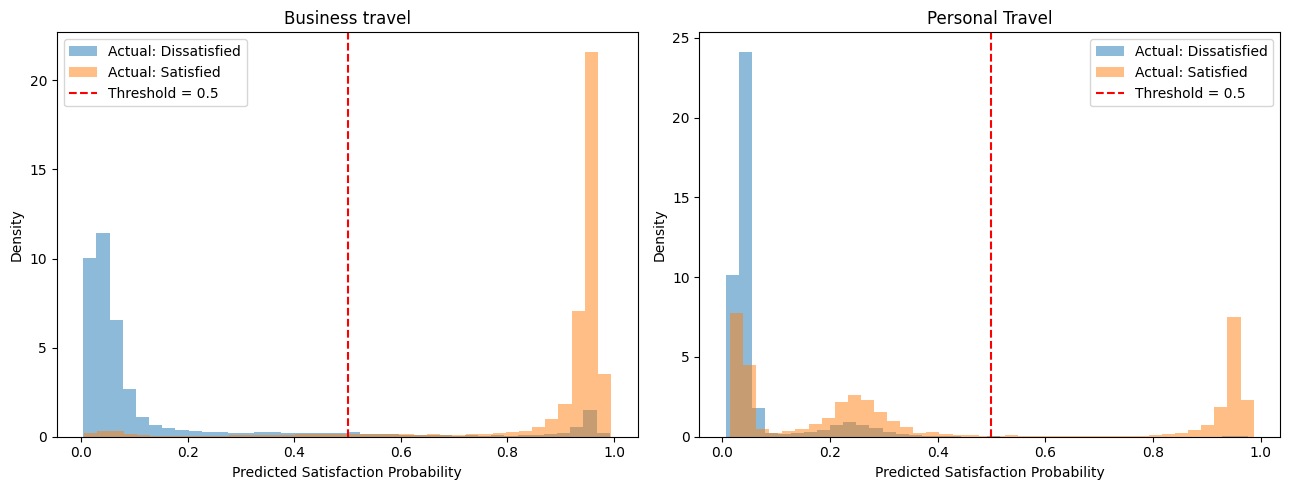

,count,mean,median,std
Type of Travel,,,,
Business travel,58099,0.8899,0.9514,0.1881
Personal Travel,3969,0.4164,0.2565,0.3821


In [ ]:
# 既存LightGBMによる予測確率
proba = lgb_tuned_final.predict_proba(X_test)[:, 1]

# 予測結果の分析用データ
prob_df = X_test[["Type of Travel", "Class"]].copy().reset_index(drop=True)

prob_df["Actual"] = np.asarray(y_test)
prob_df["Predicted_Probability"] = proba

# 旅行目的ごとの予測確率分布
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, travel_type in zip(
    axes, ["Business travel", "Personal Travel"]
):
    group = prob_df[
        prob_df["Type of Travel"] == travel_type
    ]

    for actual, label in [
        (0, "Actual: Dissatisfied"),
        (1, "Actual: Satisfied")
    ]:
        values = group.loc[
            group["Actual"] == actual,
            "Predicted_Probability"
        ]

        ax.hist(
            values,
            bins=40,
            alpha=0.5,
            density=True,
            label=label
        )

    ax.axvline(
        0.5,
        color="red",
        linestyle="--",
        label="Threshold = 0.5"
    )

    ax.set_title(travel_type)
    ax.set_xlabel("Predicted Satisfaction Probability")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

# 実際に満足している顧客の予測確率を集計
satisfied_summary = (
    prob_df[prob_df["Actual"] == 1]
    .groupby("Type of Travel")["Predicted_Probability"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

display(satisfied_summary)

,Threshold,Accuracy,Precision,Recall,F1,FN_Rate,FP_Rate
0,0.05,0.7933,0.2831,0.7312,0.4082,0.2688,0.1999
1,0.10,0.8622,0.3844,0.6873,0.4930,0.3127,0.1189
2,0.15,0.8688,0.3971,0.6682,0.4981,0.3318,0.1096
3,0.20,0.8813,0.4261,0.6274,0.5075,0.3726,0.0913
4,0.25,0.9076,0.5265,0.5150,0.5207,0.4850,0.0500
5,0.30,0.9258,0.7040,0.4122,0.5199,0.5878,0.0187
6,0.35,0.9306,0.8224,0.3676,0.5081,0.6324,0.0086
7,0.40,0.9320,0.8770,0.3520,0.5023,0.6480,0.0053
8,0.45,0.9323,0.8998,0.3439,0.4976,0.6561,0.0041
9,0.50,0.9324,0.9104,0.3404,0.4955,0.6596,0.0036


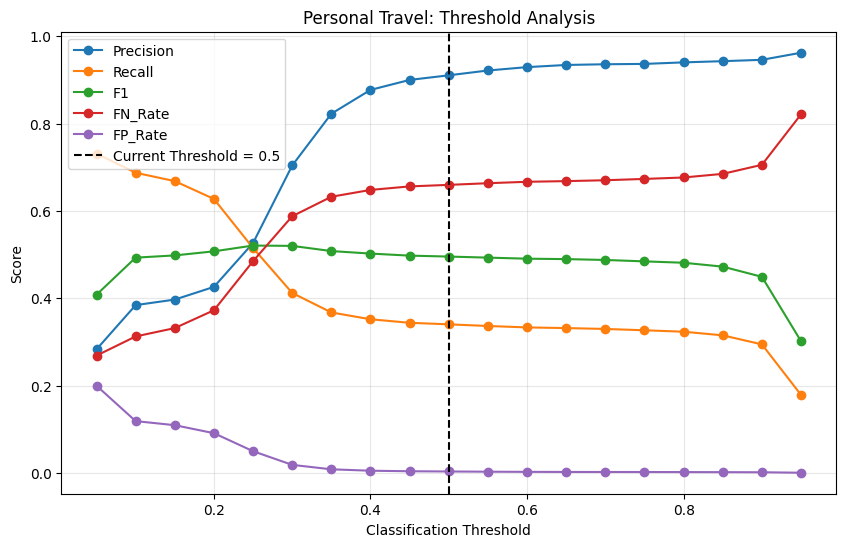

探索的なF1最大閾値: 0.25
F1: 0.5207
FN率: 0.485
FP率: 0.05


In [ ]:
# Personal Travelのみ抽出
personal_df = prob_df[
    prob_df["Type of Travel"] == "Personal Travel"
].copy()

y_true = personal_df["Actual"].astype(int).to_numpy()
y_prob = personal_df["Predicted_Probability"].to_numpy()

# 分類閾値を変更して比較
thresholds = np.arange(0.05, 0.96, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "FN_Rate": fn / (fn + tp),
        "FP_Rate": fp / (fp + tn)
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(4))

# 閾値ごとの評価指標を可視化
plt.figure(figsize=(10, 6))

for col in [
    "Precision", "Recall", "F1",
    "FN_Rate", "FP_Rate"
]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[col],
        marker="o",
        label=col
    )

plt.axvline(
    0.5,
    color="black",
    linestyle="--",
    label="Current Threshold = 0.5"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Personal Travel: Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 探索的にF1が最大となる閾値を確認
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("探索的なF1最大閾値:", best_row["Threshold"])
print("F1:", round(best_row["F1"], 4))
print("FN率:", round(best_row["FN_Rate"], 4))
print("FP率:", round(best_row["FP_Rate"], 4))

# LightGBMモデルの誤分類分析結果

## 1. 分析目的

LightGBMによる航空会社の顧客満足度予測について、モデル全体の正解率だけでなく、どのような顧客層で誤分類が発生しているかを明らかにする。

特に、以下の観点から分析した。

- 全体の混同行列
- 旅行目的別の誤分類
- 座席クラス別の誤分類
- 顧客タイプ別の誤分類
- 旅行目的 × 座席クラス別の誤分類
- 旅行目的別の予測確率分布
- Personal Travelにおける分類閾値の感度分析

本分析では、満足を陽性クラス（1）、不満を陰性クラス（0）としている。

- TP：実際に満足しており、満足と予測
- TN：実際に不満であり、不満と予測
- FP：実際は不満だが、満足と予測
- FN：実際は満足だが、不満と予測

---

## 2. 全体の誤分類分析

### 2.1 混同行列

| 分類 | 件数 | 全体に占める割合 |
|---|---:|---:|
| TN | 73,441 | 52.49% |
| TP | 55,927 | 39.97% |
| FN | 6,141 | 4.39% |
| FP | 4,418 | 3.16% |

テストデータ全体では、約92.45%のAccuracyを達成した。

誤分類件数は以下のとおり。

- FN：6,141件
- FP：4,418件
- 誤分類合計：10,559件

FNがFPを上回っており、実際に満足している顧客を不満と誤予測するケースが比較的多かった。

---

## 3. 旅行目的別の誤分類分析

| 旅行目的 | TP | TN | FP | FN | 誤分類率 | FN率 | FP率 |
|---|---:|---:|---:|---:|---:|---:|---:|
| Business travel | 54,576 | 36,823 | 4,285 | 3,523 | 7.87% | 6.06% | 10.42% |
| Personal Travel | 1,351 | 36,618 | 133 | 2,618 | 6.76% | 65.96% | 0.36% |

### 3.1 Business travel

Business travelではFN率が6.06%と比較的低く、実際に満足している顧客の多くを正しく予測できていた。

一方、FP率は10.42%であり、実際には不満である顧客を満足と誤予測するケースが見られた。

### 3.2 Personal Travel

Personal TravelではFN率が65.96%と非常に高かった。

これは、実際に満足しているPersonal Travelの顧客のうち、約66%を不満と誤予測していることを意味する。

一方、FP率は0.36%と極めて低かった。

### 3.3 考察

旅行目的によって誤分類の傾向が大きく異なることが確認された。

- Business travel：FPが相対的に多い
- Personal Travel：FNが非常に多い

特にPersonal Travelでは、満足顧客を正しく検出する能力に課題がある。

全体のAccuracyが高くても、特定の顧客層で高いFN率が発生していることが明らかになった。

---

## 4. 座席クラス別の誤分類分析

| 座席クラス | TP | TN | FP | FN | 誤分類率 | FN率 | FP率 |
|---|---:|---:|---:|---:|---:|---:|---:|
| Eco Plus | 1,055 | 4,449 | 132 | 408 | 8.93% | 27.89% | 2.88% |
| Eco | 6,608 | 53,537 | 944 | 4,349 | 8.09% | 39.69% | 1.73% |
| Business | 48,264 | 15,455 | 3,342 | 1,384 | 6.90% | 2.79% | 17.78% |

### 4.1 Eco

EcoではFN率が39.69%と高かった。

実際に満足している顧客の約40%を不満と誤予測しており、満足顧客の見逃しが課題となっていた。

### 4.2 Eco Plus

Eco PlusではFN率が27.89%であり、Ecoほどではないものの、満足顧客の見逃しが確認された。

### 4.3 Business

BusinessクラスではFN率が2.79%と低く、満足顧客を高い割合で正しく予測できていた。

一方、FP率は17.78%と高く、不満顧客を満足と誤予測する傾向が見られた。

### 4.4 考察

座席クラスによっても誤分類の傾向が異なった。

EcoおよびEco PlusではFNが多く、BusinessクラスではFPが多かった。

ただし、座席クラスと旅行目的には関連があるため、座席クラス単独の結果だけで誤分類の原因を判断することはできない。

---

## 5. 顧客タイプ別の誤分類分析

| 顧客タイプ | TP | TN | FP | FN | 誤分類率 | FN率 | FP率 |
|---|---:|---:|---:|---:|---:|---:|---:|
| disloyal Customer | 3,522 | 18,774 | 725 | 1,466 | 8.95% | 29.39% | 3.72% |
| Loyal Customer | 52,405 | 54,667 | 3,693 | 4,675 | 7.25% | 8.19% | 6.33% |

### 5.1 disloyal Customer

disloyal CustomerではFN率が29.39%となり、満足顧客の約3割を不満と誤予測していた。

### 5.2 Loyal Customer

Loyal CustomerではFN率が8.19%と比較的低かった。

### 5.3 考察

顧客タイプによって満足顧客の検出性能に違いが見られた。

特にdisloyal Customerでは、満足顧客を見逃しやすい傾向が確認された。

---

## 6. 旅行目的 × 座席クラス別の誤分類分析

| 旅行目的 | 座席クラス | TP | TN | FP | FN | 誤分類率 | FN率 | FP率 |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| Personal Travel | Eco | 1,226 | 33,643 | 118 | 2,391 | 6.71% | 66.10% | 0.35% |
| Personal Travel | Eco Plus | 90 | 2,264 | 7 | 165 | 6.81% | 64.71% | 0.31% |
| Personal Travel | Business | 35 | 711 | 8 | 62 | 8.58% | 63.92% | 1.11% |
| Business travel | Eco | 5,382 | 19,894 | 826 | 1,958 | 9.92% | 26.68% | 3.99% |
| Business travel | Eco Plus | 965 | 2,185 | 125 | 243 | 10.46% | 20.12% | 5.41% |
| Business travel | Business | 48,229 | 14,744 | 3,334 | 1,322 | 6.88% | 2.67% | 18.44% |

### 6.1 Personal Travel

Personal Travelでは、すべての座席クラスでFN率が約64〜66%となった。

- Eco：66.10%
- Eco Plus：64.71%
- Business：63.92%

この結果から、Personal TravelにおけるFN率の高さは、特定の座席クラスに限定された現象ではないことが確認された。

### 6.2 Business travel

Business travelでは、座席クラスによってFN率が大きく異なった。

- Eco：26.68%
- Eco Plus：20.12%
- Business：2.67%

Businessクラスでは満足顧客を正しく検出できている一方、Ecoでは満足顧客の見逃しが比較的多かった。

また、Business travel × BusinessクラスではFP率が18.44%と高かった。

### 6.3 考察

旅行目的と座席クラスを組み合わせて分析した結果、Personal Travelにおける高いFN率が、座席クラスの違いだけでは説明できないことが示唆された。

そのため、旅行目的そのものや、旅行目的と他のサービス評価項目との関係を詳しく調べる必要がある。

---

## 7. 旅行目的別の予測確率分布

実際に満足している顧客（TP＋FN）を対象として、LightGBMが出力した満足予測確率を比較した。

| 旅行目的 | 件数 | 平均予測確率 | 中央値 | 標準偏差 |
|---|---:|---:|---:|---:|
| Business travel | 58,099 | 0.8899 | 0.9514 | 0.1881 |
| Personal Travel | 3,969 | 0.4164 | 0.2565 | 0.3821 |

### 7.1 Business travel

Business travelでは、実際に満足している顧客に対して0.9以上の高い予測確率が出力される傾向があった。

中央値は0.9514であり、多くの満足顧客が分類閾値0.5を上回っていた。

### 7.2 Personal Travel

Personal Travelでは、実際に満足している顧客でも低い予測確率が出力されるケースが多かった。

平均予測確率は0.4164、中央値は0.2565であり、いずれも分類閾値0.5を下回っていた。

### 7.3 考察

Personal TravelでFN率が高い背景には、実際に満足している顧客に対してもモデルが低い満足予測確率を出力していることが関係していると考えられる。

この結果から、分類閾値を調整することでFN率を改善できる可能性が示唆された。

---

## 8. Personal Travelの分類閾値分析

### 8.1 分析目的

Personal TravelにおけるFN率の高さを改善するため、分類閾値を0.05〜0.95の範囲で変更し、予測性能の変化を確認した。

### 8.2 主要な閾値の比較

| 指標 | 閾値0.10 | 閾値0.25 | 閾値0.30 | 閾値0.50 |
|---|---:|---:|---:|---:|
| Accuracy | 0.8622 | 0.9076 | 0.9258 | 0.9324 |
| Precision | 0.3844 | 0.5265 | 0.7040 | 0.9104 |
| Recall | 0.6873 | 0.5150 | 0.4122 | 0.3404 |
| F1 | 0.4930 | **0.5207** | 0.5199 | 0.4955 |
| FN率 | 0.3127 | 0.4850 | 0.5878 | 0.6596 |
| FP率 | 0.1189 | 0.0500 | 0.0187 | 0.0036 |

### 8.3 閾値0.50と0.25の比較

閾値を0.50から0.25に変更すると、以下の変化が確認された。

| 指標 | 閾値0.50 | 閾値0.25 | 変化 |
|---|---:|---:|---:|
| Accuracy | 93.24% | 90.76% | -2.48ポイント |
| Precision | 91.04% | 52.65% | -38.39ポイント |
| Recall | 34.04% | 51.50% | +17.46ポイント |
| F1 | 0.4955 | 0.5207 | +0.0252 |
| FN率 | 65.96% | 48.50% | -17.46ポイント |
| FP率 | 0.36% | 5.00% | +4.64ポイント |

今回の探索範囲では、閾値0.25でF1スコアが最大となった。

閾値を0.25に下げることで、満足顧客の見逃しを減らすことができた。

一方でPrecisionが大きく低下し、不満顧客を満足と誤予測する割合が増加した。

### 8.4 考察

分類閾値の調整によって、Personal TravelにおけるFN率を改善できる可能性が確認された。

しかし、閾値0.25でもFN率は48.50%と高く、満足顧客の約半数を見逃している。

また、PrecisionとFP率が悪化するため、閾値を下げれば必ずモデルが良くなるわけではない。

なお、今回の閾値0.25はテストデータ上で探索的に得られた値であり、最終的な閾値として採用するには、別の検証データでの確認が必要である。

---

## 9. 誤分類分析の総合考察

今回の誤分類分析から、以下の知見が得られた。

**① 全体のAccuracyは高いが、顧客層別では課題がある**

モデル全体のAccuracyは約92.45%である一方、Personal TravelではFN率が65.96%と高かった。

**② 旅行目的によって誤分類の傾向が異なる**

Business travelではFPが相対的に多く、Personal TravelではFNが非常に多かった。

**③ Personal TravelのFN率の高さは座席クラスに依存しない**

Personal Travelでは、Eco、Eco Plus、BusinessのいずれもFN率が約64〜66%であった。

**④ Personal Travelの満足顧客には低い予測確率が割り当てられやすい**

実際に満足しているPersonal Travelの顧客の予測確率中央値は0.2565であり、分類閾値0.5を大きく下回っていた。

**⑤ 閾値変更によってFN率は改善するが、トレードオフがある**

閾値を0.50から0.25へ変更すると、FN率は65.96%から48.50%へ改善したが、Precisionは91.04%から52.65%へ低下した。

---

## 10. 結論

今回の誤分類分析により、既存LightGBMは全体として高い予測性能を示しているものの、**Personal Travelにおける満足顧客の見逃しが主要な課題**であることが明らかになった。

特に、Personal Travelでは座席クラスに関係なくFN率が高く、実際に満足している顧客にも低い予測確率を出力する傾向が確認された。

分類閾値を調整することでFN率を一定程度改善できるものの、PrecisionとFP率の悪化が生じるため、閾値調整のみでは十分な改善とはいえない。

今後は、Personal TravelにおけるTPとFNの特徴量を比較し、満足顧客を見逃す要因を詳しく分析することで、予測性能の改善につなげる必要がある。

## FN事例の特徴量を分析する

In [ ]:
# 元のテストデータと予測確率を対応付ける
error_df = X_test.copy().reset_index(drop=True)

error_df["Actual"] = np.asarray(y_test)
error_df["Probability"] = lgb_tuned_final.predict_proba(X_test)[:, 1]
error_df["Predicted"] = (error_df["Probability"] >= 0.5).astype(int)

# Personal Travelかつ実際に満足している顧客
personal_satisfied = error_df[
    (error_df["Type of Travel"] == "Personal Travel") &
    (error_df["Actual"] == 1)
].copy()

# TP / FNに分類
personal_satisfied["Prediction_Group"] = np.where(
    personal_satisfied["Predicted"] == 1,
    "TP",
    "FN"
)

print("【Personal Travel：満足顧客の分類】")
display(personal_satisfied["Prediction_Group"].value_counts())

# 数値特徴量の平均値を比較
numeric_cols = X_test.select_dtypes(include=np.number).columns.tolist()

comparison = (
    personal_satisfied
    .groupby("Prediction_Group")[numeric_cols]
    .mean()
    .T
)

comparison["Difference_FN_minus_TP"] = (
    comparison["FN"] - comparison["TP"]
)

display(
    comparison
    .sort_values(
        "Difference_FN_minus_TP",
        key=lambda s: s.abs(),
        ascending=False
    )
    .round(3)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


【Personal Travel：満足顧客の分類】


,count
Prediction_Group,
FN,2618
TP,1351


Prediction_Group,FN,TP,Difference_FN_minus_TP
Flight Distance,874.371,853.483,20.889
Age,36.796,35.885,0.911
Inflight wifi service,3.099,3.546,-0.447
Arrival Delay in Minutes,0.719,0.292,0.426
Ease of Online booking,3.080,3.461,-0.381
Departure Delay in Minutes,0.752,0.475,0.277
Online boarding,3.254,3.524,-0.270
Leg room service,3.254,3.373,-0.119
Departure/Arrival time convenient,3.868,3.987,-0.118
Checkin service,3.498,3.594,-0.097


# Personal TravelにおけるFN・TPの特徴量比較分析

## 1. 分析目的

これまでの誤分類分析により、Personal Travel（個人旅行）では、実際に満足している顧客を不満と誤予測するFN（False Negative）の割合が65.96%と高いことが判明した。

そこで、Personal Travelの満足顧客を以下の2グループに分類し、各特徴量の平均値を比較した。

- **TP（True Positive）**：実際に満足しており、モデルも満足と正しく予測した顧客
- **FN（False Negative）**：実際には満足しているが、モデルが不満と誤予測した顧客

本分析の目的は、FNとTPの特徴量の違いを明らかにし、Personal Travelにおける誤分類の要因に関する仮説を立てることである。

---

## 2. 分析対象

| 分類 | 件数 | 割合 |
|---|---:|---:|
| TP | 1,351 | 34.04% |
| FN | 2,618 | 65.96% |
| 合計 | 3,969 | 100.00% |

Personal Travelの満足顧客3,969人のうち、2,618人が不満と誤分類されていた。

この結果から、Personal Travelにおける満足顧客の検出性能には改善の余地があることが確認された。

---

## 3. FNとTPの特徴量比較

各特徴量について、FNとTPの平均値を算出した。

差分は以下のように定義する。

**差分 = FNの平均値 − TPの平均値**

### 3.1 特徴量別の比較結果

| 特徴量 | FN平均 | TP平均 | 差分 |
|---|---:|---:|---:|
| Flight Distance | 874.371 | 853.483 | +20.889 |
| Age | 36.796 | 35.885 | +0.911 |
| Inflight wifi service | 3.099 | 3.546 | -0.447 |
| Arrival Delay in Minutes | 0.719 | 0.292 | +0.426 |
| Ease of Online booking | 3.080 | 3.461 | -0.381 |
| Departure Delay in Minutes | 0.752 | 0.475 | +0.277 |
| Online boarding | 3.254 | 3.524 | -0.270 |
| Leg room service | 3.254 | 3.373 | -0.119 |
| Departure/Arrival time convenient | 3.868 | 3.987 | -0.118 |
| Checkin service | 3.498 | 3.594 | -0.097 |
| Baggage handling | 3.796 | 3.853 | -0.057 |
| Seat comfort | 3.225 | 3.188 | +0.037 |
| Inflight entertainment | 3.080 | 3.044 | +0.037 |
| Gate location | 2.859 | 2.876 | -0.016 |
| Cleanliness | 3.149 | 3.135 | +0.014 |
| On-board service | 3.424 | 3.429 | -0.004 |
| Food and drink | 3.143 | 3.141 | +0.002 |

※差分は表示値に基づくため、丸め誤差が生じる場合がある。

※特徴量ごとに単位や評価尺度が異なるため、差分の絶対値だけで重要度を比較することはできない。

---

## 4. 主な分析結果

### 4.1 機内Wi-Fiサービスの評価

| 分類 | 平均評価 |
|---|---:|
| FN | 3.099 |
| TP | 3.546 |
| 差分 | -0.447 |

FNはTPと比較して、機内Wi-Fiサービスの評価が0.447ポイント低かった。

今回比較したサービス評価項目の中では、最も大きな平均値の差が確認された。

この結果から、機内Wi-Fiサービスの評価が低い満足顧客は、不満と誤分類されやすい可能性がある。

### 4.2 オンライン予約の利便性

| 分類 | 平均評価 |
|---|---:|
| FN | 3.080 |
| TP | 3.461 |
| 差分 | -0.381 |

FNはTPよりオンライン予約の評価が0.381ポイント低かった。

機内Wi-Fiサービスと同様に、オンライン関連サービスの評価に違いが見られた。

### 4.3 オンライン搭乗手続き

| 分類 | 平均評価 |
|---|---:|
| FN | 3.254 |
| TP | 3.524 |
| 差分 | -0.270 |

FNはTPよりオンライン搭乗手続きの評価が0.270ポイント低かった。

以上の3項目から、**FNではデジタル関連サービスの評価がTPより低い傾向**が確認された。

### 4.4 到着遅延・出発遅延

| 特徴量 | FN平均 | TP平均 | 差分 |
|---|---:|---:|---:|
| Arrival Delay in Minutes | 0.719 | 0.292 | +0.426 |
| Departure Delay in Minutes | 0.752 | 0.475 | +0.277 |

FNはTPより平均遅延時間が長かった。

ただし、いずれも平均値の差は1分未満であり、この結果だけで遅延が誤分類の主要因であるとは判断できない。

### 4.5 その他のサービス評価

以下の項目では、FNとTPの平均値の差が比較的小さかった。

- Seat comfort：+0.037
- Inflight entertainment：+0.037
- Gate location：-0.016
- Cleanliness：+0.014
- On-board service：-0.004
- Food and drink：+0.002

これらの項目については、今回の単純平均比較では大きな違いが確認されなかった。

ただし、平均値の差が小さいことは、モデルの予測への寄与が小さいことを意味するわけではない。

---

## 5. 考察

今回の分析から、Personal TravelのFNとTPでは、特に以下の3つの特徴量に違いが見られた。

1. Inflight wifi service
2. Ease of Online booking
3. Online boarding

いずれもFNの平均評価がTPより低かった。

このことから、Personal Travelでは、実際には満足している顧客であっても、デジタル関連サービスの評価が相対的に低い場合、モデルが不満と予測しやすい可能性が考えられる。

一方、今回の分析はFNとTPの平均値を比較したものであり、各特徴量が実際にどの程度予測へ影響したかを直接示すものではない。

また、特徴量間の相関や他の顧客属性の影響についても考慮する必要がある。

したがって、今回確認された違いは、誤分類の原因を断定するものではなく、今後検証すべき仮説として扱う。

---

## 6. 結論

Personal Travelの満足顧客3,969人をFNとTPに分類し、特徴量の平均値を比較した結果、以下の知見が得られた。

- 満足顧客の65.96%が不満と誤分類されていた。
- FNでは機内Wi-Fiサービスの評価がTPより0.447ポイント低かった。
- オンライン予約の評価は0.381ポイント低かった。
- オンライン搭乗手続きの評価は0.270ポイント低かった。
- 遅延時間にも差が見られたが、平均値の差は1分未満だった。
- その他のサービス評価では、平均値の差が小さい項目も多かった。

**今回の分析から、Personal Travelにおける誤分類には、デジタル関連サービスの評価が関係している可能性が示唆された。**

---

## 7. 次の分析方針

次のステップでは、Personal TravelのFNとTPについてSHAP値を比較する。

具体的には、各グループの特徴量別SHAP値を集計し、モデルの予測を満足方向・不満方向に動かしている特徴量を確認する。

これにより、今回の平均値比較で差が見られたデジタル関連サービスが、実際にモデルの誤分類にどの程度関係しているかを検証する。

最終的には、誤分類の傾向を踏まえた特徴量設計やモデル改善につなげる。

## Personal TravelのFN（誤分類）とTP（正分類）のSHAP値を比較

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


【Personal Travel：満足顧客の分類】
FN    2618
TP    1351
Name: count, dtype: int64

【FNとTPのSHAP値比較：上位20特徴量】


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Prediction_Group,FN,TP,Difference_FN_minus_TP,Abs_Difference
num__Inflight wifi service,0.2223,3.2089,-2.9866,2.9866
num__Online boarding,-0.0684,0.6702,-0.7387,0.7387
cat__Type of Travel_Business travel,-1.6400,-1.0561,-0.5839,0.5839
num__Ease of Online booking,-0.0228,0.3530,-0.3759,0.3759
cat__Class_Business,-0.2821,-0.1091,-0.1730,0.1730
cat__Customer Type_Loyal Customer,0.1653,0.1352,0.0301,0.0301
num__Age,-0.0266,-0.0089,-0.0176,0.0176
num__Leg room service,-0.0280,-0.0104,-0.0176,0.0176
num__Inflight entertainment,-0.0445,-0.0291,-0.0154,0.0154
num__Arrival Delay in Minutes,0.0119,0.0211,-0.0092,0.0092


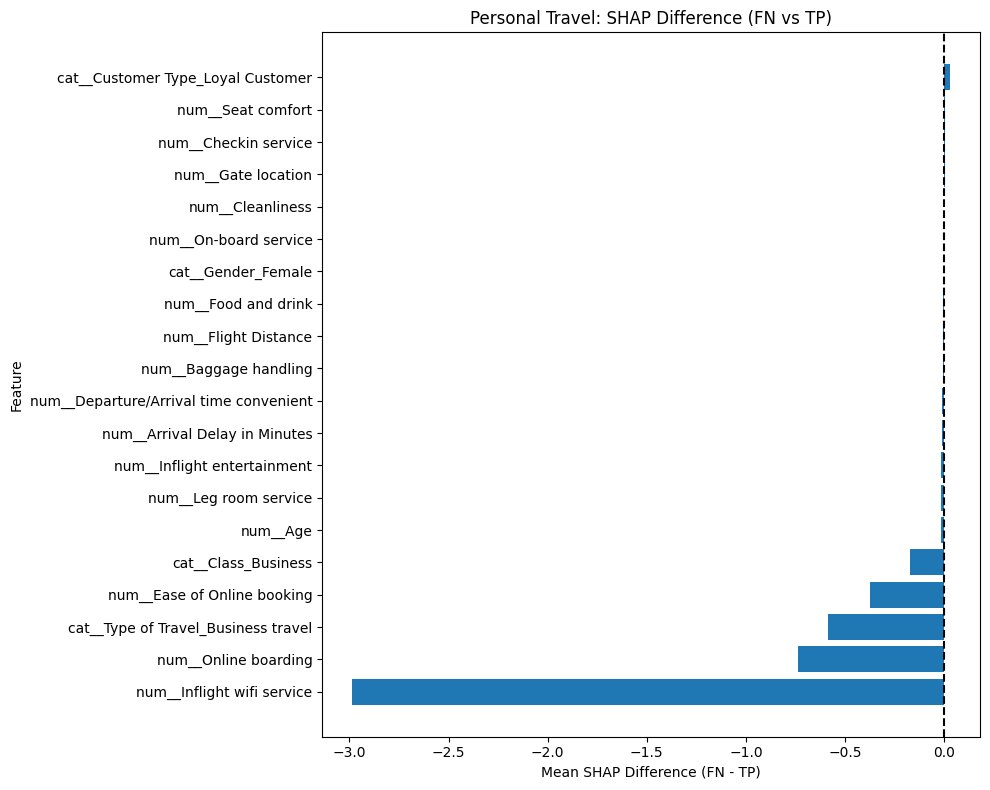

In [ ]:
# ==========================================================
# Personal Travel：FNとTPのSHAP値比較
# 学習済みLightGBMを使用（再学習なし）
# ==========================================================

# 1. 学習済みモデルの確認
model = lgb_tuned_final
model_lgb = model.named_steps["model"]
prep = model.named_steps["preprocessor"]

# 2. テストデータの予測確率
# X_testはDataFrame、y_testは0/1を想定
X_eval = X_test.copy()
y_eval = np.asarray(y_test).astype(int)

proba = model.predict_proba(X_eval)[:, 1]
pred = (proba >= 0.5).astype(int)

# 3. Personal Travelの満足顧客だけを抽出
mask = (
    (X_eval["Type of Travel"].to_numpy() == "Personal Travel")
    & (y_eval == 1)
)

X_personal = X_eval.iloc[np.flatnonzero(mask)].copy()
pred_personal = pred[mask]

# 4. FN / TPの分類
groups = np.where(pred_personal == 0, "FN", "TP")

print("【Personal Travel：満足顧客の分類】")
print(pd.Series(groups).value_counts())

# 5. 学習済み前処理を適用
X_processed = prep.transform(X_personal)

# SHAP計算用に特徴量名を取得
feature_names = prep.get_feature_names_out()

if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

X_processed = pd.DataFrame(
    X_processed,
    columns=feature_names
)

# 6. SHAP値を計算
explainer = shap.TreeExplainer(model_lgb)
shap_values = explainer.shap_values(X_processed)

# 二値分類で返り値の形式が異なる場合に対応
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif (
    isinstance(shap_values, np.ndarray)
    and shap_values.ndim == 3
):
    shap_values = shap_values[:, :, 1]

shap_values = np.asarray(shap_values)

assert shap_values.shape == X_processed.shape, (
    "SHAP値と特徴量の次元が一致しません"
)

# 7. FNとTPのSHAP平均値を比較
shap_df = pd.DataFrame(
    shap_values,
    columns=feature_names
)

shap_df["Prediction_Group"] = groups

summary = shap_df.groupby("Prediction_Group").mean().T

summary["Difference_FN_minus_TP"] = (
    summary["FN"] - summary["TP"]
)

summary["Abs_Difference"] = (
    summary["Difference_FN_minus_TP"].abs()
)

summary = summary.sort_values(
    "Abs_Difference",
    ascending=False
)

print("\n【FNとTPのSHAP値比較：上位20特徴量】")

display(summary.head(20).round(4))

# 8. SHAP値の差を可視化
top20 = summary.head(20).sort_values(
    "Difference_FN_minus_TP"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20.index,
    top20["Difference_FN_minus_TP"]
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Mean SHAP Difference (FN - TP)")
plt.ylabel("Feature")
plt.title("Personal Travel: SHAP Difference (FN vs TP)")

plt.tight_layout()
plt.show()

### Personal TravelにおけるFN・TPのSHAP値比較分析

#### 1. 分析目的

Personal Travelの満足顧客について、正しく満足と予測されたTPと、不満と誤予測されたFNのSHAP値を比較し、モデルの誤分類に関係する特徴量を明らかにする。

#### 2. 分析対象

- 対象：Personal Travelの満足顧客3,969件
- FN：2,618件（65.96%）
- TP：1,351件（34.04%）
- 使用モデル：最適化済みLightGBM
- 分類閾値：0.5

#### 3. SHAP値比較結果

| 特徴量 | FN平均SHAP | TP平均SHAP | 差（FN−TP） |
|---|---:|---:|---:|
| Inflight wifi service | 0.2223 | 3.2089 | -2.9866 |
| Online boarding | -0.0684 | 0.6702 | -0.7387 |
| Type of Travel（Business travel） | -1.6400 | -1.0561 | -0.5839 |
| Ease of Online booking | -0.0228 | 0.3530 | -0.3759 |
| Class（Business） | -0.2821 | -0.1091 | -0.1730 |

#### 4. 考察

FNとTPのSHAP値を比較した結果、機内Wi-Fi、オンライン搭乗手続き、オンライン予約の3特徴量で大きな差が確認された。

特に機内Wi-Fiの平均SHAP値の差は-2.9866であり、FNではTPに比べて満足方向への寄与が大幅に小さかった。

これは、前段階の特徴量平均値比較において、FNのデジタル関連サービス評価がTPより低かった結果とも整合する。

一方、到着遅延のSHAP値の差は-0.0092であり、今回の誤分類を区別する主要な特徴量ではなかった。

#### 5. 結論

Personal TravelのFNは、主にデジタル関連サービスの評価がモデル上の満足判定を弱めることと関連している可能性が示された。

ただし、SHAP値はモデルの予測に対する寄与を示すものであり、誤分類の因果関係を証明するものではない。

#### 6. 次の検証課題

- デジタル関連サービスの評価が低い満足顧客に着目した特徴量設計
- Personal Travelに対する分類閾値の調整
- 交差検証によるFN率、F1、ROC-AUC、Log Lossの比較
- 全体精度と旅行目的別性能の両立を確認

## Personal Travelのデジタル関連サービス評価を組み合わせた特徴量を追加し、LightGBMの精度が改善するか検証

In [ ]:
# 既存データをコピー
X_train_digital = X_train.copy()
X_test_digital = X_test.copy()

digital_cols = [
    "Inflight wifi service",
    "Online boarding",
    "Ease of Online booking"
]

def add_digital_features(X):
    X = X.copy()

    # 3項目の評価を集約
    X["Digital_Service_Mean"] = X[digital_cols].mean(axis=1)
    X["Digital_Service_Min"] = X[digital_cols].min(axis=1)
    X["Digital_Service_Range"] = (
        X[digital_cols].max(axis=1)
        - X[digital_cols].min(axis=1)
    )

    # Personal Travelなら1、それ以外なら0
    personal_flag = (
        X["Type of Travel"] == "Personal Travel"
    ).astype(int)

    # 旅行目的との交互作用
    X["Personal_x_Digital_Mean"] = (
        personal_flag * X["Digital_Service_Mean"]
    )

    X["Personal_x_Digital_Min"] = (
        personal_flag * X["Digital_Service_Min"]
    )

    return X

X_train_digital = add_digital_features(X_train_digital)
X_test_digital = add_digital_features(X_test_digital)

new_features = [
    "Digital_Service_Mean",
    "Digital_Service_Min",
    "Digital_Service_Range",
    "Personal_x_Digital_Mean",
    "Personal_x_Digital_Min"
]

print("追加した特徴量")
display(X_train_digital[new_features].head())

print("学習データ形状:", X_train_digital.shape)
print("テストデータ形状:", X_test_digital.shape)

追加した特徴量


,Digital_Service_Mean,Digital_Service_Min,Digital_Service_Range,Personal_x_Digital_Mean,Personal_x_Digital_Min
159366,2.333333,1,4,0.000000,0
659958,1.666667,1,1,0.000000,0
434666,1.666667,1,1,1.666667,1
427957,4.666667,4,1,0.000000,0
409049,2.000000,2,0,0.000000,0


学習データ形状: (559708, 26)
テストデータ形状: (139927, 26)


In [ ]:
# 既存の前処理から列名を取得
num_cols = list(
    preprocessor.transformers_[0][2]
)

cat_cols = list(
    preprocessor.transformers_[1][2]
)

# 新しい数値特徴量を追加
num_cols_digital = num_cols + new_features

# 前処理を拡張
preprocessor_digital = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(preprocessor.named_transformers_["num"]),
            num_cols_digital
        ),
        (
            "cat",
            clone(preprocessor.named_transformers_["cat"]),
            cat_cols
        )
    ]
)

print("数値特徴量:", len(num_cols_digital))
print("カテゴリ特徴量:", len(cat_cols))

数値特徴量: 22
カテゴリ特徴量: 4


In [ ]:
# 元データと追加特徴量データで同じ行を使用
idx_train, idx_valid = train_test_split(
    np.arange(len(X_train)),
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

y_arr = np.asarray(y_train)
y_fit = y_arr[idx_train]
y_valid = y_arr[idx_valid]

results = []
trained_models = {}

models_config = {
    "既存LightGBM": (
        X_train,
        preprocessor
    ),
    "デジタル特徴量追加LightGBM": (
        X_train_digital,
        preprocessor_digital
    )
}

for name, (X, prep) in models_config.items():

    model = Pipeline([
        ("preprocessor", clone(prep)),
        ("model", LGBMClassifier(
            **best_params,
            random_state=42,
            n_jobs=1,
            verbosity=-1
        ))
    ])

    model.fit(
        X.iloc[idx_train],
        y_fit
    )

    proba = model.predict_proba(
        X.iloc[idx_valid]
    )[:, 1]

    pred = (proba >= 0.5).astype(int)

    personal_mask = (
        X.iloc[idx_valid]["Type of Travel"]
        == "Personal Travel"
    ).to_numpy()

    y_personal = y_valid[personal_mask]
    pred_personal = pred[personal_mask]

    fn = np.sum(
        (y_personal == 1) &
        (pred_personal == 0)
    )

    tp = np.sum(
        (y_personal == 1) &
        (pred_personal == 1)
    )

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_valid, proba),
        "Log Loss": log_loss(y_valid, proba),
        "Accuracy": accuracy_score(y_valid, pred),
        "F1": f1_score(y_valid, pred),
        "Personal FN": fn,
        "Personal TP": tp,
        "Personal FN Rate": fn / (fn + tp)
    })

    trained_models[name] = model

comparison_digital = pd.DataFrame(results)

display(comparison_digital.round(5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,ROC-AUC,Log Loss,Accuracy,F1,Personal FN,Personal TP,Personal FN Rate
0,既存LightGBM,0.95866,0.22728,0.92592,0.91549,2124,1163,0.64618
1,デジタル特徴量追加LightGBM,0.95880,0.22703,0.92622,0.91578,2130,1157,0.64801


## デジタル関連サービスの特徴量追加によるLightGBMの精度検証

### 1. 分析目的

これまでのSHAP分析では、Personal Travelの満足顧客を不満と誤分類するFNにおいて、機内Wi-Fi、オンライン搭乗手続き、オンライン予約のSHAP値がTPより低い傾向が確認された。

そこで、これらのデジタル関連サービス評価を組み合わせた特徴量を追加し、LightGBMの予測精度およびPersonal TravelのFN率が改善するか検証した。

### 2. 追加した特徴量

| 特徴量 | 内容 |
|---|---|
| Digital_Service_Mean | デジタル関連3項目の平均評価 |
| Digital_Service_Min | デジタル関連3項目の最低評価 |
| Digital_Service_Range | デジタル関連3項目の最大値と最小値の差 |
| Personal_x_Digital_Mean | Personal Travelと平均評価の交互作用 |
| Personal_x_Digital_Min | Personal Travelと最低評価の交互作用 |

既存モデルと特徴量追加モデルには同じLightGBMのハイパーパラメータを使用し、同一の検証用データで比較した。

### 3. モデル性能の比較

| 評価指標 | 既存LightGBM | 特徴量追加LightGBM |
|---|---:|---:|
| ROC-AUC | 0.95866 | 0.95880 |
| Log Loss | 0.22728 | 0.22703 |
| Accuracy | 0.92592 | 0.92622 |
| F1 | 0.91549 | 0.91578 |
| Personal FN | 2,124件 | 2,130件 |
| Personal TP | 1,163件 | 1,157件 |
| Personal FN Rate | 64.62% | 64.80% |

※ 分類閾値は0.50とした。

### 4. 分析結果と考察

**① 全体的な予測性能**

特徴量追加モデルでは、ROC-AUCが0.95866から0.95880へ上昇し、Log Lossは0.22728から0.22703へ低下した。

AccuracyおよびF1もわずかに改善した。

したがって、追加特徴量によって全体的な予測性能が微小に改善する結果が得られた。

ただし、改善幅は非常に小さく、今回の1回の検証のみでは安定した改善と断定できない。

**② Personal TravelのFN率**

Personal TravelのFNは2,124件から2,130件へ6件増加した。

FN率も64.62%から64.80%へ約0.18ポイント悪化した。

そのため、今回追加した特徴量は、主な改善対象であるPersonal TravelのFN削減には寄与しなかった。

**③ SHAP分析との関係**

SHAP分析で大きな寄与が確認された特徴量を組み合わせても、必ずしも予測精度が改善するわけではない。

LightGBMは特徴量間の非線形な関係や交互作用を学習できるため、今回追加した特徴量が既存の情報と重複していた可能性がある。

### 5. 結論

デジタル関連サービスの特徴量追加により、LightGBMの全体的な予測性能はわずかに改善した。

一方、Personal TravelのFN率は64.62%から64.80%へ悪化した。

**したがって、今回の特徴量追加は、Personal TravelのFN削減という目的に対して有効性を確認できなかった。**

### 6. 次の検証方針

既存LightGBMを基準モデルとして、Personal Travelの分類閾値を調整する。

FN率だけでなく、FP率、Precision、Recall、F1および全体性能への影響も確認し、誤分類のバランスを考慮した閾値を検討する。

## Personal Travel（個人旅行）の分類閾値を最適化し、満足顧客を不満と誤判定するFNを減らせるか検証

In [ ]:
# 前回学習した既存LightGBMを使用
model = trained_models["既存LightGBM"]

# 前回と同じ検証用データ
X_valid = X_train.iloc[idx_valid].copy()
y_true = np.asarray(y_train)[idx_valid]

# 満足クラスの予測確率
proba = model.predict_proba(X_valid)[:, 1]

# Personal Travelの判定
personal_mask = (
    X_valid["Type of Travel"] == "Personal Travel"
).to_numpy()

business_mask = ~personal_mask

results_threshold = []

for threshold in np.arange(0.15, 0.51, 0.05):

    # Business travelは0.50固定
    pred = (proba >= 0.50).astype(int)

    # Personal Travelのみ閾値変更
    pred[personal_mask] = (
        proba[personal_mask] >= threshold
    ).astype(int)

    # Personal Travelの混同行列
    tn, fp, fn, tp = confusion_matrix(
        y_true[personal_mask],
        pred[personal_mask],
        labels=[0, 1]
    ).ravel()

    results_threshold.append({
        "Personal Threshold": round(threshold, 2),
        "Personal FN": fn,
        "Personal FP": fp,
        "Personal FN Rate": fn / (fn + tp),
        "Personal FP Rate": fp / (fp + tn),
        "Personal Precision": precision_score(
            y_true[personal_mask],
            pred[personal_mask],
            zero_division=0
        ),
        "Personal Recall": recall_score(
            y_true[personal_mask],
            pred[personal_mask],
            zero_division=0
        ),
        "Personal F1": f1_score(
            y_true[personal_mask],
            pred[personal_mask],
            zero_division=0
        ),
        "Overall Accuracy": accuracy_score(
            y_true, pred
        ),
        "Overall F1": f1_score(
            y_true, pred
        )
    })

threshold_df = pd.DataFrame(results_threshold)

display(threshold_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Personal Threshold,Personal FN,Personal FP,Personal FN Rate,Personal FP Rate,Personal Precision,Personal Recall,Personal F1,Overall Accuracy,Overall F1
0,0.15,1033,3148,0.3143,0.1078,0.4173,0.6857,0.5188,0.9083,0.8997
1,0.20,1162,2565,0.3535,0.0878,0.4531,0.6465,0.5328,0.9124,0.9035
2,0.25,1593,1313,0.4846,0.0450,0.5634,0.5154,0.5383,0.9197,0.9100
3,0.30,1924,496,0.5853,0.0170,0.7332,0.4147,0.5297,0.9241,0.9139
4,0.35,2053,231,0.6246,0.0079,0.8423,0.3754,0.5194,0.9253,0.9150
5,0.40,2090,149,0.6358,0.0051,0.8893,0.3642,0.5167,0.9257,0.9153
6,0.45,2107,116,0.6410,0.0040,0.9105,0.3590,0.5149,0.9258,0.9154
7,0.50,2124,90,0.6462,0.0031,0.9282,0.3538,0.5123,0.9259,0.9155


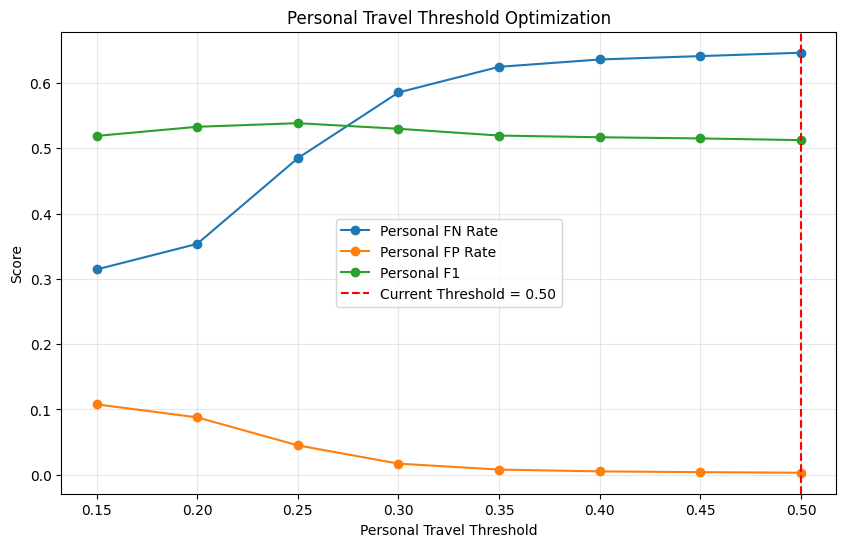

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Personal Threshold"],
    threshold_df["Personal FN Rate"],
    marker="o",
    label="Personal FN Rate"
)

plt.plot(
    threshold_df["Personal Threshold"],
    threshold_df["Personal FP Rate"],
    marker="o",
    label="Personal FP Rate"
)

plt.plot(
    threshold_df["Personal Threshold"],
    threshold_df["Personal F1"],
    marker="o",
    label="Personal F1"
)

plt.axvline(
    0.50,
    color="red",
    linestyle="--",
    label="Current Threshold = 0.50"
)

plt.xlabel("Personal Travel Threshold")
plt.ylabel("Score")
plt.title("Personal Travel Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# 閾値0.25と0.50の結果を比較
comparison = threshold_df[
    threshold_df["Personal Threshold"].round(2).isin([0.25, 0.50])
].copy()

display(comparison.round(4))

# 差分を計算（0.25 - 0.50）
baseline = comparison.loc[
    comparison["Personal Threshold"].round(2) == 0.50
].iloc[0]

candidate = comparison.loc[
    comparison["Personal Threshold"].round(2) == 0.25
].iloc[0]

metrics = [
    "Personal FN Rate",
    "Personal FP Rate",
    "Personal F1",
    "Overall Accuracy",
    "Overall F1"
]

diff = pd.DataFrame({
    "Metric": metrics,
    "Threshold 0.50": [baseline[m] for m in metrics],
    "Threshold 0.25": [candidate[m] for m in metrics],
    "Difference": [candidate[m] - baseline[m] for m in metrics]
})

display(diff.round(4))

,Personal Threshold,Personal FN,Personal FP,Personal FN Rate,Personal FP Rate,Personal Precision,Personal Recall,Personal F1,Overall Accuracy,Overall F1
2,0.25,1593,1313,0.4846,0.0450,0.5634,0.5154,0.5383,0.9197,0.9100
7,0.50,2124,90,0.6462,0.0031,0.9282,0.3538,0.5123,0.9259,0.9155


,Metric,Threshold 0.50,Threshold 0.25,Difference
0,Personal FN Rate,0.6462,0.4846,-0.1615
1,Personal FP Rate,0.0031,0.0450,0.0419
2,Personal F1,0.5123,0.5383,0.0260
3,Overall Accuracy,0.9259,0.9197,-0.0062
4,Overall F1,0.9155,0.9100,-0.0054


### Personal Travelにおける分類閾値の最適化結果

#### 目的
Personal Travelでは満足顧客の偽陰性（FN）が多く発生していたため、分類閾値を0.50から0.25に変更し、誤分類率とモデル全体の評価指標への影響を検証した。

#### 分析結果

| 評価指標 | 閾値0.50 | 閾値0.25 |
|---|---:|---:|
| Personal FN | 2,124 | 1,593 |
| Personal FP | 90 | 1,313 |
| Personal FN率 | 64.62% | 48.46% |
| Personal FP率 | 0.31% | 4.50% |
| Personal Precision | 0.9282 | 0.5634 |
| Personal Recall | 0.3538 | 0.5154 |
| Personal F1 | 0.5123 | 0.5383 |
| Overall Accuracy | 0.9259 | 0.9197 |
| Overall F1 | 0.9155 | 0.9100 |

#### 考察

分類閾値を0.25に変更することで、Personal TravelのFNは531件減少し、FN率は約16.15ポイント改善した。

また、Personal TravelのF1スコアは0.5123から0.5383に向上した。

一方、FPは1,223件増加し、Precisionは0.9282から0.5634に低下した。

さらに、モデル全体のAccuracyは0.9259から0.9197、F1スコアは0.9155から0.9100に低下した。

#### 結論

分類閾値の変更はPersonal TravelのFN削減に有効であったが、FPの増加と全体精度の低下を伴った。

したがって、閾値0.25の採用はFN削減を重視する場合の選択肢であり、全体精度を重視する場合には慎重な判断が必要である。

今後はPersonal Travelにおける誤分類要因をさらに分析し、旅行目的別モデルの構築などによって、FNとFPの両方を抑制できるか検証する。

## Personal Travel専用のLightGBMモデルを構築し、既存のLightGBMと比較

In [ ]:
# Personal Travelの行を抽出
train_mask = X_train["Type of Travel"].eq("Personal Travel")
test_mask = X_test["Type of Travel"].eq("Personal Travel")

X_train_personal = X_train.loc[train_mask].copy()
X_test_personal = X_test.loc[test_mask].copy()

y_train_personal = y_train.loc[train_mask].copy()
y_test_personal = y_test.loc[test_mask].copy()

print("Personal Travel 学習件数:", len(X_train_personal))
print("Personal Travel 評価件数:", len(X_test_personal))

print("\n学習データの満足率:")
print(y_train_personal.mean())

Personal Travel 学習件数: 161474
Personal Travel 評価件数: 40720

学習データの満足率:
0.09721069645887263


In [ ]:
#personal_model = Pipeline([
#    ("preprocessor", clone(preprocessor)),
#    ("model", LGBMClassifier(
#        **best_params,
#        random_state=42,
#        n_jobs=-1,
#        verbosity=-1
#    ))
#])
#
#personal_model.fit(
#    X_train_personal,
#    y_train_personal
#)
#
#print("Personal Travel専用モデルの学習完了")

In [ ]:
#drive.mount("/content/drive")
#
#save_dir = "/content/drive/MyDrive/airline_models"
#os.makedirs(save_dir, exist_ok=True)
#
#joblib.dump(
#    personal_model,
#    f"{save_dir}/personal_travel_lightgbm.joblib"
#)
#
#print("保存完了")

In [ ]:
for name in [
    "lgb_tuned_final",
    "personal_model",
    "X_test_personal",
    "y_test_personal"
]:
    print(
        f"{name}:",
        "OK" if name in globals() else "未定義"
    )

lgb_tuned_final: OK
personal_model: 未定義
X_test_personal: OK
y_test_personal: OK


In [ ]:
save_dir = Path("/content/drive/MyDrive/airline_models")
model_path = save_dir / "personal_travel_lightgbm.joblib"

if not model_path.exists():
    raise FileNotFoundError(f"モデルが見つかりません: {model_path}")

personal_model = joblib.load(model_path)

print("Personal Travel専用モデルの復元が完了しました")
print(type(personal_model))

Personal Travel専用モデルの復元が完了しました
<class 'sklearn.pipeline.Pipeline'>


In [ ]:
models_personal = {
    "既存LightGBM": lgb_tuned_final,
    "Personal専用LightGBM": personal_model
}

results_personal = []

for name, model in models_personal.items():

    proba = model.predict_proba(X_test_personal)[:, 1]
    pred = (proba >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_personal,
        pred,
        labels=[0, 1]
    ).ravel()

    results_personal.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test_personal, proba),
        "Log Loss": log_loss(y_test_personal, proba),
        "Accuracy": accuracy_score(y_test_personal, pred),
        "Precision": precision_score(
            y_test_personal, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_personal, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test_personal, pred, zero_division=0
        ),
        "FN": fn,
        "FP": fp,
        "FN Rate": fn / (fn + tp),
        "FP Rate": fp / (fp + tn)
    })

comparison_personal = pd.DataFrame(results_personal)

display(comparison_personal.round(5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,ROC-AUC,Log Loss,Accuracy,Precision,Recall,F1,FN,FP,FN Rate,FP Rate
0,既存LightGBM,0.82353,0.21528,0.93244,0.91038,0.34039,0.49551,2618,133,0.65961,0.00362
1,Personal専用LightGBM,0.82379,0.21683,0.93247,0.91044,0.34064,0.49578,2617,133,0.65936,0.00362


## 予測確率の校正（Calibration）を検証

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


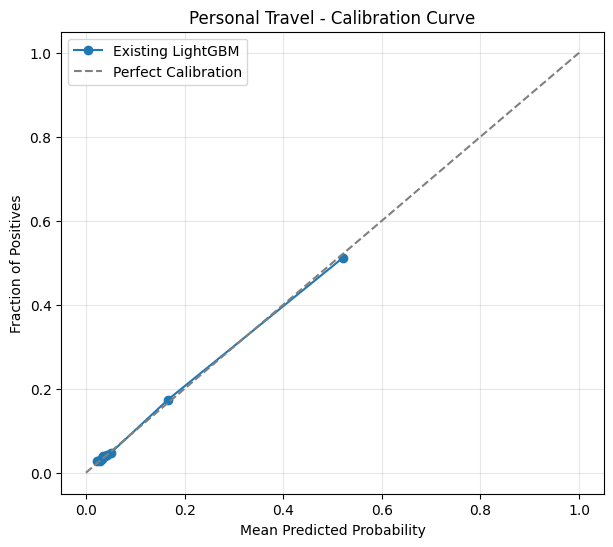

Brier Score: 0.05709
Log Loss: 0.21528


In [ ]:
# 既存LightGBMの予測確率
proba_personal = lgb_tuned_final.predict_proba(
    X_test_personal
)[:, 1]

# Calibration Curve
prob_true, prob_pred = calibration_curve(
    y_test_personal,
    proba_personal,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Existing LightGBM"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Personal Travel - Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Brier Score:",
    round(brier_score_loss(y_test_personal, proba_personal), 5)
)

print(
    "Log Loss:",
    round(log_loss(y_test_personal, proba_personal), 5)
)

### Personal Travel：既存LightGBMのキャリブレーション分析

#### 1. 分析目的
Personal Travelにおいて、既存LightGBMが予測した満足確率と、実際の満足率がどの程度一致しているかを検証した。

#### 2. 分析結果
- **Brier Score：0.05709**
- **Log Loss：0.21528**
- キャリブレーション曲線は、表示された予測確率の範囲で理想線（予測確率＝実際の満足率）とおおむね一致した。
- ただし、表示された点は主に予測確率0〜0.5付近に集中しており、高確率領域の評価は限定的である。

#### 3. 考察
予測確率と実際の満足率には、表示された範囲で大きな乖離が見られず、キャリブレーションはおおむね良好と考えられる。

一方、これまでの誤分類分析では、Personal Travelの満足顧客を不満足と判定する偽陰性（FN）が多いことが確認されている。これは、予測確率の調整状態と、分類閾値0.5による判定性能が異なる評価対象であるため、矛盾しない。

#### 4. 結論
既存LightGBMのPersonal Travelに対する確率予測は、観測された確率帯では実際の満足率とおおむね整合している。ただし、FNの多さという課題は残っており、分類閾値の検討が引き続き重要である。

## 既存LightGBMとPersonal Travel専用LightGBMのキャリブレーションを同じ条件で比較する

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


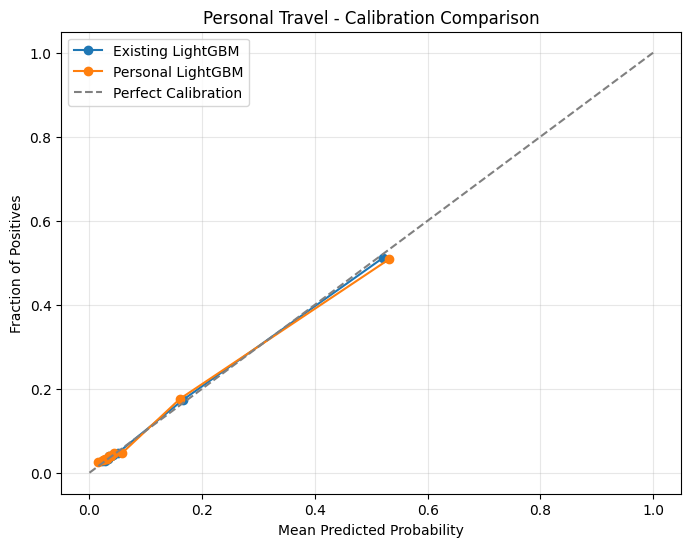

,Model,Brier Score,Log Loss
0,Existing LightGBM,0.05709,0.21528
1,Personal LightGBM,0.05738,0.21683


In [ ]:
models = {
    "Existing LightGBM": lgb_tuned_final,
    "Personal LightGBM": personal_model
}

plt.figure(figsize=(8, 6))

results = []

for name, model in models.items():

    proba = model.predict_proba(X_test_personal)[:, 1]

    fraction_pos, mean_pred = calibration_curve(
        y_test_personal,
        proba,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_pred,
        fraction_pos,
        marker="o",
        label=name
    )

    results.append({
        "Model": name,
        "Brier Score": brier_score_loss(
            y_test_personal, proba
        ),
        "Log Loss": log_loss(
            y_test_personal, proba
        )
    })

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Personal Travel - Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

display(pd.DataFrame(results).round(5))

## Personal Travelにおけるキャリブレーション比較分析

### 1. 分析目的
既存LightGBMとPersonal Travel専用LightGBMについて、予測確率の信頼性（キャリブレーション）を比較し、専用モデルの構築によって予測性能が改善するか検証した。

### 2. 評価結果

| 評価指標 | 既存LightGBM | Personal Travel専用LightGBM |
|---|---:|---:|
| Brier Score | 0.05709 | 0.05738 |
| Log Loss | 0.21528 | 0.21683 |

※ Brier ScoreおよびLog Lossは、いずれも値が小さいほど良い。

### 3. 分析結果

- 両モデルのキャリブレーション曲線はほぼ重なっており、表示された予測確率の範囲では理想線に近い傾向が確認された。
- Brier Scoreは既存LightGBMが0.05709、Personal Travel専用LightGBMが0.05738であり、既存モデルがわずかに良好だった。
- Log Lossも既存LightGBMが0.21528、専用モデルが0.21683であり、既存モデルの方が良好だった。
- ただし、評価指標の差は小さく、統計的に有意な差があるかどうかは未検証である。
- グラフ上では予測確率0.5を超える領域の評価点が十分に確認できず、高確率領域のキャリブレーションについては判断が難しい。

### 4. 考察

Personal Travelのデータだけで学習した専用LightGBMは、既存LightGBMと比較して予測確率の精度を改善しなかった。

この結果から、Personal Travel専用モデルを新たに構築するだけでは、既存モデルが抱えるFN（実際は満足している顧客を不満足と予測する誤分類）の問題を解決できない可能性がある。

ただし、キャリブレーション性能と分類性能は異なるため、FN削減効果については分類閾値を含めて別途評価する必要がある。

### 5. 結論と今後の方針

今回の比較では、既存LightGBMの方がBrier ScoreとLog Lossの両方でわずかに良好であり、Personal Travel専用LightGBMの優位性は確認できなかった。

今後は既存LightGBMを基準モデルとし、Personal Travelの分類閾値を調整してFN削減とFP増加のトレードオフを検証する。

分類閾値は検証データで選定し、独立したテストデータで最終性能を評価する。

## Personal TravelのFN（偽陰性）を減らすために、分類閾値を最適化

In [ ]:
# Personal Travelの学習データから検証用データを作成
X_fit_personal, X_val_personal, y_fit_personal, y_val_personal = train_test_split(
    X_train_personal,
    y_train_personal,
    test_size=0.20,
    random_state=42,
    stratify=y_train_personal
)

print("再学習用データ:", len(X_fit_personal))
print("検証データ:", len(X_val_personal))
print("最終テストデータ:", len(X_test_personal))

再学習用データ: 129179
検証データ: 32295
最終テストデータ: 40720


In [ ]:
# 検証データに対する満足確率
# X_val_personal は学習時と同じ前処理・列順であること
proba_val = lgb_tuned_final.predict_proba(
    X_val_personal
)[:, 1]

y_true = np.asarray(y_val_personal).astype(int)

# 閾値候補
thresholds = np.arange(0.05, 0.951, 0.01)

results = []

for threshold in thresholds:

    pred = (proba_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "FN": fn,
        "FP": fp,
        "FN Rate": fn / (fn + tp),
        "FP Rate": fp / (fp + tn),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

# FN Rate 50%以下を条件とする
candidates = threshold_df[
    threshold_df["FN Rate"] <= 0.50
].copy()

if candidates.empty:
    print("FN Rate 50%以下を満たす閾値がありません。")
else:
    # 条件内でFP Rateが最も低い閾値
    best_row = candidates.sort_values(
        ["FP Rate", "F1"],
        ascending=[True, False]
    ).iloc[0]

    best_threshold = float(best_row["Threshold"])

    print(f"最適閾値: {best_threshold:.2f}")
    display(best_row.to_frame().T.round(4))

# 0.50と0.25も比較
display(
    threshold_df[
        np.isclose(threshold_df["Threshold"], 0.50)
        | np.isclose(threshold_df["Threshold"], 0.25)
    ].round(4)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


最適閾値: 0.28


,Threshold,FN,FP,FN Rate,FP Rate,Precision,Recall,F1
23,0.28,1547.0,692.0,0.4928,0.0237,0.697,0.5072,0.5871


,Threshold,FN,FP,FN Rate,FP Rate,Precision,Recall,F1
20,0.25,1324,1334,0.4218,0.0458,0.5764,0.5782,0.5773
45,0.50,1960,94,0.6244,0.0032,0.9262,0.3756,0.5345


In [ ]:
# 既存モデルの設定をコピー
lgb_validation = clone(lgb_tuned_final)

# 検証データの行を学習データから除外
val_indices = X_val_personal.index

X_fit = X_train.drop(index=val_indices)
y_fit = y_train.loc[X_fit.index]

# 検証データを除いたデータで再学習
lgb_validation.fit(X_fit, y_fit)

# 未学習の検証データで予測
proba_val = lgb_validation.predict_proba(
    X_val_personal
)[:, 1]

print("検証用モデルの学習・予測が完了しました")
print("再学習データ数:", len(X_fit))
print("検証データ数:", len(X_val_personal))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


検証用モデルの学習・予測が完了しました
再学習データ数: 527413
検証データ数: 32295


In [ ]:
# 検証データの正解ラベル
y_true = np.asarray(y_val_personal).astype(int)

# 閾値候補
thresholds = np.arange(0.05, 0.951, 0.01)

results = []

for threshold in thresholds:

    pred = (proba_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "FN": fn,
        "FP": fp,
        "FN Rate": fn / (fn + tp),
        "FP Rate": fp / (fp + tn),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

# FN Rate 50%以下の閾値を抽出
candidates = threshold_df[
    threshold_df["FN Rate"] <= 0.50
].copy()

if candidates.empty:
    print("条件を満たす閾値がありません。")
else:
    # FP Rateが最小、同率ならF1が最大
    best_row = candidates.sort_values(
        ["FP Rate", "F1"],
        ascending=[True, False]
    ).iloc[0]

    best_threshold = float(best_row["Threshold"])

    print(f"最適閾値: {best_threshold:.2f}")
    display(best_row.to_frame().T.round(4))

print("\n閾値0.25と0.50の比較")
display(
    threshold_df[
        np.isclose(threshold_df["Threshold"], 0.25)
        | np.isclose(threshold_df["Threshold"], 0.50)
    ].round(4)
)

最適閾値: 0.26


,Threshold,FN,FP,FN Rate,FP Rate,Precision,Recall,F1
21,0.26,1528.0,1240.0,0.4868,0.0425,0.5651,0.5132,0.5379



閾値0.25と0.50の比較


,Threshold,FN,FP,FN Rate,FP Rate,Precision,Recall,F1
20,0.25,1437,1485,0.4578,0.0509,0.5340,0.5422,0.5381
45,0.50,1968,104,0.6270,0.0036,0.9184,0.3730,0.5306


In [ ]:
# 検証データで決定した閾値
final_threshold = 0.26

# 既存の学習済みモデルで最終テストデータを予測
proba_test = lgb_tuned_final.predict_proba(
    X_test_personal
)[:, 1]

y_true_test = np.asarray(y_test_personal).astype(int)

results_test = []

for threshold in [0.50, final_threshold]:

    pred = (proba_test >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true_test, pred, labels=[0, 1]
    ).ravel()

    results_test.append({
        "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_true_test, proba_test),
        "Log Loss": log_loss(y_true_test, proba_test),
        "Accuracy": accuracy_score(y_true_test, pred),
        "Precision": precision_score(y_true_test, pred),
        "Recall": recall_score(y_true_test, pred),
        "F1": f1_score(y_true_test, pred),
        "FN": fn,
        "FP": fp,
        "FN Rate": fn / (fn + tp),
        "FP Rate": fp / (fp + tn)
    })

final_comparison = pd.DataFrame(results_test)

display(final_comparison.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Threshold,ROC-AUC,Log Loss,Accuracy,Precision,Recall,F1,FN,FP,FN Rate,FP Rate
0,0.50,0.8235,0.2153,0.9324,0.9104,0.3404,0.4955,2618,133,0.6596,0.0036
1,0.26,0.8235,0.2153,0.9126,0.5583,0.4931,0.5237,2012,1548,0.5069,0.0421


## Personal Travelにおける分類閾値最適化：最終テストデータでの評価

### 1. 分析目的

Personal Travel（個人旅行）の顧客に対して、LightGBMの分類閾値を調整することで、FN（偽陰性）を削減できるか検証した。

検証データで「FN Rate 50%以下」という条件を設定し、その条件を満たす閾値のうち、FP Rateが最小となる閾値を選択した。

検証データで選択された閾値は **0.26** であり、最終テストデータ40,720件を用いて、従来の閾値0.50と比較した。

### 2. 最終テストデータでの評価結果

| 評価指標 | 閾値0.50 | 閾値0.26 |
|---|---:|---:|
| ROC-AUC | 0.8235 | 0.8235 |
| Log Loss | 0.2153 | 0.2153 |
| Accuracy | 0.9324 | 0.9126 |
| Precision | 0.9104 | 0.5583 |
| Recall | 0.3404 | 0.4931 |
| F1 | 0.4955 | 0.5237 |
| FN（偽陰性） | 2,618 | 2,012 |
| FP（偽陽性） | 133 | 1,548 |
| FN Rate | 65.96% | 50.69% |
| FP Rate | 0.36% | 4.21% |

### 3. 分析結果

**① FN（偽陰性）の削減**

分類閾値を0.50から0.26に変更した結果、FNは2,618件から2,012件となり、606件（約23.1%）減少した。

また、Recallは0.3404から0.4931に改善した。

このことから、閾値を下げることで、本来満足している顧客を不満足と誤判定するケースを減らせることが確認できた。

**② FP（偽陽性）の増加**

一方、FPは133件から1,548件へ増加した。

FP Rateも0.36%から4.21%に上昇しており、本来不満足である顧客を満足と誤判定するケースが増加した。

したがって、FN削減とFP増加の間にはトレードオフが存在する。

**③ F1スコアの改善**

F1スコアは0.4955から0.5237に改善した。

一方、Accuracyは0.9324から0.9126に低下した。

これは、FNの削減によってRecallが改善したものの、FPの増加によってPrecisionが低下したためである。

**④ ROC-AUCとLog Lossの変化**

ROC-AUCは0.8235、Log Lossは0.2153であり、閾値変更前後で変化しなかった。

これは、モデルの予測確率自体は変更せず、満足・不満足を分類する閾値のみを変更したためである。

### 4. 検証データと最終テストデータの比較

| 評価指標 | 検証データ | 最終テストデータ |
|---|---:|---:|
| 分類閾値 | 0.26 | 0.26 |
| FN Rate | 48.68% | 50.69% |
| FP Rate | 4.25% | 4.21% |

検証データではFN Rate 50%以下という目標を達成したが、最終テストデータでは50.69%となり、目標をわずかに達成できなかった。

この結果から、検証データで最適化した閾値が、未知データでも同等の性能を示すとは限らないことが確認された。

### 5. 結論

Personal Travelにおいて、分類閾値を0.50から0.26に変更することで、FNを606件削減し、F1スコアを改善できた。

一方で、FPは1,415件増加しており、FN削減とFP増加のトレードオフが明確になった。

また、最終テストデータにおけるFN Rateは50.69%であり、当初設定した50%以下の目標には届かなかった。

**今回の分析から、分類閾値の最適化は誤分類の内訳を調整する有効な方法である一方、モデルの識別能力自体を改善するものではないことが確認された。**

今後は、FNとFPの業務上の重要度を考慮しながら、特徴量の改善やモデルの再学習によって、両方の誤分類を抑制できるか検討する。

## Stratified 5-Fold交差検証

In [ ]:
# 既存の学習済みモデルの設定を使用
# 各Foldでは新しいモデルを作成して再学習する
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []
oof_proba = np.zeros(len(X_train))

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train, y_train), start=1
):
    X_tr = X_train.iloc[train_idx]
    X_val = X_train.iloc[val_idx]

    y_tr = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    # 学習済みモデルの設定だけコピー
    model = clone(lgb_tuned_final)

    # 学習
    model.fit(X_tr, y_tr)

    # 検証データの満足確率
    proba = model.predict_proba(X_val)[:, 1]

    # OOF予測確率を保存
    oof_proba[val_idx] = proba

    # 評価
    auc = roc_auc_score(y_val, proba)
    loss = log_loss(y_val, proba)

    cv_results.append({
        "Fold": fold,
        "ROC-AUC": auc,
        "Log Loss": loss
    })

    print(
        f"Fold {fold}: "
        f"ROC-AUC = {auc:.5f}, "
        f"Log Loss = {loss:.5f}"
    )

# 結果を表形式に整理
cv_df = pd.DataFrame(cv_results)

display(cv_df.round(5))

print("\n===== 5-Fold CV Summary =====")
print(
    f"平均ROC-AUC: "
    f"{cv_df['ROC-AUC'].mean():.5f}"
)
print(
    f"ROC-AUC標準偏差: "
    f"{cv_df['ROC-AUC'].std():.5f}"
)
print(
    f"平均Log Loss: "
    f"{cv_df['Log Loss'].mean():.5f}"
)

print(
    f"OOF ROC-AUC: "
    f"{roc_auc_score(y_train, oof_proba):.5f}"
)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1: ROC-AUC = 0.95891, Log Loss = 0.22602


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 2: ROC-AUC = 0.95835, Log Loss = 0.22955


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 3: ROC-AUC = 0.95887, Log Loss = 0.22723


... (2 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 5: ROC-AUC = 0.95796, Log Loss = 0.22935


,Fold,ROC-AUC,Log Loss
0,1,0.95891,0.22602
1,2,0.95835,0.22955
2,3,0.95887,0.22723
3,4,0.95892,0.22575
4,5,0.95796,0.22935



===== 5-Fold CV Summary =====
平均ROC-AUC: 0.95860
ROC-AUC標準偏差: 0.00043
平均Log Loss: 0.22758
OOF ROC-AUC: 0.95859


### Stratified 5-Fold交差検証の結果

既存のLightGBMモデルについて、Stratified 5-Fold交差検証を実施した。

**評価結果**

| Fold | ROC-AUC | Log Loss |
|---|---:|---:|
| 1 | 0.95891 | 0.22602 |
| 2 | 0.95835 | 0.22955 |
| 3 | 0.95887 | 0.22723 |
| 4 | 0.95892 | 0.22575 |
| 5 | 0.95796 | 0.22935 |

- 平均ROC-AUC：0.95860
- ROC-AUC標準偏差：0.00043
- 平均Log Loss：0.22758
- OOF ROC-AUC：0.95859
- 学習時間：約3分

**考察**

5つのFoldにおけるROC-AUCは0.95796〜0.95892の範囲に収まり、標準偏差も0.00043と小さかった。この結果から、既存のLightGBMモデルはデータ分割による性能変動が比較的小さく、安定した識別性能を示していると考えられる。

今後は本結果をベースラインとし、特徴量エンジニアリングやモデルの改良によってROC-AUCが改善するか検証する。

なお、交差検証スコアはKaggleの未知データに対する性能を保証するものではないため、最終的には独立したテストデータおよびKaggleの提出結果によって評価する。

## 特徴量エンジニアリング

In [ ]:
# 元データは変更せずコピーする

X_train_fe = X_train.copy()

# オンライン搭乗手続き × 機内Wi-Fi
X_train_fe["online_wifi_interaction"] = (
    X_train_fe["Online boarding"]
    * X_train_fe["Inflight wifi service"]
)

# オンライン搭乗手続きと機内Wi-Fiの評価差
X_train_fe["online_wifi_gap"] = (
    X_train_fe["Online boarding"]
    - X_train_fe["Inflight wifi service"]
)

# 機内エンターテインメント × 座席快適性
X_train_fe["entertainment_seat_interaction"] = (
    X_train_fe["Inflight entertainment"]
    * X_train_fe["Seat comfort"]
)

print("元の特徴量数:", X_train.shape[1])
print("追加後の特徴量数:", X_train_fe.shape[1])

display(
    X_train_fe[
        [
            "online_wifi_interaction",
            "online_wifi_gap",
            "entertainment_seat_interaction"
        ]
    ].head()
)

元の特徴量数: 21
追加後の特徴量数: 24


,online_wifi_interaction,online_wifi_gap,entertainment_seat_interaction
159366,5,4,25
659958,2,1,1
434666,2,1,16
427957,20,1,25
409049,4,0,15


In [ ]:
# 前回と同じ分割条件
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

datasets = {
    "Baseline_21features": X_train,
    "FeatureEngineering_24features": X_train_fe
}

results = []
oof_predictions = {}

for dataset_name, X_data in datasets.items():

    print(f"\n===== {dataset_name} =====")

    oof_proba = np.zeros(len(X_data))

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_data, y_train), start=1
    ):

        X_tr = X_data.iloc[train_idx]
        X_val = X_data.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        # 前回と同じLightGBMの設定を使用
        model = clone(lgb_tuned_final)

        model.fit(X_tr, y_tr)

        proba = model.predict_proba(X_val)[:, 1]

        oof_proba[val_idx] = proba

        auc = roc_auc_score(y_val, proba)
        loss = log_loss(y_val, proba)

        results.append({
            "Dataset": dataset_name,
            "Fold": fold,
            "ROC-AUC": auc,
            "Log Loss": loss
        })

        print(
            f"Fold {fold}: "
            f"ROC-AUC = {auc:.5f}, "
            f"Log Loss = {loss:.5f}"
        )

    oof_predictions[dataset_name] = oof_proba

# 各Foldの結果
results_df = pd.DataFrame(results)

display(results_df.round(5))

# 平均値・標準偏差
summary = results_df.groupby("Dataset").agg(
    Mean_AUC=("ROC-AUC", "mean"),
    Std_AUC=("ROC-AUC", "std"),
    Mean_LogLoss=("Log Loss", "mean")
)

# OOF ROC-AUC
for name, proba in oof_predictions.items():
    summary.loc[name, "OOF_AUC"] = roc_auc_score(
        y_train, proba
    )

display(summary.round(5))

# 特徴量追加による改善幅
auc_diff = (
    summary.loc["FeatureEngineering_24features", "OOF_AUC"]
    - summary.loc["Baseline_21features", "OOF_AUC"]
)

print(f"\nOOF ROC-AUCの変化: {auc_diff:+.5f}")


===== Baseline_21features =====


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 1: ROC-AUC = 0.95891, Log Loss = 0.22602


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold 2: ROC-AUC = 0.95835, Log Loss = 0.22955


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (14 outputs left out)

Fold 5: ROC-AUC = 0.95796, Log Loss = 0.22935


,Dataset,Fold,ROC-AUC,Log Loss
0,Baseline_21features,1,0.95891,0.22602
1,Baseline_21features,2,0.95835,0.22955
2,Baseline_21features,3,0.95887,0.22723
3,Baseline_21features,4,0.95892,0.22575
4,Baseline_21features,5,0.95796,0.22935
5,FeatureEngineering_24features,1,0.95891,0.22602
6,FeatureEngineering_24features,2,0.95835,0.22955
7,FeatureEngineering_24features,3,0.95887,0.22723
8,FeatureEngineering_24features,4,0.95892,0.22575
9,FeatureEngineering_24features,5,0.95796,0.22935


,Mean_AUC,Std_AUC,Mean_LogLoss,OOF_AUC
Dataset,,,,
Baseline_21features,0.9586,0.00043,0.22758,0.95859
FeatureEngineering_24features,0.9586,0.00043,0.22758,0.95859



OOF ROC-AUCの変化: +0.00000


## 特徴量エンジニアリングによるLightGBMの精度検証

### 1. 分析目的

既存の21特徴量に対して、顧客満足度に関連すると考えられるサービス評価の交互作用特徴量を3つ追加し、LightGBMの予測性能が改善するか検証した。

### 2. 追加した特徴量

以下の3特徴量を新たに作成した。

- `online_wifi_interaction`：オンライン搭乗手続きと機内Wi-Fiサービスの評価を組み合わせた特徴量
- `online_wifi_gap`：オンライン搭乗手続きと機内Wi-Fiサービスの評価差を表す特徴量
- `entertainment_seat_interaction`：機内エンターテインメントと座席快適性の評価を組み合わせた特徴量

特徴量数は21から24に増加した。

### 3. 検証方法

- モデル：LightGBM
- 検証方法：Stratified 5-Fold交差検証
- 乱数シード：42
- 比較条件：同一のデータ分割・モデル設定
- 評価指標：ROC-AUC、Log Loss、OOF ROC-AUC

### 4. 検証結果

| 評価指標 | 既存21特徴量 | 追加後24特徴量 |
|---|---:|---:|
| 平均ROC-AUC | 0.95860 | 0.95860 |
| ROC-AUC標準偏差 | 0.00043 | 0.00043 |
| 平均Log Loss | 0.22758 | 0.22758 |
| OOF ROC-AUC | 0.95859 | 0.95859 |

**OOF ROC-AUCの変化：+0.00000（表示精度上）**

5つのFoldすべてでROC-AUCとLog Lossが表示桁数では一致しており、今回の特徴量追加による明確な精度改善は確認されなかった。

### 5. 考察

今回の3特徴量は、既存の特徴量から算出できる交互作用や評価差を表している。

LightGBMは決定木を用いた勾配ブースティングモデルであり、特徴量間の非線形な関係や相互作用を学習できる。そのため、追加した特徴量が既存の特徴量と重複する情報を持ち、新たな予測情報として寄与しなかった可能性がある。

また、追加特徴量がモデルの分岐に採用されなかった可能性も考えられる。

ただし、評価指標は丸めて表示されているため、モデルの予測確率まで完全に一致しているかは現時点では不明である。

### 6. 結論と今後の方針

今回の特徴量エンジニアリングでは、**既存21特徴量のLightGBMを上回る予測性能は確認できなかった。**

したがって、現時点では既存21特徴量モデルをベースラインとして維持する。

今後は以下を検証する。

1. 21特徴量モデルと24特徴量モデルのOOF予測確率を比較し、実際に予測結果が変化しているか確認する。
2. 追加特徴量の重要度を調べ、モデルで利用されているか検証する。
3. CatBoostなど異なるアルゴリズムとの比較やアンサンブルを検討する。


## 予測確率の差を確認

In [ ]:
# 保存済みのOOF予測を取得
oof_21 = oof_predictions["Baseline_21features"]
oof_24 = oof_predictions["FeatureEngineering_24features"]

# 予測確率の差
diff = np.abs(oof_21 - oof_24)

print("【OOF予測確率の比較】")
print(f"最大絶対差: {diff.max():.12f}")
print(f"平均絶対差: {diff.mean():.12f}")
print(f"差が1e-10を超える件数: {(diff > 1e-10).sum():,}")
print(f"完全一致: {np.array_equal(oof_21, oof_24)}")

print("\n【評価指標の詳細比較】")
for name, proba in [
    ("21特徴量", oof_21),
    ("24特徴量", oof_24)
]:
    print(
        f"{name}: "
        f"ROC-AUC={roc_auc_score(y_train, proba):.10f}, "
        f"Log Loss={log_loss(y_train, proba):.10f}"
    )

【OOF予測確率の比較】
最大絶対差: 0.000000000000
平均絶対差: 0.000000000000
差が1e-10を超える件数: 0
完全一致: True

【評価指標の詳細比較】
21特徴量: ROC-AUC=0.9585871197, Log Loss=0.2275794426
24特徴量: ROC-AUC=0.9585871197, Log Loss=0.2275794426


## 特徴量エンジニアリング後のOOF予測確率の比較

### 1. 分析目的

既存の21特徴量と、新たに3特徴量を追加した24特徴量のLightGBMについて、5-Fold交差検証で得られたOOF（Out-of-Fold）予測確率を比較する。

前回の検証ではROC-AUCとLog Lossが表示桁数で一致していたため、実際の予測確率に違いがあるかを確認した。

### 2. 検証結果

| 評価項目 | 結果 |
|---|---:|
| 最大絶対差 | 0.000000000000 |
| 平均絶対差 | 0.000000000000 |
| 差が1e-10を超える件数 | 0件 |
| 予測確率の完全一致 | True |

**評価指標の比較**

| 評価指標 | 21特徴量 | 24特徴量 |
|---|---:|---:|
| OOF ROC-AUC | 0.9585871197 | 0.9585871197 |
| OOF Log Loss | 0.2275794426 | 0.2275794426 |

### 3. 考察

21特徴量モデルと24特徴量モデルのOOF予測確率は、すべてのサンプルで完全に一致した。

この結果から、今回追加した3特徴量は、現在のLightGBMの設定において予測結果に影響を与えていないことが確認された。

考えられる要因として、以下が挙げられる。

- 追加特徴量が決定木の分岐に採用されなかった可能性
- 元の特徴量から十分に学習できる情報であり、追加してもモデルの分割構造が変化しなかった可能性
- 追加特徴量が既存特徴量と重複する情報を持っていた可能性

ただし、予測確率の一致だけでは原因を特定できないため、特徴量重要度の確認が必要である。

### 4. 結論

**今回の3特徴量の追加による予測性能の改善は認められなかった。**

21特徴量モデルと24特徴量モデルでは、OOF予測確率および評価指標が完全に一致していた。

そのため、現時点では特徴量数が少なく構成も単純な21特徴量モデルをベースラインとして維持する。

### 5. 今後の方針

1. 追加した3特徴量の重要度を確認し、LightGBMの学習で使用されているか調べる。
2. CatBoostなど別のアルゴリズムによる予測性能を比較する。
3. LightGBMとCatBoostのアンサンブルを検討し、ROC-AUCの改善を目指す。

## 追加特徴量の重要度を調べる

In [ ]:
# 現在メモリ上に存在するモデルを確認
model_names = [
    "lgb_model",
    "model_fe",
    "lgb_fe_fixed",
    "lgb_tuned_final"
]

for name in model_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: 存在する ({type(obj).__name__})")
    else:
        print(f"{name}: 存在しない")

lgb_model: 存在する (Pipeline)
model_fe: 存在しない
lgb_fe_fixed: 存在しない
lgb_tuned_final: 存在する (Pipeline)


In [ ]:
# 追加した3特徴量
new_features = [
    "online_wifi_interaction",
    "online_wifi_gap",
    "entertainment_seat_interaction"
]

# 入力データに特徴量が存在するか確認
print("【入力データの確認】")
print("入力特徴量数:", X_train_fe.shape[1])

for feature in new_features:
    print(feature, feature in X_train_fe.columns)

missing = [
    f for f in new_features
    if f not in X_train_fe.columns
]

if missing:
    raise ValueError(f"入力データに特徴量がありません: {missing}")


# 元のPipelineを複製
lgb_fe_fixed = clone(lgb_tuned_final)

print("\n【Pipelineの構成】")
print(list(lgb_fe_fixed.named_steps.keys()))

# 前処理ステップ名を取得
preprocessor_name = next(
    (
        name
        for name, step in lgb_fe_fixed.named_steps.items()
        if isinstance(step, ColumnTransformer)
    ),
    None
)

if preprocessor_name is None:
    raise ValueError(
        "Pipeline内にColumnTransformerが見つかりません"
    )

old_preprocessor = (
    lgb_fe_fixed.named_steps[preprocessor_name]
)

# 新しい前処理器の設定
transformers = []
added = False

for name, transformer, columns in old_preprocessor.transformers:

    if name == "num":

        updated_columns = list(columns)

        for feature in new_features:
            if feature not in updated_columns:
                updated_columns.append(feature)

        added = True

    else:
        updated_columns = columns

    # passthrough / drop はcloneしない
    if isinstance(transformer, str):
        new_transformer = transformer
    else:
        new_transformer = clone(transformer)

    transformers.append(
        (name, new_transformer, updated_columns)
    )

if not added:
    raise ValueError(
        "numという名前の数値前処理が見つかりません"
    )

# 新しいColumnTransformer
new_preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=old_preprocessor.sparse_threshold,
    n_jobs=old_preprocessor.n_jobs,
    transformer_weights=old_preprocessor.transformer_weights,
    verbose=old_preprocessor.verbose,
    verbose_feature_names_out=old_preprocessor.verbose_feature_names_out
)

# Pipelineに設定
lgb_fe_fixed.set_params(
    **{preprocessor_name: new_preprocessor}
)

# 再学習
lgb_fe_fixed.fit(X_train_fe, y_train)

# 学習済み前処理器
fitted_preprocessor = (
    lgb_fe_fixed.named_steps[preprocessor_name]
)

feature_names = fitted_preprocessor.get_feature_names_out()

print("\n【特徴量数】")
print("入力特徴量数:", X_train_fe.shape[1])
print("前処理後特徴量数:", len(feature_names))

print("\n【追加した3特徴量の確認】")

for feature in new_features:
    matched = [
        name
        for name in feature_names
        if feature in name
    ]
    print(feature, ":", matched)

# LightGBMモデルを取得
lgb_model = lgb_fe_fixed.named_steps["model"]

# 特徴量重要度
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lgb_model.feature_importances_
})

print("\n【追加した3特徴量の重要度】")

display(
    importance_df[
        importance_df["Feature"].apply(
            lambda x: any(
                feature in x
                for feature in new_features
            )
        )
    ].sort_values(
        "Importance",
        ascending=False
    )
)

print(
    "\n重要度0の特徴量数:",
    (importance_df["Importance"] == 0).sum()
)

【入力データの確認】
入力特徴量数: 24
online_wifi_interaction True
online_wifi_gap True
entertainment_seat_interaction True

【Pipelineの構成】
['preprocessor', 'model']

【特徴量数】
入力特徴量数: 24
前処理後特徴量数: 29

【追加した3特徴量の確認】
online_wifi_interaction : ['num__online_wifi_interaction']
online_wifi_gap : ['num__online_wifi_gap']
entertainment_seat_interaction : ['num__entertainment_seat_interaction']

【追加した3特徴量の重要度】


,Feature,Importance
17,num__online_wifi_interaction,1293
19,num__entertainment_seat_interaction,1260
18,num__online_wifi_gap,1039



重要度0の特徴量数: 0


In [ ]:
# 特徴量追加後のモデルを取得
model_fe = lgb_fe_fixed

# Pipelineの構成を確認
print("Pipelineの構成:")
print(list(model_fe.named_steps.keys()))

# 学習済みLightGBMを取得
lgb_model_fe = model_fe.named_steps["model"]

# 前処理後の特徴量名を取得
feature_names_fe = (
    model_fe.named_steps["preprocessor"]
    .get_feature_names_out()
)

# 特徴量重要度を取得
importance_df_fe = pd.DataFrame({
    "Feature": feature_names_fe,
    "Importance": lgb_model_fe.feature_importances_
})

# 追加した3特徴量
new_features = [
    "online_wifi_interaction",
    "online_wifi_gap",
    "entertainment_seat_interaction"
]

# 特徴量数を確認
print("\n【特徴量数】")
print("前処理後:", len(feature_names_fe))
print("モデルの特徴量数:", lgb_model_fe.n_features_in_)

# 追加特徴量の存在確認
print("\n【追加した3特徴量の確認】")
for feature in new_features:
    matched = [
        name for name in feature_names_fe
        if feature in name
    ]
    print(f"{feature}: {matched}")

# 追加特徴量の重要度
print("\n【追加した3特徴量の重要度】")
display(
    importance_df_fe[
        importance_df_fe["Feature"].apply(
            lambda x: any(f in x for f in new_features)
        )
    ].sort_values("Importance", ascending=False)
)

# 重要度0の特徴量数
print(
    "\n重要度0の特徴量数:",
    (importance_df_fe["Importance"] == 0).sum()
)

In [ ]:
# 元データと前処理後の特徴量数を比較
print("【特徴量数の確認】")
print("入力データの特徴量数:", X_train_fe.shape[1])
print("前処理後の特徴量数:", len(feature_names))

# 追加した3特徴量が入力データに存在するか
print("\n【入力データの確認】")
for feature in new_features:
    print(feature, ":", feature in X_train_fe.columns)

# 前処理後の特徴量名を確認
print("\n【前処理後の特徴量名】")
for feature in feature_names:
    print(feature)

# 前処理後に追加特徴量が残っているか
print("\n【追加特徴量の確認】")
for feature in new_features:
    matched = [
        name for name in feature_names
        if feature in name
    ]
    print(feature, ":", matched)

In [ ]:
# 学習済み前処理後の特徴量名
feature_names = list(
    lgb_fe_fixed.named_steps["preprocessor"]
    .get_feature_names_out()
)

# ① 特徴量名の重複
feature_series = pd.Series(feature_names)

print("【特徴量名の重複確認】")
print("前処理後の特徴量数:", len(feature_names))
print("ユニークな特徴量数:", feature_series.nunique())

duplicates = feature_series[
    feature_series.duplicated(keep=False)
]

print("重複している特徴量名:")
print(duplicates.tolist())

# ② 特徴量の値が完全に一致する列を確認
X_transformed = (
    lgb_fe_fixed.named_steps["preprocessor"]
    .transform(X_train_fe)
)

if hasattr(X_transformed, "toarray"):
    # メモリ負荷を抑えるため、一部の行で一次確認
    X_check = X_transformed[:10000].toarray()
else:
    X_check = np.asarray(X_transformed[:10000])

df_check = pd.DataFrame(
    X_check,
    columns=feature_names
)

duplicate_values = df_check.T.duplicated(keep=False)

print("\n【特徴量の値の重複確認】")
print("先頭10,000行で値が完全一致する列:")
print(df_check.columns[duplicate_values].tolist())

# 特徴量エンジニアリング後のLightGBM再学習と検証

## 1. 分析の目的

航空会社の顧客満足度予測モデルの精度向上を目的として、新たに作成した3つの特徴量をLightGBMに追加し、その有効性を検証する。

今回の検証では、以下の項目を確認した。

1. 追加特徴量が学習データに存在しているか
2. 既存の前処理Pipelineに追加特徴量が正しく反映されているか
3. LightGBMが追加特徴量を学習に利用しているか
4. 追加特徴量の重要度がどの程度あるか
5. 特徴量名や特徴量の値に重複がないか

## 2. 追加した特徴量

以下の3特徴量を追加した。

| 特徴量名 | 着目した情報 |
|---|---|
| `online_wifi_interaction` | Online boardingとInflight wifi serviceの組み合わせ |
| `online_wifi_gap` | Online boardingとInflight wifi serviceの評価差 |
| `entertainment_seat_interaction` | Inflight entertainmentとSeat comfortの組み合わせ |

### 特徴量追加の仮説

顧客満足度は、個々のサービス評価だけでなく、複数のサービスの組み合わせや評価の差によっても説明できる可能性がある。

特に、オンライン関連サービスや機内の快適性に関する評価の組み合わせが、満足度の予測に役立つと考えた。

## 3. 追加特徴量の存在確認

まず、学習データ `X_train_fe` に新たな3特徴量が存在するかを確認した。

**検証結果**

| 特徴量 | 存在確認 |
|---|---|
| `online_wifi_interaction` | True |
| `online_wifi_gap` | True |
| `entertainment_seat_interaction` | True |

入力データの特徴量数は24であり、3特徴量が追加済みであることを確認した。

一方、当初の前処理Pipelineでは、前処理後の特徴量に追加した3特徴量が含まれていなかった。

これは、学習データに新しい列が存在していても、`ColumnTransformer` の処理対象に指定されていなければ、モデルに入力されないためである。

## 4. 前処理Pipelineの修正

既存の学習済みPipelineを複製し、数値特徴量を処理する `ColumnTransformer` に追加した3特徴量を登録した。

修正時には、以下の点に注意した。

- 既存の数値・カテゴリ変数の前処理設定を維持する。
- 数値特徴量の処理対象に新しい3特徴量を追加する。
- `passthrough` や `drop` などの文字列指定を、不適切に `clone()` しない。
- 既存のPipelineを直接変更せず、別のモデルとして再学習する。

これにより、既存の前処理構成を維持しながら、新しい特徴量をLightGBMに入力できるようにした。

## 5. LightGBMの再学習

修正したPipelineを使用して、特徴量追加後のLightGBMを再学習した。

**再学習後の確認結果**

| 確認項目 | 結果 |
|---|---:|
| 入力特徴量数 | 24 |
| 前処理後の特徴量数 | 29 |
| 追加した3特徴量の前処理後の存在 | すべて確認 |

前処理後の特徴量数が入力特徴量数より多いのは、カテゴリ変数がOne-Hot Encodingによって複数列に展開されるためである。

追加した3特徴量は、それぞれ以下の名前で前処理後のデータに含まれていた。

- `num__online_wifi_interaction`
- `num__online_wifi_gap`
- `num__entertainment_seat_interaction`

以上から、追加した特徴量がモデルへの入力に反映されていることを確認した。

## 6. 追加特徴量の重要度評価

再学習後のLightGBMから、特徴量重要度を取得した。

### 検証結果

| 特徴量 | Importance |
|---|---:|
| `online_wifi_interaction` | 1,293 |
| `entertainment_seat_interaction` | 1,260 |
| `online_wifi_gap` | 1,039 |

3特徴量とも重要度が0を上回っており、LightGBMの学習に利用されていることが確認できた。

### 考察

`online_wifi_interaction` は、追加した3特徴量の中で最も高い重要度を示した。

また、`entertainment_seat_interaction` と `online_wifi_gap` についても、モデルが分岐に利用していることが確認された。

この結果は、サービス評価の組み合わせや評価差が、顧客満足度の予測に利用可能な情報を含んでいる可能性を示唆している。

ただし、今回の重要度はLightGBMの `feature_importances_` に基づくものであり、重要度が高いことだけでは、予測精度の改善や因果関係を証明できない。

## 7. 特徴量の重複確認

特徴量エンジニアリングによって、同一の特徴量が重複して登録されていないかを確認した。

検証では、以下の2点を調べた。

1. 前処理後の特徴量名が重複していないか
2. 前処理後の特徴量の値が完全に一致する列が存在しないか

### 検証結果

| 確認項目 | 結果 |
|---|---:|
| 前処理後の特徴量数 | 29 |
| ユニークな特徴量数 | 29 |
| 重複している特徴量名 | 0件 |
| 先頭10,000行で値が完全一致する列 | 0件 |

### 考察

前処理後の29特徴量について、特徴量名の重複は確認されなかった。

また、先頭10,000行のデータにおいて、値が完全に一致する特徴量も確認されなかった。

ただし、今回の検証では、特徴量間の高い相関や、元の特徴量から計算できる派生特徴量の情報的な重複までは評価していない。

## 8. 今回の分析結果のまとめ

今回の特徴量エンジニアリングと検証により、以下のことを確認できた。

- 新しい3特徴量が学習データに存在している。
- 前処理Pipelineを修正し、3特徴量をモデルに入力できた。
- LightGBMの再学習が正常に完了した。
- 3特徴量すべての重要度が0より大きかった。
- 前処理後の29特徴量に名前の重複はなかった。
- 検査対象の先頭10,000行では、値が完全一致する特徴量は確認されなかった。

以上より、**追加した3特徴量がLightGBMの学習に正しく組み込まれていることを確認できた。**

一方、これらの特徴量が実際に予測性能を改善したかどうかは、まだ判断できない。

## 9. 今後の分析方針

### ① 特徴量追加前後のモデル比較

同一の学習データ・検証データ・ハイパーパラメータを使用し、特徴量追加前後のLightGBMを比較する。

主な評価指標は以下とする。

- ROC-AUC
- Log Loss
- Precision
- Recall
- F1-score
- 混同行列

### ② Personal Travelの誤分類分析

これまでのEDAで着目してきたPersonal Travelについて、特徴量追加前後の予測結果を比較する。

特に、満足している顧客を不満足と予測するFalse Negative（FN）の変化を確認する。

### ③ 特徴量の寄与の追加検証

必要に応じてSHAPを使用し、追加した特徴量が予測にどのように寄与しているかを調べる。

また、3特徴量を個別に追加・除外するアブレーション分析を行い、それぞれの特徴量が予測性能に与える影響を検証する。

### ④ 他のアルゴリズムとの比較

LightGBMの検証後、CatBoostなどのモデルとの比較を行い、必要に応じてアンサンブル学習を検討する。

---

**現時点での結論**

追加した3特徴量は、LightGBMに正しく組み込まれ、学習時に利用されていることが確認できた。今後は、特徴量重要度だけでなく、未学習データに対する予測性能の変化を検証し、特徴量エンジニアリングの有効性を評価する。

## 特徴量エンジニアリングによる説明変数の増加（21 → 29特徴量）

### 1. 概要

本分析では、航空会社の顧客満足度予測モデル（LightGBM）の性能向上を目的として、特徴量エンジニアリングを実施した。

元の説明変数21個に対して、新たに3個の派生特徴量を追加した。また、カテゴリ変数にOne-Hot Encodingを適用した結果、モデルへの入力特徴量数は最終的に29個となった。

| 処理段階 | 特徴量数 |
|---|---:|
| 元の説明変数 | 21 |
| 派生特徴量3個を追加 | 24 |
| One-Hot Encoding後 | 29 |

### 2. 新たに作成した3個の特徴量

| 特徴量名 | 使用する元の特徴量 | 目的 |
|---|---|---|
| `online_wifi_interaction` | Online boarding、Inflight wifi service | オンライン搭乗手続きと機内Wi-Fiの組み合わせによる満足度への影響を捉える |
| `online_wifi_gap` | Online boarding、Inflight wifi service | 2つのデジタルサービスに対する評価の差を捉える |
| `entertainment_seat_interaction` | Inflight entertainment、Seat comfort | 機内エンターテインメントと座席の快適性の組み合わせを捉える |

これらは既存の特徴量から生成した派生特徴量であり、元のデータには存在しない新しい評価指標としてモデルに追加した。

特に、単独のサービス評価だけでは捉えきれない、サービス同士の組み合わせや評価の不一致をモデルに学習させることを目的としている。

※ 各特徴量の厳密な計算式は、特徴量生成コードに従う。

### 3. One-Hot Encodingによる特徴量数の増加

元のデータには4個のカテゴリ変数が存在する。

これらをOne-Hot Encodingによって数値変換することで、4列が9列に展開され、特徴量数が5個増加した。

| カテゴリ変数 | 元の列数 | 変換後の列数 | 増加数 |
|---|---:|---:|---:|
| Gender | 1 | 2 | +1 |
| Customer Type | 1 | 2 | +1 |
| Type of Travel | 1 | 2 | +1 |
| Class | 1 | 3 | +2 |
| **合計** | **4** | **9** | **+5** |

One-Hot Encodingは新たな情報を生成する処理ではなく、カテゴリ情報を機械学習モデルが扱いやすい数値形式へ変換する処理である。

### 4. 最終的な29特徴量の内訳

| 特徴量の種類 | 特徴量数 |
|---|---:|
| 元の数値特徴量 | 17 |
| 新規作成した派生特徴量 | 3 |
| One-Hot Encoding後のカテゴリ特徴量 | 9 |
| **合計** | **29** |

したがって、説明変数21個から29個への増加は、以下の2つの処理によるものである。

- 特徴量エンジニアリングによる3個の追加
- One-Hot Encodingによる5個の純増

### 5. 特徴量の重要度と重複確認

追加した3特徴量について、LightGBMの特徴量重要度を確認した。

| 特徴量名 | Importance |
|---|---:|
| `online_wifi_interaction` | 1293 |
| `entertainment_seat_interaction` | 1260 |
| `online_wifi_gap` | 1039 |

いずれも重要度が0を上回っており、学習済みLightGBMがこれらの特徴量を分岐に利用していることが確認できた。

ただし、この重要度はモデル内部での利用状況を表すものであり、特徴量の追加によって予測性能が改善したことを直接証明するものではない。

また、前処理後の29特徴量について、以下の重複確認を実施した。

- 特徴量名の重複：なし
- 先頭10,000行における値が完全一致する特徴量列：なし

したがって、今回確認した範囲では、同名の特徴量や値が完全一致する特徴量は存在しなかった。

ただし、特徴量間の相関や情報の重複まで否定するものではない。

### 6. 考察と今後の方針

今回の特徴量エンジニアリングでは、サービス評価の交互作用や評価差をモデルに追加することができた。

追加した3特徴量はいずれもLightGBMで利用されており、顧客満足度予測に有用である可能性が示唆された。

一方で、特徴量数が増加すること自体は、予測性能の向上を保証しない。

今後は、同一の学習・検証データ分割および評価条件の下で、以下の2モデルを比較する。

1. **Model A：派生特徴量を追加しないモデル**
2. **Model B：派生特徴量3個を追加したモデル**

評価指標にはROC-AUCおよびLog Lossを使用し、追加特徴量による汎化性能への影響を検証する。

**最終的には、特徴量重要度の大きさだけでなく、検証データにおける予測性能の改善を根拠として、追加特徴量の有効性を判断する。**

## 追加した3つの特徴量が、本当にLightGBMの予測性能向上に貢献しているかを検証する

In [ ]:
drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/Airline_Satisfaction/models"
)

if SAVE_DIR.exists():
    print("【保存済みファイル一覧】")
    for file in sorted(SAVE_DIR.iterdir()):
        print(file.name)
else:
    print("保存先フォルダが見つかりません")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
【保存済みファイル一覧】
cat_cv_results.joblib
catboost.cbm
lgb_best_params.joblib
lgb_cv_results.joblib
lgb_tuned_cv_results.joblib
lgb_tuned_final.joblib
lightgbm.joblib
lightgbm_optuna.db
logistic_regression.joblib
lr_cv_results.joblib
model_comparison.joblib


In [ ]:
# 学習データと検証データの存在確認
data_names = [
    "X_train",
    "X_valid",
    "X_train_fe",
    "X_valid_fe",
    "X_train_feature",
    "X_valid_feature",
    "X_train_base",
    "X_valid_base",
    "y_train",
    "y_valid",
    "y_valid_actual"
]

for name in data_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: 存在する / shape={getattr(obj, 'shape', '不明')}")
    else:
        print(f"{name}: 存在しない")

In [ ]:
# 追加した3つの特徴量
new_features = [
    "online_wifi_interaction",
    "online_wifi_gap",
    "entertainment_seat_interaction"
]

# 学習データに存在するか確認
print("【追加特徴量の確認】")

for feature in new_features:
    print(f"{feature}: {feature in X_train_fe.columns}")

# 特徴量の値を確認
display(X_train_fe[new_features].head(10))

# 元データの列名を確認
print("\n【元データの列名】")
print(X_valid.columns.tolist())

In [ ]:
# 検証データをコピー
X_valid_fe = X_valid.copy()

# 追加特徴量を作成
X_valid_fe["online_wifi_interaction"] = (
    X_valid_fe["Online boarding"]
    * X_valid_fe["Inflight wifi service"]
)

X_valid_fe["online_wifi_gap"] = (
    X_valid_fe["Online boarding"]
    - X_valid_fe["Inflight wifi service"]
).abs()

X_valid_fe["entertainment_seat_interaction"] = (
    X_valid_fe["Inflight entertainment"]
    * X_valid_fe["Seat comfort"]
)

# 列の順番を学習データと一致させる
X_valid_fe = X_valid_fe[X_train_fe.columns]

print("学習データ:", X_train_fe.shape)
print("検証データ:", X_valid_fe.shape)

display(X_valid_fe[
    [
        "online_wifi_interaction",
        "online_wifi_gap",
        "entertainment_seat_interaction"
    ]
].head())

In [ ]:
# チューニング済みPipelineからパラメータを取得
base_pipeline = lgb_tuned_final

# 追加特徴量なし
model_a = clone(base_pipeline)

# 追加特徴量あり
model_b = clone(base_pipeline)

# 同じ条件で学習
print("Model A：21特徴量で学習")
model_a.fit(X_train, y_train)

print("Model B：24特徴量で学習")
model_b.fit(X_train_fe, y_train)

# 検証データで予測
proba_a = model_a.predict_proba(X_valid)[:, 1]
proba_b = model_b.predict_proba(X_valid_fe)[:, 1]

# 評価
auc_a = roc_auc_score(y_valid, proba_a)
auc_b = roc_auc_score(y_valid, proba_b)

loss_a = log_loss(y_valid, proba_a)
loss_b = log_loss(y_valid, proba_b)

comparison_df = pd.DataFrame({
    "Model": [
        "Model A（21特徴量）",
        "Model B（24特徴量）"
    ],
    "ROC-AUC": [auc_a, auc_b],
    "Log Loss": [loss_a, loss_b]
})

display(comparison_df.round(6))

print(f"ROC-AUCの変化: {auc_b - auc_a:+.6f}")
print(f"Log Lossの変化: {loss_b - loss_a:+.6f}")

In [ ]:
# Model AとModel Bの前処理後の特徴量を確認

features_a = model_a.named_steps["preprocessor"].get_feature_names_out()
features_b = model_b.named_steps["preprocessor"].get_feature_names_out()

new_features = [
    "online_wifi_interaction",
    "online_wifi_gap",
    "entertainment_seat_interaction"
]

print("Model Aの特徴量数:", len(features_a))
print("Model Bの特徴量数:", len(features_b))

print("\n【Model Bに追加特徴量が存在するか】")

for feature in new_features:
    matched = [
        name for name in features_b
        if feature in name
    ]
    print(f"{feature}: {matched}")

Model Aの特徴量数: 26
Model Bの特徴量数: 26

【Model Bに追加特徴量が存在するか】
online_wifi_interaction: []
online_wifi_gap: []
entertainment_seat_interaction: []


In [ ]:
new_features = [
    "online_wifi_interaction",
    "online_wifi_gap",
    "entertainment_seat_interaction"
]

# 元のチューニング済みPipelineを複製
model_a = clone(lgb_tuned_final)
model_b = clone(lgb_tuned_final)

# Model Bの前処理器を取得
old_preprocessor = model_b.named_steps["preprocessor"]

# 既存の前処理設定を取得
transformers = []

for name, transformer, columns in old_preprocessor.transformers:
    if name == "num":
        updated_columns = list(columns) + new_features
    else:
        updated_columns = columns

    transformers.append(
        (name, clone(transformer) if not isinstance(transformer, str)
         else transformer, updated_columns)
    )

# 追加特徴量を含む前処理器
new_preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# Model Bに設定
model_b.set_params(preprocessor=new_preprocessor)

# 特徴量数を確認
model_a.fit(X_train, y_train)
model_b.fit(X_train_fe, y_train)

features_a = model_a.named_steps["preprocessor"].get_feature_names_out()
features_b = model_b.named_steps["preprocessor"].get_feature_names_out()

print("Model A:", len(features_a))
print("Model B:", len(features_b))

for feature in new_features:
    print(feature, [f for f in features_b if feature in f])

In [ ]:
# 検証データで予測
proba_a = model_a.predict_proba(X_valid)[:, 1]
proba_b = model_b.predict_proba(X_valid_fe)[:, 1]

# 評価指標
auc_a = roc_auc_score(y_valid, proba_a)
auc_b = roc_auc_score(y_valid, proba_b)

loss_a = log_loss(y_valid, proba_a)
loss_b = log_loss(y_valid, proba_b)

comparison_df = pd.DataFrame({
    "Model": ["Model A（21特徴量）", "Model B（24特徴量）"],
    "ROC-AUC": [auc_a, auc_b],
    "Log Loss": [loss_a, loss_b]
})

display(comparison_df.round(6))

print(f"ROC-AUCの変化: {auc_b - auc_a:+.6f}")
print(f"Log Lossの変化: {loss_b - loss_a:+.6f}")

## 追加した3特徴量によるLightGBMの予測性能改善効果の検証

### 1. 分析目的

特徴量エンジニアリングによって追加した3つの特徴量が、LightGBMの顧客満足度予測性能の向上に貢献するかを検証する。

### 2. 検証対象の特徴量

| 特徴量 | 内容 |
|---|---|
| `online_wifi_interaction` | オンライン搭乗手続きと機内Wi-Fiサービスの評価値の積 |
| `online_wifi_gap` | オンライン搭乗手続きと機内Wi-Fiサービスの評価値の差の絶対値 |
| `entertainment_seat_interaction` | 機内エンターテインメントと座席快適性の評価値の積 |

これらの特徴量は、サービス間の相互作用や評価の不一致を捉えることを目的として作成した。

### 3. 検証方法

以下の2つのLightGBMモデルを比較した。

- **Model A：** 元の21特徴量を使用したモデル
- **Model B：** 元の21特徴量に3特徴量を追加した24特徴量のモデル

同一の学習データ・検証データを使用し、ROC-AUCおよびLog Lossによって予測性能を評価した。

ROC-AUCは高いほど、Log Lossは低いほど予測性能が優れていると判断する。

### 4. 検証結果

| 評価指標 | Model A（21特徴量） | Model B（24特徴量） | 変化量（B − A） |
|---|---:|---:|---:|
| ROC-AUC | **0.966060** | 0.965919 | -0.000141 |
| Log Loss | **0.216478** | 0.218238 | +0.001761 |

追加特徴量を使用したModel Bでは、ROC-AUCが低下し、Log Lossも増加した。

したがって、今回の検証では、3特徴量を追加することによる予測性能の改善は確認できなかった。

### 5. 考察

追加した3特徴量は、LightGBMの特徴量重要度分析において、いずれも利用されていることが確認された。

しかし、**特徴量重要度が高いことと、未知データに対する予測性能の向上に貢献することは同義ではない。**

今回の結果から、以下の可能性が考えられる。

1. LightGBMは決定木を用いるため、元の特徴量からサービス間の非線形な関係や相互作用をある程度学習できている。
2. 追加特徴量が元の特徴量と重複した情報を含んでおり、新たな予測情報を十分に提供できていない。
3. 特徴量の追加によってモデルの複雑さが増し、検証データに対する汎化性能がわずかに低下した可能性がある。

ただし、これらは結果を説明するための仮説であり、今回の比較だけで原因を特定することはできない。

また、検証データの分割や学習条件によって結果が変化する可能性もあるため、3特徴量が一般的に無効であるとまでは結論づけられない。

### 6. 結論と今後の方針

今回の検証では、追加した3特徴量はLightGBMの予測性能向上に寄与しなかった。

そのため、**最終モデルの候補としては、追加特徴量を使用しない21特徴量のLightGBMを優先する。**

今後は、以下の方針で最終モデルを選定する。

1. チューニング済みLightGBMとCatBoostの予測性能を比較する。
2. 検証データにおけるROC-AUCを主要指標として、最終モデルを選定する。
3. 選定したモデルでKaggleのテストデータを予測し、提出用CSVを作成する。

**今回の分析から、特徴量エンジニアリングでは特徴量重要度だけでなく、検証データにおける予測性能の変化を確認することが重要であると分かった。**

## 最終比較を実行する

In [ ]:
# 最終候補モデル
models = {
    "LightGBM（Optuna）": lgb_tuned_final,
    "CatBoost": cat_model_loaded
}

results = []

for name, model in models.items():

    proba = model.predict_proba(X_valid)[:, 1]

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_valid, proba),
        "Log Loss": log_loss(y_valid, proba)
    })

final_comparison = pd.DataFrame(results)

display(
    final_comparison
    .sort_values("ROC-AUC", ascending=False)
    .round(6)
)

### 最終モデルの比較と選定

Optunaによってハイパーパラメータを最適化したLightGBMとCatBoostについて、同一の検証データを用いて予測性能を比較した。

| モデル | ROC-AUC | Log Loss |
|---|---:|---:|
| LightGBM（Optuna） | **0.966060** | **0.216478** |
| CatBoost | 0.959415 | 0.227463 |

LightGBMはCatBoostよりもROC-AUCが高く、Log Lossも低かった。

また、特徴量エンジニアリングによって追加した3特徴量は、検証データでの予測性能改善につながらなかった。

以上の結果から、最終提出モデルとして、元の21特徴量を使用したOptunaチューニング済みLightGBMを選定した。

今後は、このモデルを使用してKaggleのテストデータに対する満足確率を予測し、提出用CSVファイルを作成する。

In [ ]:
# 最終モデル
final_model = lgb_tuned_final

# モデルが使用する特徴量を確認
print("使用する特徴量:")
print(final_model.feature_names_in_)

# Kaggleテストデータを確認
print("testの形状:", test.shape)
print("testの列名:")
print(test.columns.tolist())

In [ ]:
# 最終モデル
final_model = lgb_tuned_final

# 学習時の21特徴量を取得
feature_cols = list(final_model.feature_names_in_)

# テストデータから同じ21特徴量を抽出
X_test = test[feature_cols].copy()

# 特徴量の確認
print("テストデータの形状:", X_test.shape)
print("欠損値の合計:", X_test.isna().sum().sum())

# 満足する確率を予測
test_proba = final_model.predict_proba(X_test)[:, 1]

print("予測件数:", len(test_proba))
print("予測確率の先頭5件:", test_proba[:5])

テストデータの形状: (299844, 21)
欠損値の合計: 130


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


予測件数: 299844
予測確率の先頭5件: [0.21999367 0.8290015  0.90069939 0.07826441 0.0563558 ]


In [ ]:
# 提出用データフレーム
submission = pd.DataFrame({
    "id": test["id"],
    "satisfaction": test_proba
})

# CSVとして保存
submission.to_csv("submission.csv", index=False)

# 内容を確認
display(submission.head())

print("提出データの形状:", submission.shape)
print("欠損値:", submission.isna().sum().sum())

In [ ]:
files.download("submission.csv")

## Optunaで最適化したLightGBMを、検証データも含めた全学習データで再学習

In [ ]:
# ① 学習データと検証データを結合
X_full = pd.concat(
    [X_train, X_valid],
    axis=0,
    ignore_index=True
)

# ② 目的変数を結合（NumPy配列に対応）
y_full = np.concatenate([
    np.asarray(y_train),
    np.asarray(y_valid)
])

# データの確認
print("全学習データ:", X_full.shape)
print("正解ラベル:", y_full.shape)

# ③ Optunaで最適化したモデルを複製
lgb_full = clone(lgb_tuned_final)

# ④ 全学習データで再学習
lgb_full.fit(X_full, y_full)

print("全学習データによる再学習が完了しました。")

全学習データ: (671650, 21)
正解ラベル: (671650,)


KeyboardInterrupt: 

In [ ]:
# ① 再学習モデルでテストデータを予測
feature_cols = list(lgb_full.feature_names_in_)
X_test_full = test[feature_cols].copy()

test_proba_full = lgb_full.predict_proba(X_test_full)[:, 1]

# ② 提出データを作成
submission_full = pd.DataFrame({
    "id": test["id"],
    "satisfaction": test_proba_full
})

# ③ データの検証
assert len(submission_full) == len(test)
assert submission_full["id"].equals(test["id"])
assert submission_full.notna().all().all()
assert submission_full["satisfaction"].between(0, 1).all()

print("提出データの形状:", submission_full.shape)
print("欠損値:", submission_full.isna().sum().sum())

display(submission_full.head())

# ④ CSV保存・ダウンロード
submission_full.to_csv(
    "submission_full_train.csv",
    index=False
)

files.download("submission_full_train.csv")

## LightGBMとCatBoostのアンサンブル学習

In [140]:
# ① 学習済みモデルを使用
lgb_model = lgb_tuned_final
cat_model = cat_model_loaded

# ② 検証データの予測確率
lgb_proba = lgb_model.predict_proba(X_valid)[:, 1]
cat_proba = cat_model.predict_proba(X_valid)[:, 1]

# ③ 重みを変えてROC-AUCを比較
results = []

for w in np.arange(0, 1.01, 0.1):

    ensemble_proba = (
        w * lgb_proba +
        (1 - w) * cat_proba
    )

    results.append({
        "LightGBM_weight": round(w, 1),
        "CatBoost_weight": round(1 - w, 1),
        "ROC-AUC": roc_auc_score(
            y_valid, ensemble_proba
        ),
        "Log Loss": log_loss(
            y_valid, ensemble_proba
        )
    })

ensemble_results = pd.DataFrame(results)

display(
    ensemble_results.sort_values(
        "ROC-AUC",
        ascending=False
    ).round(6)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,LightGBM_weight,CatBoost_weight,ROC-AUC,Log Loss
10,1.0,0.0,0.966060,0.216478
9,0.9,0.1,0.965645,0.217189
8,0.8,0.2,0.965157,0.217986
7,0.7,0.3,0.964603,0.218865
6,0.6,0.4,0.963995,0.219825
5,0.5,0.5,0.963345,0.220867
4,0.4,0.6,0.962656,0.221993
3,0.3,0.7,0.961925,0.223206
2,0.2,0.8,0.961142,0.224515
1,0.1,0.9,0.960308,0.225928


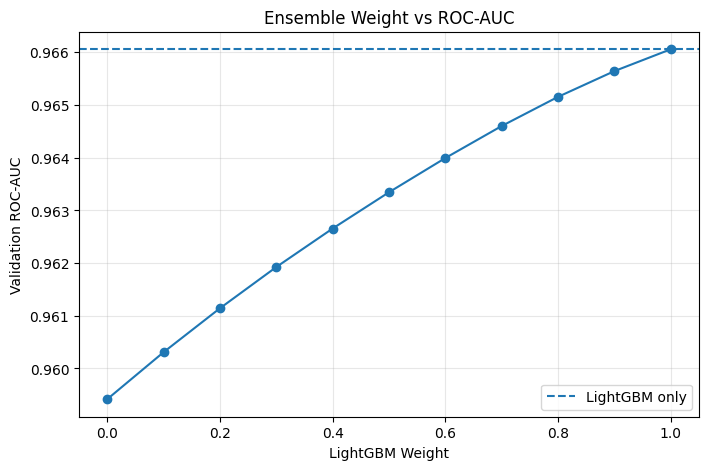

In [141]:
plt.figure(figsize=(8, 5))

plt.plot(
    ensemble_results["LightGBM_weight"],
    ensemble_results["ROC-AUC"],
    marker="o"
)

plt.axhline(
    y=roc_auc_score(y_valid, lgb_proba),
    linestyle="--",
    label="LightGBM only"
)

plt.xlabel("LightGBM Weight")
plt.ylabel("Validation ROC-AUC")
plt.title("Ensemble Weight vs ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### LightGBMとCatBoostのアンサンブル学習による予測性能の検証

**目的**

LightGBMとCatBoostの予測確率を加重平均することで、単独モデルよりもROC-AUCが向上するか検証した。

**検証方法**

LightGBMの重みを0.0〜1.0まで0.1刻みで変化させ、CatBoostの重みを「1 − LightGBMの重み」として設定した。

各組み合わせについて、同一の検証データを使用してROC-AUCおよびLog Lossを算出した。

**結果**

LightGBM単独のROC-AUCは0.966060、CatBoost単独は0.959415であった。

LightGBM 90%・CatBoost 10%の組み合わせではROC-AUCが0.965645となり、LightGBM単独を下回った。

その他の組み合わせでも改善は確認できず、Log LossについてもLightGBM単独が最良であった。

**考察**

今回の検証では、CatBoostを組み合わせることで予測性能が低下した。

LightGBMが元の特徴量から十分な予測情報を学習できている可能性や、CatBoostがLightGBMの予測誤差を十分に補完できていない可能性が考えられる。

ただし、モデル間の予測相関や誤分類の重複は未検証であるため、性能低下の原因は特定できない。

**結論**

今回検証した加重平均の範囲では、アンサンブル学習による予測性能の改善は確認できなかった。

そのため、最終モデルにはOptunaで最適化したLightGBM単独モデルを採用する。

## 航空会社の顧客満足度が決まる仕組みを仮説として考え、特徴量を作成する

In [142]:
# サービス評価の列
service_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

def add_features(df):
    df = df.copy()

    # ① サービス評価の最低値
    df["service_min"] = df[service_cols].min(axis=1)

    # ② サービス評価の標準偏差
    df["service_std"] = df[service_cols].std(axis=1)

    # ③ 到着遅延と出発遅延の差
    df["delay_recovery"] = (
        df["Arrival Delay in Minutes"]
        - df["Departure Delay in Minutes"]
    )

    # ④ 飛行距離に対する到着遅延
    df["delay_per_distance"] = (
        df["Arrival Delay in Minutes"]
        / (df["Flight Distance"] + 1)
    )

    return df

# 学習・検証データに適用
X_train_fe2 = add_features(X_train)
X_valid_fe2 = add_features(X_valid)

print("学習データ:", X_train_fe2.shape)
print("検証データ:", X_valid_fe2.shape)

学習データ: (559708, 25)
検証データ: (111942, 25)


In [143]:
new_features = [
    "service_min",
    "service_std",
    "delay_recovery",
    "delay_per_distance"
]

# Optuna最適化済みモデルを複製
lgb_fe2 = clone(lgb_tuned_final)

# 元の前処理を取得
old_preprocessor = lgb_fe2.named_steps["preprocessor"]

# 数値特徴量に新しい4列を追加
transformers = []

for name, transformer, columns in old_preprocessor.transformers:
    if name == "num":
        columns = list(columns) + new_features

    transformers.append((name, transformer, columns))

new_preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

lgb_fe2.set_params(preprocessor=new_preprocessor)

# 新しい25特徴量で学習
lgb_fe2.fit(X_train_fe2, y_train)

# 実際に使われている特徴量を確認
features = lgb_fe2.named_steps[
    "preprocessor"
].get_feature_names_out()

print("変換後の特徴量数:", len(features))

for feature in features:
    if any(f in feature for f in new_features):
        print("追加特徴量:", feature)

変換後の特徴量数: 30
追加特徴量: num__service_min
追加特徴量: num__service_std
追加特徴量: num__delay_recovery
追加特徴量: num__delay_per_distance


In [144]:
# 元のLightGBM
proba_base = lgb_tuned_final.predict_proba(
    X_valid
)[:, 1]

# 特徴量追加後のLightGBM
proba_fe2 = lgb_fe2.predict_proba(
    X_valid_fe2
)[:, 1]

comparison = pd.DataFrame({
    "Model": [
        "Baseline (21 features)",
        "Feature Engineering (25 features)"
    ],
    "ROC-AUC": [
        roc_auc_score(y_valid, proba_base),
        roc_auc_score(y_valid, proba_fe2)
    ],
    "Log Loss": [
        log_loss(y_valid, proba_base),
        log_loss(y_valid, proba_fe2)
    ]
})

display(comparison.round(6))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,ROC-AUC,Log Loss
0,Baseline (21 features),0.966060,0.216478
1,Feature Engineering (25 features),0.966447,0.215964


In [145]:
new_features = [
    "service_min",
    "service_std",
    "delay_recovery",
    "delay_per_distance"
]

results = []

# 全4特徴量を使用したモデルも比較対象に含める
feature_sets = {
    "All 4 features": new_features
}

# 1特徴量ずつ除外
for excluded in new_features:
    feature_sets[f"Without {excluded}"] = [
        f for f in new_features if f != excluded
    ]

for name, selected_features in feature_sets.items():

    model = clone(lgb_tuned_final)

    transformers = []

    for trans_name, transformer, columns in (
        model.named_steps["preprocessor"].transformers
    ):
        if trans_name == "num":
            columns = list(columns) + selected_features

        transformers.append(
            (trans_name, transformer, columns)
        )

    model.set_params(
        preprocessor=ColumnTransformer(
            transformers=transformers,
            remainder="drop"
        )
    )

    # 学習
    model.fit(X_train_fe2, y_train)

    # 検証
    proba = model.predict_proba(X_valid_fe2)[:, 1]

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_valid, proba),
        "Log Loss": log_loss(y_valid, proba)
    })

ablation_results = pd.DataFrame(results)

display(
    ablation_results.sort_values(
        "ROC-AUC", ascending=False
    ).round(6)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,ROC-AUC,Log Loss
4,Without delay_per_distance,0.966597,0.215757
3,Without delay_recovery,0.966518,0.215977
0,All 4 features,0.966447,0.215964
1,Without service_min,0.966320,0.216215
2,Without service_std,0.966183,0.216232


In [146]:
# 今回使用する2特徴量
selected_features = [
    "service_min",
    "service_std"
]

# モデルを複製
lgb_fe_best2 = clone(lgb_tuned_final)

# 前処理を更新
transformers = []

for name, transformer, columns in (
    lgb_fe_best2.named_steps["preprocessor"].transformers
):
    if name == "num":
        columns = list(columns) + selected_features

    transformers.append((name, transformer, columns))

lgb_fe_best2.set_params(
    preprocessor=ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )
)

# 学習
lgb_fe_best2.fit(X_train_fe2, y_train)

# 予測
proba_best2 = lgb_fe_best2.predict_proba(X_valid_fe2)[:, 1]

print("2特徴量追加モデル")
print("ROC-AUC:", round(roc_auc_score(y_valid, proba_best2), 6))
print("Log Loss:", round(log_loss(y_valid, proba_best2), 6))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


2特徴量追加モデル
ROC-AUC: 0.966494
Log Loss: 0.215953


### 特徴量エンジニアリングの検証結果（最終比較）

#### 目的
新たに作成した特徴量が、LightGBMの顧客満足度予測性能の向上に寄与するかを検証する。

#### 検証方法
Optunaでハイパーパラメータを最適化したLightGBMを使用し、元の21特徴量をベースラインとして、追加特徴量の組み合わせを変更しながら性能を比較した。

追加候補は以下の4特徴量とした。

- `service_min`：サービス評価の最低値
- `service_std`：サービス評価の標準偏差
- `delay_recovery`：到着遅延と出発遅延の差
- `delay_per_distance`：飛行距離に対する到着遅延

評価指標にはROC-AUCおよびLog Lossを使用した。

#### 検証結果

| モデル | ROC-AUC | Log Loss |
|---|---:|---:|
| ベースライン（21特徴量） | 0.966060 | 0.216478 |
| 4特徴量追加（25特徴量） | 0.966447 | 0.215964 |
| 3特徴量追加（24特徴量） | **0.966597** | **0.215757** |
| 2特徴量追加（23特徴量） | 0.966494 | 0.215953 |

※3特徴量モデル：`service_min`、`service_std`、`delay_recovery`

※2特徴量モデル：`service_min`、`service_std`

#### 考察
- 追加特徴量によって、ベースラインと比較してROC-AUCとLog Lossの両方が改善した。
- `service_min` と `service_std` は、サービス評価の全体的な特徴を捉えるうえで有効である可能性が示唆された。
- `delay_recovery` を追加した3特徴量モデルが最も高いROC-AUCを示した。
- `delay_per_distance` を除外することで性能が改善したため、今回の特徴量の組み合わせでは不要と判断した。
- ただし、改善幅は小さく、同じ検証データを繰り返し使用しているため、汎化性能の向上については慎重な判断が必要である。

#### 結論
今回の検証では、**元の21特徴量に `service_min`、`service_std`、`delay_recovery` を追加した24特徴量モデルが最良の結果**となった。

- ROC-AUC：0.966060 → **0.966597（+0.000537）**
- Log Loss：0.216478 → **0.215757（-0.000721）**

今後は、この24特徴量モデルをKaggleに提出し、Public Leaderboardのスコアを既存モデルと比較する。

In [147]:
# 追加する3特徴量
selected_features = [
    "service_min",
    "service_std",
    "delay_recovery"
]

# Optuna最適化済みモデルを複製
lgb_fe3 = clone(lgb_tuned_final)

transformers = []

for name, transformer, columns in (
    lgb_fe3.named_steps["preprocessor"].transformers
):
    if name == "num":
        columns = list(columns) + selected_features

    transformers.append((name, transformer, columns))

lgb_fe3.set_params(
    preprocessor=ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )
)

# 学習
lgb_fe3.fit(X_train_fe2, y_train)

# 検証
from sklearn.metrics import roc_auc_score

valid_proba = lgb_fe3.predict_proba(X_valid_fe2)[:, 1]

print("検証ROC-AUC:", roc_auc_score(y_valid, valid_proba))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


検証ROC-AUC: 0.9665971395160082


In [148]:
# テストデータに4特徴量を作成
X_test_fe2 = add_features(
    test.drop(columns=["id"], errors="ignore")
)

print("テストデータの形状:", X_test_fe2.shape)

テストデータの形状: (299844, 25)


In [149]:
# 満足する確率を予測
test_proba_fe3 = lgb_fe3.predict_proba(X_test_fe2)[:, 1]

print("予測件数:", len(test_proba_fe3))
print("予測確率の先頭5件:", test_proba_fe3[:5])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


予測件数: 299844
予測確率の先頭5件: [0.23628595 0.82872591 0.89415648 0.08399753 0.04414772]


In [150]:
submission_fe3 = pd.DataFrame({
    "id": test["id"],
    "satisfaction": test_proba_fe3
})

# データの検証
assert len(submission_fe3) == len(test)
assert submission_fe3["id"].equals(test["id"])
assert submission_fe3.isna().sum().sum() == 0
assert submission_fe3["satisfaction"].between(0, 1).all()

# CSV保存
submission_fe3.to_csv(
    "submission_fe3.csv",
    index=False
)

display(submission_fe3.head())

print("提出データの形状:", submission_fe3.shape)
print("欠損値:", submission_fe3.isna().sum().sum())

,id,satisfaction
0,699635,0.236286
1,699636,0.828726
2,699637,0.894156
3,699638,0.083998
4,699639,0.044148


提出データの形状: (299844, 2)
欠損値: 0


In [151]:
files.download("submission_fe3.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>